In [68]:
import matplotlib
from matplotlib.gridspec import GridSpec
import numpy as np
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
tab20c = plt.get_cmap('tab20c').colors
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from os.path import dirname, join as pjoin
import h5py
from math import *
import glob
import struct
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import statsmodels.api as sm
lowess = sm.nonparametric.lowess
import math
import pickle
import string
import pandas
import xarray as xr
import plotly.graph_objects as go
from matplotlib.colors import to_rgb, to_hex
from scipy.special import erfc
from scipy.stats import gaussian_kde
import csv
import itertools, math

plt.style.use('default')
mpl.rcParams['figure.dpi'] = 600
mpl.rcParams['axes.facecolor'] = (1,1,1,0)

def pastel(color, amount=0.5, alpha=1.):
    
    rgb = to_rgb(color)
    pastel_rgb = tuple((1 - amount) * c + amount for c in rgb)
    return f"rgba({int(pastel_rgb[0]*255)}, {int(pastel_rgb[1]*255)}, {int(pastel_rgb[2]*255)}, {alpha})"
    
def pastel_ar(color, amount=0.5, alpha=1.):
    
    rgb = to_rgb(color)
    pastel_rgb = tuple((1 - amount) * c + amount for c in rgb)
    return (pastel_rgb[0], pastel_rgb[1], pastel_rgb[2], alpha)

def weighted_median(values, weights):
    values = np.asarray(values)
    weights = np.asarray(weights)
    
    sorter = np.argsort(values)
    values_sorted = values[sorter]
    weights_sorted = weights[sorter]
    
    cum_weights = np.cumsum(weights_sorted)
    cum_weights /= cum_weights[-1]
    
    idx = np.searchsorted(cum_weights, 0.5)
    return values_sorted[idx]
    
base_col   = ["#1f77b4","#ff7f0e","#2ca02c"]
pastel_col = [pastel_ar(base_col[i], 0.45) for i in range(len(base_col))]

This notebook provides the analysis of the "Alltraits" run (in which the simulateneous evolution of all 3 traits is simulated) and "DD" run (in which all 3 traits are assumed to be perfectly adapted).

In [7]:
# Loads the outputs
TRAC_mutALL,FPP_mutALL = pickle.load(open('../runs_offline3D/OUTPUT/META-DATA/Alltraits_150y_ly.pickle','rb'))
TRAC_DDTLS,FPP_DDTLS   = pickle.load(open('../runs_offline3D/OUTPUT/META-DATA/DD_150y_ly.pickle','rb'))

# Spatio-temporal coordinates
lon      = np.linspace(0,360.000005,360)
lat      = np.linspace(-79.5,79.5,160)
lat_reel = np.linspace(-80,80,161)
lat_mat = np.transpose(([lat_reel[1:].tolist()]*len(lon)))
lon_mat = np.array(([lon.tolist()]*len(lat)))
delZ     = np.array([10.,10.,15.,20.,20.,25.,35.,50.])
depth    = np.cumsum(delZ)
upper_lim = [0]
for i in np.arange(len(delZ)): upper_lim += [upper_lim[-1]+delZ[i]]
upper_lim = np.array(upper_lim)
middle = upper_lim[:-1]+(upper_lim[1:]-upper_lim[:-1])/2
Surf = np.transpose(np.array([(np.sin(lat_reel[1:]/360*2*pi)-np.sin(lat_reel[:-1]/360*2*pi))*2*pi/360*6378137**2 for j in np.arange(0,360,1)]))

# PP, depth integrated PP, globally integrated PP for the 2 scenarios
FPP_mutALL     = np.ma.masked_array(FPP_mutALL,mask=FPP_mutALL<=1e-40)
Int_FPP_mutALL = np.ma.sum(delZ[None,:,None,None]*FPP_mutALL,1)
FPP_mutALL_zt  = np.ma.sum(delZ[None,:,None,None]*FPP_mutALL,(0,1))/12
tot_FPP_mutALL = np.ma.sum(np.ma.sum(Surf[None,:,:]*Int_FPP_mutALL*60*60*24*360,1),1)/1e15/1e3*12 #Gt C y-1

FPP_DDTLS      = np.ma.masked_array(FPP_DDTLS,mask=FPP_DDTLS<=1e-40)
Int_FPP_DDTLS  = np.ma.sum(delZ[None,:,None,None]*FPP_DDTLS,1)
FPP_DDTLS_zt   = np.ma.sum(delZ[None,:,None,None]*FPP_DDTLS,(0,1))/12
tot_FPP_DDTLS  = np.ma.sum(np.ma.sum(Surf[None,:,:]*Int_FPP_DDTLS*60*60*24*360,1),1)/1e15/1e3*12 #Gt C y-1

Surf = np.ma.masked_array(Surf,mask=np.ma.getmask(FPP_mutALL[0,0,:,:]))

# Loads all relevant variables for the 2 scenarios
R_Ch        = 16/120                                                                                # C:Chl ratio
C_mutALL    = np.ma.masked_array(TRAC_mutALL[:,5,:,:,:],mask=np.ma.getmask(FPP_mutALL))             # Phyto biomass (mmol C.m-3)
Ch_mut_ALL  = C_mutALL*R_Ch                                                                         # Chl (mmol Chl.m-3)                 
Size_mutALL = np.ma.masked_array(TRAC_mutALL[:,6,:,:,:]/C_mutALL,mask=np.ma.getmask(FPP_mutALL))    # Size (log(µm3))
Topt_mutALL = np.ma.masked_array(TRAC_mutALL[:,7,:,:,:]/C_mutALL,mask=np.ma.getmask(FPP_mutALL))    # Topt (°C)
Lopt_mutALL = np.ma.masked_array(TRAC_mutALL[:,8,:,:,:]/C_mutALL,mask=np.ma.getmask(FPP_mutALL))    # PARopt (log(µEin.m-2.s-1))
VS_mutALL   = np.ma.masked_array(TRAC_mutALL[:,9,:,:,:]/C_mutALL - Size_mutALL**2,mask=np.ma.getmask(FPP_mutALL))    # Var(Size) (log(µm3)**2)
NO3_mutALL  = np.ma.masked_array(TRAC_mutALL[:,0,:,:,:],mask=np.ma.getmask(FPP_mutALL))             # [NO3] (mmol N.m-3)
NO2_mutALL  = np.ma.masked_array(TRAC_mutALL[:,1,:,:,:],mask=np.ma.getmask(FPP_mutALL))             # [NO2] (mmol N.m-3)         
NH4_mutALL  = np.ma.masked_array(TRAC_mutALL[:,2,:,:,:],mask=np.ma.getmask(FPP_mutALL))             # [NH4] (mmol N.m-3)
P_mutALL    = np.ma.masked_array(TRAC_mutALL[:,3,:,:,:],mask=np.ma.getmask(FPP_mutALL))             # [PO4] (mmol N.m-3)
F_mutALL    = np.ma.masked_array(TRAC_mutALL[:,4,:,:,:],mask=np.ma.getmask(FPP_mutALL))             # [Fe] (mmol N.m-3)


C_DDTLS     = np.ma.masked_array(TRAC_DDTLS[:,5,:,:,:],mask=np.ma.getmask(FPP_DDTLS))
Ch_DDTLS    = C_DDTLS*R_Ch
Size_DDTLS  = np.ma.masked_array(TRAC_DDTLS[:,6,:,:,:]/C_DDTLS,mask=np.ma.getmask(FPP_DDTLS))
Topt_DDTLS  = np.ma.masked_array(TRAC_DDTLS[:,7,:,:,:]/C_DDTLS,mask=np.ma.getmask(FPP_DDTLS))
Lopt_DDTLS  = np.ma.masked_array(TRAC_DDTLS[:,8,:,:,:]/C_DDTLS,mask=np.ma.getmask(FPP_DDTLS))
NO3_DDTLS   = np.ma.masked_array(TRAC_DDTLS[:,0,:,:,:],mask=np.ma.getmask(FPP_DDTLS))
NO2_DDTLS   = np.ma.masked_array(TRAC_DDTLS[:,1,:,:,:],mask=np.ma.getmask(FPP_DDTLS))
NH4_DDTLS   = np.ma.masked_array(TRAC_DDTLS[:,2,:,:,:],mask=np.ma.getmask(FPP_DDTLS))
P_DDTLS     = np.ma.masked_array(TRAC_DDTLS[:,3,:,:,:],mask=np.ma.getmask(FPP_DDTLS))
F_DDTLS     = np.ma.masked_array(TRAC_DDTLS[:,4,:,:,:],mask=np.ma.getmask(FPP_DDTLS))

# Loads temperatures
input_list = sorted(glob.glob('../runs_offline3D/input/iter177/Dynvars2_ave/DDtheta.*.data'))
NA_vec     = []
T          = []
for j in input_list:
    file = open(j, 'rb')
    temp_grid = []
    for i in range(360*160*23):
        temp_grid += [struct.unpack('>f',file.read(4))[0]]    
    temp_grid = np.reshape(temp_grid,(23,160,360))
    file.close()
    T += [temp_grid]
T    = np.ma.masked_array(np.array(T)[:,:8,:,:],mask=np.ma.getmask(FPP_mutALL))

# Loads PAR
file = open('../runs_offline3D/input/PAR/MITesm3D_PAReday.bin','rb')

PAR_grid = []
for i in range(12*360*160):
    PAR_grid += [struct.unpack('>f',file.read(4))]
  
PAR_grid = np.reshape(PAR_grid,(12,160,360))
PAR_surf = np.array(PAR_grid)*11.574

PAR   = np.zeros(shape=np.shape(C_mutALL))
PAR_k = PAR_surf
mid_depth = (depth-delZ/2)
for i in range(len(mid_depth)):
    PAR[:,i,:,:] = PAR_k * np.exp(-(0.04+Ch_mut_ALL[:,i,:,:]*0.03)*delZ[i]/2)
    PAR_k = (PAR_k * np.exp(-(0.04+Ch_mut_ALL[:,i,:,:]*0.03)*delZ[i]))
PAR_mutALL = np.ma.masked_array(PAR,mask=np.ma.getmask(FPP_DDTLS))
PAR_mutALL[PAR_mutALL < 1e-10] = 1e-10
PAR_z = np.ma.sum(PAR_mutALL*C_mutALL*delZ[None,:,None,None],(1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(1)) 

# Loads nutrient limitation
a_KN = 0.17
a_KP = 0.026
a_KF = 8e-5
b_KN = 0.27
b_KP = 0.27
b_KF = 0.27
Nut_lim_mutALL   = np.argmax(np.array([a_KN/(NO3_mutALL+NO2_mutALL+NH4_mutALL),a_KP/P_mutALL,a_KF/F_mutALL]),0)
nut_lim_mutALL   = np.ma.max(np.array([a_KN/(NO3_mutALL+NO2_mutALL+NH4_mutALL),a_KP/P_mutALL,a_KF/F_mutALL]),0)
mask = np.ma.getmaskarray(FPP_mutALL).copy()
a_K_mat = np.array(np.copy(Nut_lim_mutALL),dtype='float64')
a_K_mat[Nut_lim_mutALL == 0.] = a_KN
a_K_mat[Nut_lim_mutALL == 1.] = a_KP
a_K_mat[Nut_lim_mutALL == 2.] = a_KF
a_K_mat = np.ma.masked_array(a_K_mat,mask=mask)
nut_lim = np.ma.masked_array(np.copy(Nut_lim_mutALL),mask=np.ma.getmask(FPP_DDTLS),dtype='float64')
nut_lim[Nut_lim_mutALL == 0.] = (NO2_mutALL+NO3_mutALL+NH4_mutALL)[Nut_lim_mutALL == 0.]
nut_lim[Nut_lim_mutALL == 1.] = (P_mutALL)[Nut_lim_mutALL == 1.]
nut_lim[Nut_lim_mutALL == 2.] = (F_mutALL)[Nut_lim_mutALL == 2.]

# NPP

In [4]:
input_list = sorted(glob.glob('DATA/vgpm.m.2023/vgpm.202*'))

NPP = []
for i in input_list:
    f = h5py.File(i, 'r')
    NPP += [np.asarray(f['npp']).tolist()]

NPP = np.ma.array(NPP,mask=NPP==np.min(NPP))         

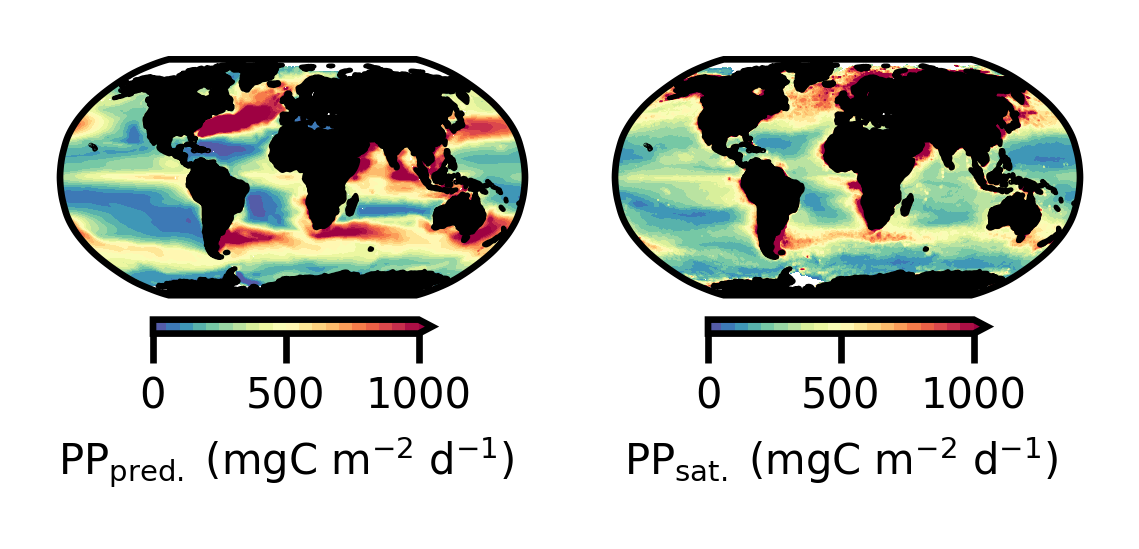

In [5]:
fig = plt.figure(figsize=(2,1.25))  # largeur augmentée pour 2 colonnes

ax1 = fig.add_subplot(121,facecolor='none',projection=ccrs.Robinson(central_longitude = 0))
cmap = plt.get_cmap('Spectral_r').copy()
cmap.set_bad(color='black')
p1 = ax1.contourf(lon,lat,np.ma.sum(Int_FPP_mutALL,0)*60*60*24,np.linspace(0,1000,21),cmap=cmap,extend='max',transform=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,500,1000])
c1.ax.set_xticklabels([0,500,1000],fontsize=5)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('PP$_{\mathrm{pred.}}$ (mgC m$^{-2}$ d$^{-1}$)',rotation=0,fontsize=5,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(122,facecolor='none',projection=ccrs.Robinson(central_longitude = 0))
cmap = plt.get_cmap('Spectral_r').copy()
cmap.set_bad(color='black')
lon_NPP = np.linspace(0,360,432)-180
lat_NPP = np.linspace(-90,90,216)
p1 = ax1.contourf(lon_NPP,-lat_NPP,np.ma.mean(NPP,0)[::10,::10],np.linspace(0,1000,21),cmap=cmap,extend='max',transform=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,500,1000])
c1.ax.set_xticklabels([0,500,1000],fontsize=5)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('PP$_{\mathrm{sat.}}$ (mgC m$^{-2}$ d$^{-1}$)',rotation=0,fontsize=5,labelpad=2)
ax1.set_global()

fig.tight_layout()
plt.show()

# NO$_3$

In [6]:
NO3 = []
with open('DATA/woa23_all_n00an01.csv') as f:
    reader = csv.reader(f)
    k = 0
    for line in reader:
        k += 1
        if len(line) < 104:
            line += [float(nan)]*(104-len(line))
        NO3 += [line]

NO3 = np.array(NO3)
NO3[NO3 == "'NaN'"] = float(nan)
NO3[NO3 == ''] = float(nan)
NO3 = NO3[2:,:]
NO3 = np.array(NO3,dtype=np.float64)

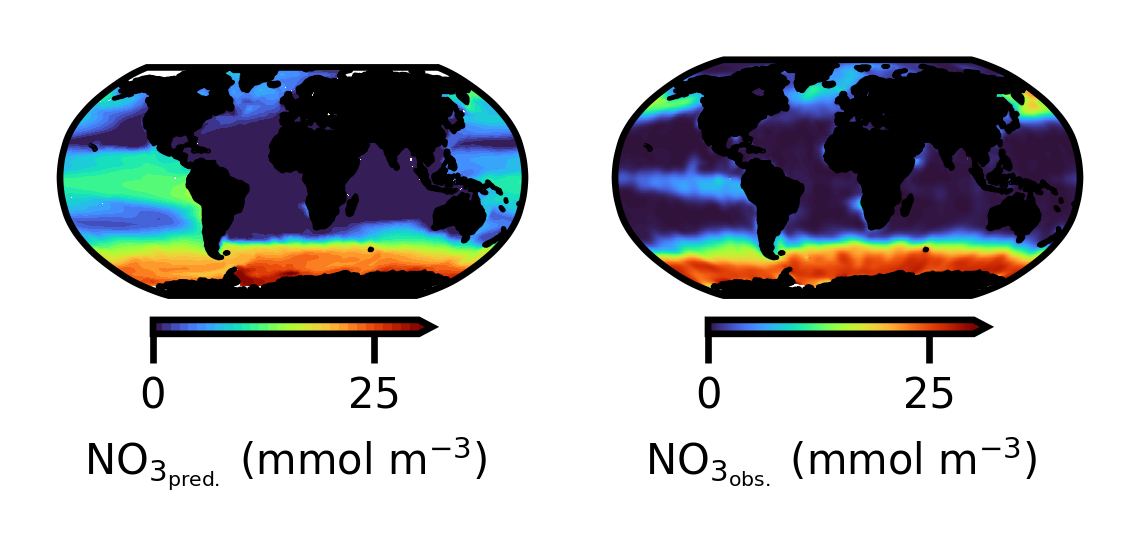

In [8]:
fig = plt.figure(figsize=(2,1.25))  # largeur augmentée pour 2 colonnes

ax1 = fig.add_subplot(121,facecolor='none',projection=ccrs.Robinson(central_longitude = 0))
cmap = plt.get_cmap('turbo').copy()
p1 = ax1.contourf(lon,lat,np.mean(NO3_mutALL,0)[0,:,:],np.linspace(0,30,31),cmap=cmap,extend='max',transform=ccrs.PlateCarree())
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1.ax.set_xticks([0,25])
c1.ax.set_xticklabels([0,25],fontsize=5)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('NO$_{3_{\mathrm{pred.}}}$ (mmol m$^{-3}$)',rotation=0,fontsize=5,labelpad=2)

ax1 = fig.add_subplot(122,facecolor='none',projection=ccrs.Robinson(central_longitude = 0))
cmap = plt.get_cmap('turbo').copy()
sc = ax1.scatter(NO3[:,1],NO3[:,0],s=0.1,c=np.mean(NO3[:,2:4],1),vmin=0,vmax=30,lw=0,cmap=cmap,transform=ccrs.PlateCarree())
c1 = fig.colorbar(sc,shrink=0.60,orientation='horizontal',pad=0.05,extend='max')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1.ax.set_xticks([0,25])
c1.ax.set_xticklabels([0,25],fontsize=5)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('NO$_{3_{\mathrm{obs.}}}$ (mmol m$^{-3}$)',rotation=0,fontsize=5,labelpad=2)

fig.tight_layout()
fig.savefig('FigS1.pdf')

# Trait distribution:

First we look at the trait distributions.

In [10]:
# Vertically and annually averaged (biomass weighted) Topt
Topt_mutALL_z       = np.ma.sum(Topt_mutALL*C_mutALL*delZ[None,:,None,None],(0))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0))
Topt_mutALL_zt      = np.ma.sum(Topt_mutALL*C_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))
T_z                 = np.ma.sum(T*C_mutALL*delZ[None,:,None,None],(0))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0))
T_zt                = np.ma.sum(T*C_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))

# Vertically and annually averaged (biomass weighted) logSize and logESD
logESD_mutALL       = np.log((3/4*1/np.pi*np.exp(Size_mutALL))**(1/3)*2)
logESD_mutALL_zt    = np.ma.sum(logESD_mutALL*C_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))
logSize_mutALL_zt   = np.ma.sum(Size_mutALL*C_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))

# Vertically and annually averaged (biomass weighted) logPARopt
logLopt_mutALL_zt   = np.ma.sum(Lopt_mutALL*C_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))

## - $\mathrm{T_{opt}}$: 
Map of the vertically and annually averaged depth integrated Topt (left) ; Model vs. data (right) 

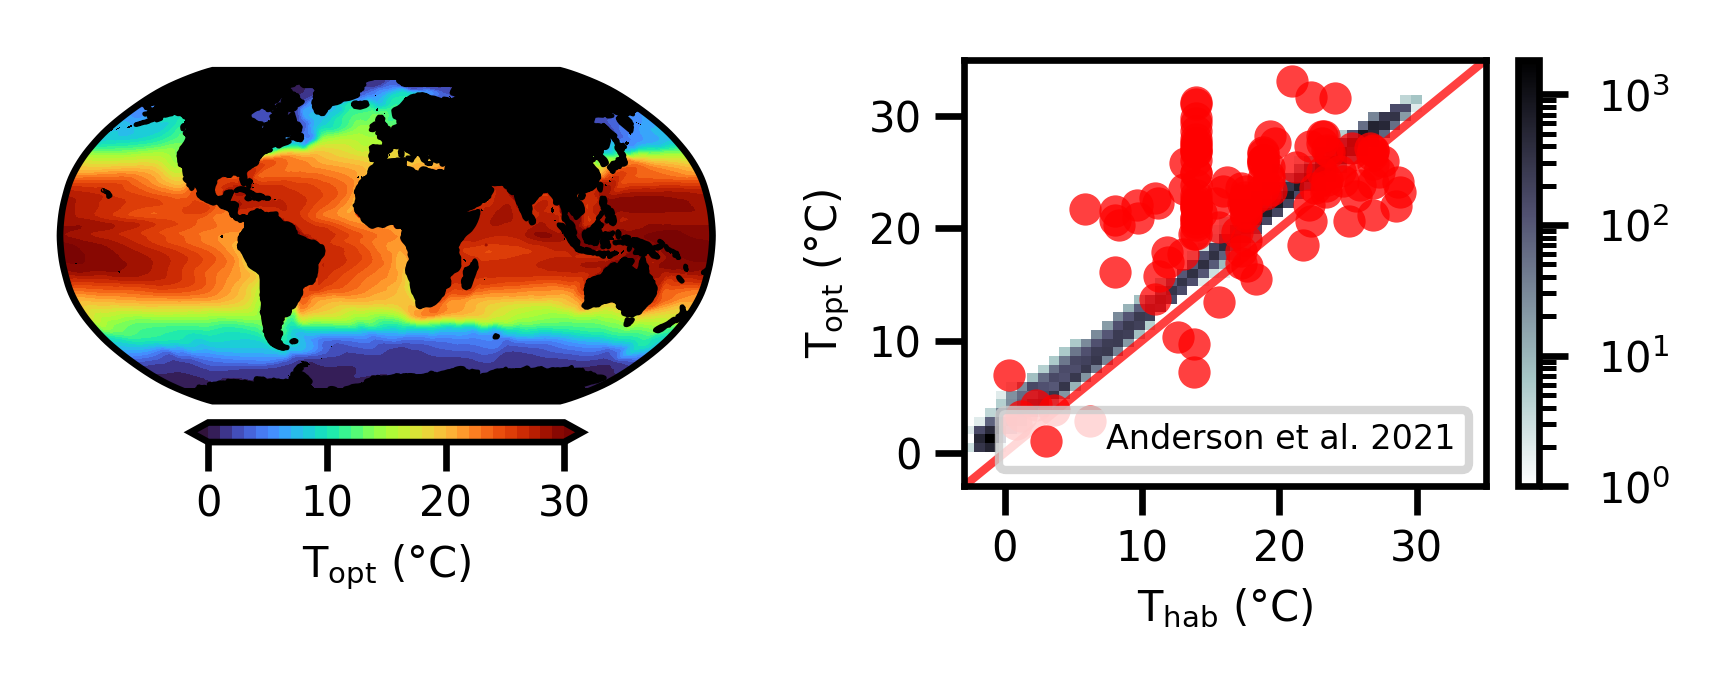

In [11]:
# Loads data from Anderson et al. 2021
df_cap = pandas.DataFrame(pandas.read_csv('DATA/Biology/dataset-839713_thermal-capacities__v1.tsv', sep='\t'))
df_mod = pandas.DataFrame(pandas.read_csv('DATA/Biology/dataset-839689_modeled-thermal-traits__v1.tsv', sep='\t'))
df_mod = df_mod[(df_mod['minqual'] == 'good') & (df_mod['maxqual'] == 'good')]
df_mod = df_mod[(np.isin(df_mod['isolate_code'],df_cap['isolate_code']))]
df_cap = df_cap[(np.isin(df_cap['isolate_code'],df_mod['isolate_code']))]

fig = plt.figure(figsize=(3,1.25))  # largeur augmentée pour 2 colonnes

ax1 = fig.add_subplot(121,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,Topt_mutALL_zt,np.arange(0,31,1),transform=ccrs.PlateCarree(),cmap='turbo',extend='both')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,10,20,30])
c1.ax.set_xticklabels([0,10,20,30],fontsize=5)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('T$\mathrm{_{opt}}$ (°C)',rotation=0,fontsize=5,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(122,facecolor='white')
A = T_zt[T_zt.mask==False]
B = Topt_mutALL_zt[Topt_mutALL_zt.mask==False]
h = ax1.hist2d(A,B,[np.linspace(-3,35),np.linspace(-3,35)],norm=mpl.colors.LogNorm(),cmap='bone_r')
c1 = plt.colorbar(h[3],ax=ax1)
ax1.scatter(df_cap['Thab_past'],df_mod['mu_g_opt_list'],c='red',linewidth=0,s=15,alpha=0.75,label='Anderson et al. 2021')
ax1.plot([-3,35],[-3,35],lw=1,c='red',alpha=0.75)
ax1.tick_params(labelsize=5,pad=1.5)
c1.ax.tick_params(labelsize=5)
ax1.set_ylabel('T$_{\mathrm{opt}}$ (°C)',fontsize=5,labelpad=2)
ax1.set_xlabel('T$_{\mathrm{hab}}$ (°C)',fontsize=5,labelpad=2)
plt.legend(loc='lower right',fontsize=4)

fig.tight_layout()
plt.show()

## - Size
Map of the vertically and annually averaged ESD (left) ; Model vs. data (middle and right)

/var/folders/fm/8kc1yt4n3mncnjr5dr0_558m0000gp/T/ipykernel_33177/373569788.py:29: RuntimeWarning: divide by zero encountered in log
  x2 = np.exp((np.log(x)+2.42)/1.49)


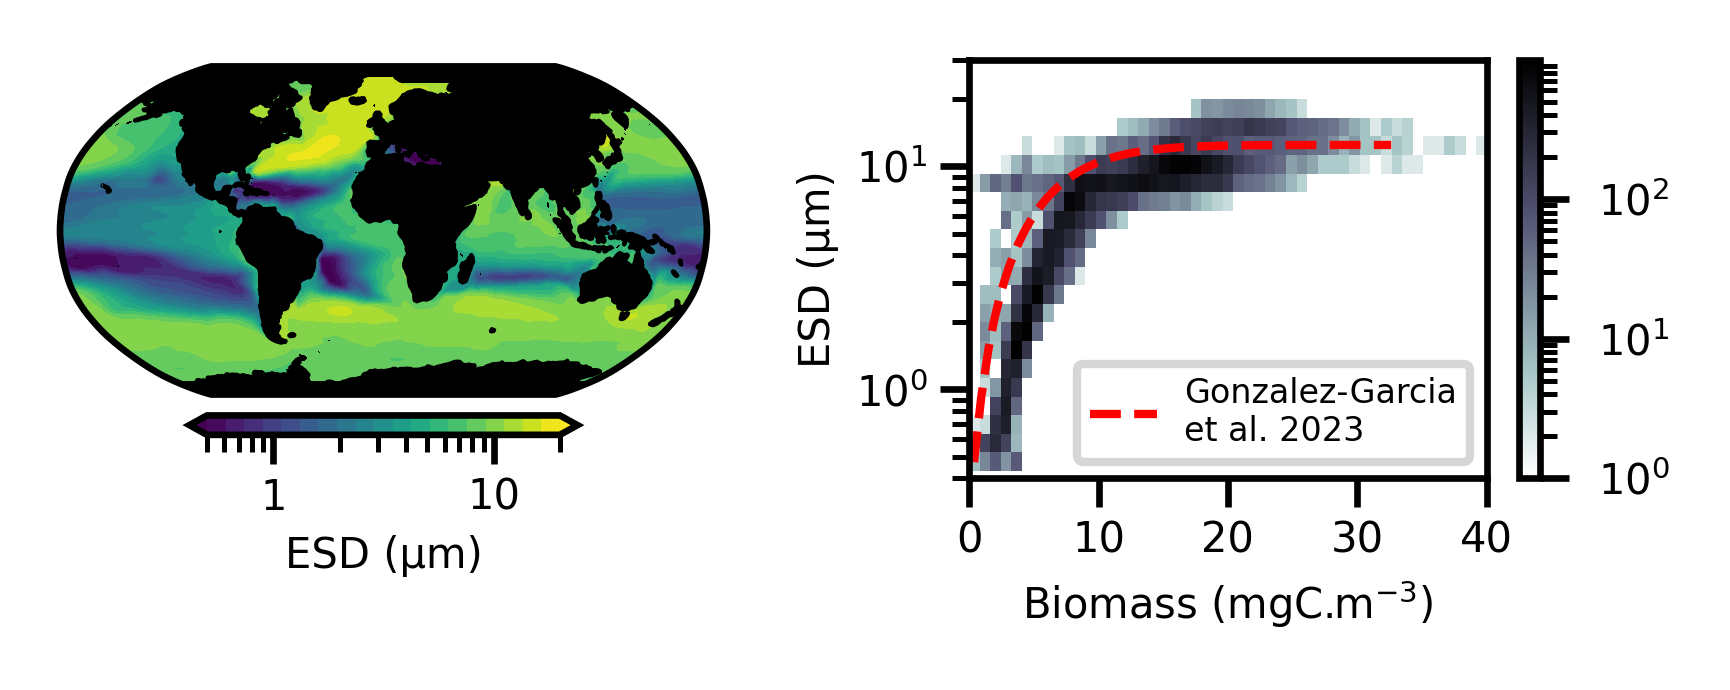

In [13]:
# Loads PP data from Kostadinov et al.
df = xr.open_dataset("../../../../Kostadinov_data/ESACCI-OC-L3S-MERGED_OVERALL_CLIM_4km_Mapped_PSD_PSC_199709-202012-fv5.0.nc")
microFrac = np.asarray(df.Microphytoplankton_carbon_fraction)
microFrac = np.ma.array(df.Microphytoplankton_carbon_fraction,mask=microFrac==float('nan'))

fig = plt.figure(figsize=(3,1.25))  # largeur augmentée pour 2 colonnes

ax1 = fig.add_subplot(121,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,np.exp(logESD_mutALL_zt),10**np.linspace(np.log10(0.5),np.log10(20),20),transform=ccrs.PlateCarree(),cmap='viridis',extend='both',norm=mpl.colors.LogNorm())
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([1,10],minor=False)
c1.ax.set_xticklabels([1,10],fontsize=5)
c1.ax.set_xticks((np.arange(5,10)/10).tolist()+np.arange(1,10).tolist()+[20],minor=True)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('ESD (µm)',rotation=0,fontsize=5,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(122,facecolor='white')
A = (np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))/np.sum(delZ))[logESD_mutALL_zt.mask==False]
#B = ((3/4*1/np.pi*np.exp(logSize_mutALL_zt))**(1/3)*2)[logESD_mutALL_zt.mask==False]
B = np.exp(logESD_mutALL_zt)[logESD_mutALL_zt.mask==False]
h=ax1.hist2d(A,B,(np.linspace(0,40,50),10**np.linspace(np.log10(0.2),np.log10(20),25)),norm=mpl.colors.LogNorm(),cmap='bone_r')
ax1.set_yscale('log')
ax1.set_ylim(0.4,30)
ax1.set_xlim(0,40)
c1 = plt.colorbar(h[3],ax=ax1)
x = np.linspace(0,16,200)
x2 = np.exp((np.log(x)+2.42)/1.49)
y = 0.30 + 12.18*(1-np.exp(-0.65*x))
ax1.plot(x2,y,c='red',ls='--',lw=1,label='Gonzalez-Garcia\net al. 2023')
plt.legend(loc='lower right',fontsize=4)
ax1.tick_params(labelsize=5,pad=1.5)
c1.ax.tick_params(labelsize=5)
ax1.set_ylabel('ESD (µm)',labelpad=2,fontsize=5)
ax1.set_xlabel('Biomass (mgC.m$^{-3}$)',labelpad=2,fontsize=5)

fig.tight_layout()
plt.show()

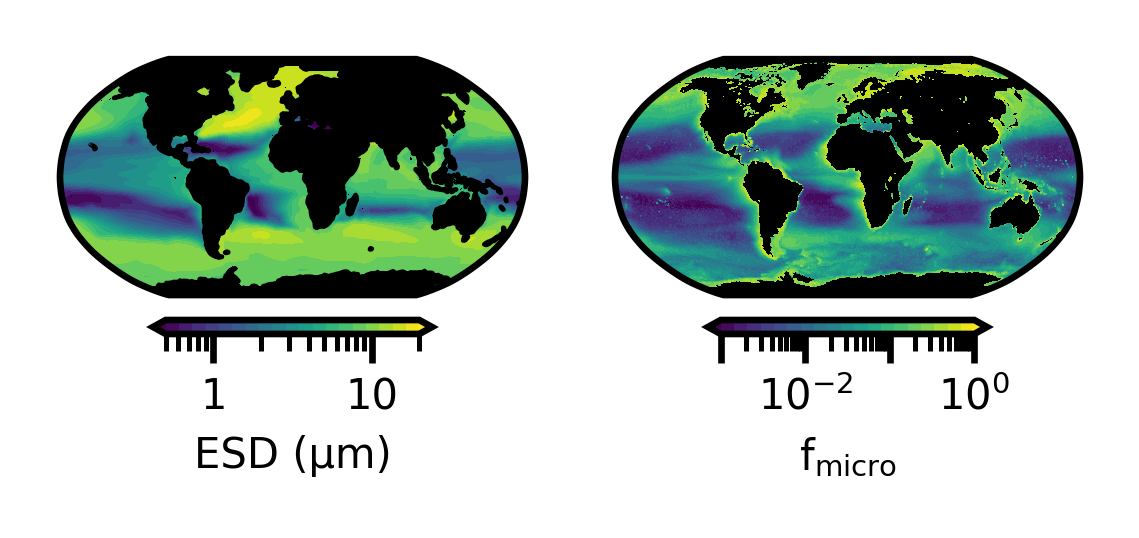

In [17]:
fig = plt.figure(figsize=(2,1.25))  # largeur augmentée pour 2 colonnes

ax1 = fig.add_subplot(121,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,np.exp(logESD_mutALL_zt),10**np.linspace(np.log10(0.5),np.log10(20),20),transform=ccrs.PlateCarree(),cmap='viridis',extend='both',norm=mpl.colors.LogNorm())
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([1,10],minor=False)
c1.ax.set_xticklabels([1,10],fontsize=5)
c1.ax.set_xticks((np.arange(5,10)/10).tolist()+np.arange(1,10).tolist()+[20],minor=True)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('ESD (µm)',rotation=0,fontsize=5,labelpad=2)
ax1.set_global()

M   = np.transpose(np.flip(np.flip(microFrac[::10,::10]),0))
Lon = np.linspace(0,360,np.shape(M)[1])
Lat = np.linspace(-90,90,np.shape(M)[0])
ax1 = fig.add_subplot(122,facecolor='black',projection=ccrs.Robinson(central_longitude=180))
p1 = ax1.contourf(Lon,Lat,M,10**np.linspace(-3,0,20),transform=ccrs.PlateCarree(),cmap='viridis',norm=mpl.colors.LogNorm(0.001,1),extend='both')
#ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([1e-3,1e-2,1e-1,1],minor=False)
c1.ax.set_xticklabels(['','10$^{-2}$','','10$^{0}$'],minor=False)
c1.ax.set_xticks((np.arange(1,10)*1e-3).tolist()+(np.arange(1,10)*1e-2).tolist()+(np.arange(1,10)*1e-1).tolist(),minor=True)
c1.ax.tick_params(labelsize=5)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('f$_{\mathrm{micro}}$',rotation=0,fontsize=5,labelpad=2)
ax1.set_global()

fig.tight_layout()
plt.show()

## - $\mathrm{PAR_{opt}}$
Map of the vertically and annually averaged PARopt (left) ; Trait vs. Optimal trait (right)

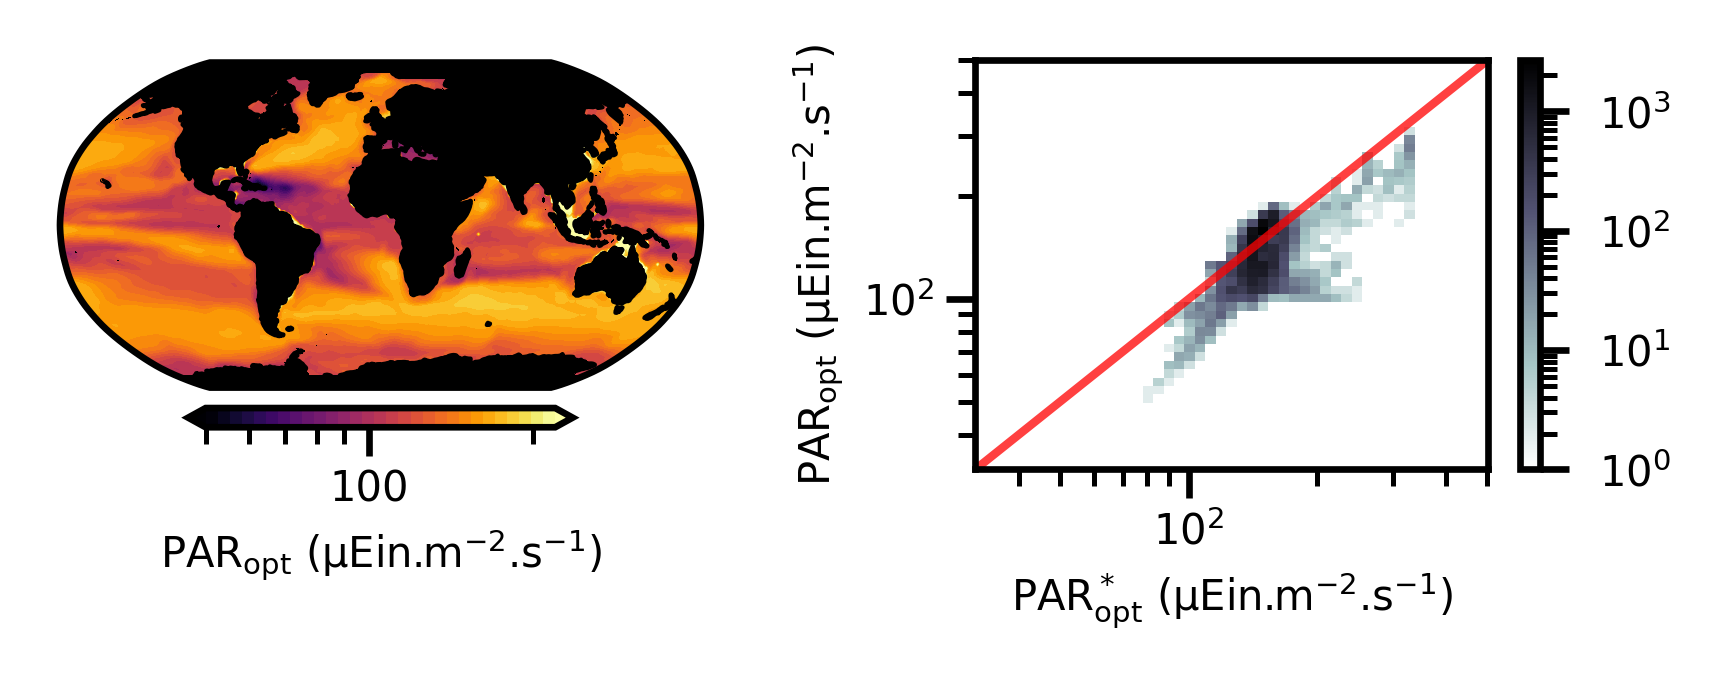

In [19]:
# Evaluate the optimal value of PARopt:
def PAR_opt_star_func(size,l): 
    Kpar   = 20*size**0.1
    PARopt = Kpar + np.sqrt(Kpar**2 + 1.2*Kpar*l + l**2)
    return PARopt
    
PAR_opt_star = PAR_opt_star_func(np.exp(Size_mutALL),PAR)
PAR_opt_star_zt = np.ma.sum(PAR_opt_star*C_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))
PAR_zt = np.ma.sum(PAR*C_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))

fig = plt.figure(figsize=(3,1.25))  # largeur augmentée pour 2 colonnes

ax1 = fig.add_subplot(121,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,np.exp(logLopt_mutALL_zt),10**np.linspace(np.log10(50),np.log10(220),30),transform=ccrs.PlateCarree(),cmap='inferno',extend='both',norm=mpl.colors.LogNorm())
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([100],minor=False)
c1.ax.set_xticks((np.arange(5,10)*10).tolist()+(np.arange(1,3)*100).tolist(),minor=True)
c1.ax.set_xticklabels([100],fontsize=5)
c1.ax.set_xticklabels([100],fontsize=5,minor=False)
c1.ax.set_xticklabels([],fontsize=5,minor=True)
c1.ax.tick_params(labelsize=5)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('PAR$_{\mathrm{opt}}$ (µEin.m$^{-2}$.s$^{-1}$)',rotation=0,fontsize=5,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(122,facecolor='white')
B = np.exp(logLopt_mutALL_zt).ravel()
A = PAR_opt_star_zt.ravel()
h = ax1.hist2d(A,B,[10**np.linspace(1.5,2.7,50),10**np.linspace(1.5,2.7,50)],norm=mpl.colors.LogNorm(),cmap='bone_r')
c1 = plt.colorbar(h[3],ax=ax1)
ax1.plot([1,1000],[1,1000],lw=1,c='red',alpha=0.75)
ax1.tick_params(labelsize=5,pad=1.5)
c1.ax.tick_params(labelsize=5)
ax1.set_ylabel('PAR$_{\mathrm{opt}}$ (µEin.m$^{-2}$.s$^{-1}$)',fontsize=5,labelpad=2)
ax1.set_xlabel('PAR$_{\mathrm{opt}}^*$ (µEin.m$^{-2}$.s$^{-1}$)',fontsize=5,labelpad=2)
ax1.set_yscale('log')
ax1.set_xscale('log')

fig.tight_layout()
plt.show()

fig.tight_layout()
plt.show()

## - Functional profiles

In [22]:
weight = np.ma.masked_array(np.broadcast_to(Surf, logESD_mutALL.shape),mask=np.ma.getmask(logESD_mutALL))[:,:,np.abs(lat_mat)<10].compressed()
ker_eq   = gaussian_kde(np.array([np.exp(logESD_mutALL[:,:,np.abs(lat_mat)<10].compressed()),Topt_mutALL[:,:,np.abs(lat_mat)<10].compressed()]))#,weights=weight)
X, Y = np.mgrid[np.log10(0.25):np.log10(20):100j, 0:35:100j]
coord_eq = np.vstack([10**X.ravel(), Y.ravel()])
KDE_ST_eq   = np.reshape(ker_eq(coord_eq).T,X.shape)

ker_eq   = gaussian_kde(np.array([np.exp(logESD_mutALL[:,:,np.abs(lat_mat)<10].compressed()),np.exp(Lopt_mutALL[:,:,np.abs(lat_mat)<10].compressed())]))#,weights=weight)
X, Y = np.mgrid[np.log10(0.25):np.log10(20):100j, np.log10(30):np.log10(250):100j]
coord_eq = np.vstack([10**X.ravel(), 10**Y.ravel()])
KDE_SP_eq   = np.reshape(ker_eq(coord_eq).T,X.shape)

ker_eq   = gaussian_kde(np.array([Topt_mutALL[:,:,np.abs(lat_mat)<10].compressed(),np.exp(Lopt_mutALL[:,:,np.abs(lat_mat)<10].compressed())]))#,weights=weight)
X, Y = np.mgrid[0:35:100j, np.log10(30):np.log10(250):100j]
coord_eq = np.vstack([X.ravel(), 10**Y.ravel()])
KDE_TP_eq   = np.reshape(ker_eq(coord_eq).T,X.shape)


weight = np.ma.masked_array(np.broadcast_to(Surf, logESD_mutALL.shape),mask=np.ma.getmask(logESD_mutALL))[:,:,(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed()
ker_st   = gaussian_kde(np.array([np.exp(logESD_mutALL[:,:,(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed()),Topt_mutALL[:,:,(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed()]))#,weights=weight)
coord_st = np.vstack([10**X.ravel(), Y.ravel()])
KDE_ST_st   = np.reshape(ker_st(coord_st).T,X.shape)

ker_st   = gaussian_kde(np.array([np.exp(logESD_mutALL[:,:,(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed()),np.exp(Lopt_mutALL[:,:,(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed())]))#,weights=weight)
coord_st = np.vstack([10**X.ravel(), 10**Y.ravel()])
KDE_SP_st   = np.reshape(ker_st(coord_st).T,X.shape)

ker_st   = gaussian_kde(np.array([Topt_mutALL[:,:,(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed(),np.exp(Lopt_mutALL[:,:,(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed())]))#,weights=weight)
coord_st = np.vstack([X.ravel(), 10**Y.ravel()])
KDE_TP_st   = np.reshape(ker_st(coord_st).T,X.shape)


weight = np.ma.masked_array(np.broadcast_to(Surf, logESD_mutALL.shape),mask=np.ma.getmask(logESD_mutALL))[:,:,np.abs(lat_mat)>30].compressed()
ker_hl   = gaussian_kde(np.array([np.exp(logESD_mutALL[:,:,np.abs(lat_mat)>30].compressed()),Topt_mutALL[:,:,np.abs(lat_mat)>30].compressed()]))#,weights=weight)
coord_hl = np.vstack([10**X.ravel(), Y.ravel()])
KDE_ST_hl   = np.reshape(ker_hl(coord_hl).T,X.shape)

ker_hl   = gaussian_kde(np.array([np.exp(logESD_mutALL[:,:,np.abs(lat_mat)>30].compressed()),np.exp(Lopt_mutALL[:,:,np.abs(lat_mat)>30].compressed())]))#,weights=weight)
coord_hl = np.vstack([10**X.ravel(), 10**Y.ravel()])
KDE_SP_hl   = np.reshape(ker_hl(coord_hl).T,X.shape)

ker_hl   = gaussian_kde(np.array([Topt_mutALL[:,:,np.abs(lat_mat)>30].compressed(),np.exp(Lopt_mutALL[:,:,np.abs(lat_mat)>30].compressed())]))#,weights=weight)
coord_hl = np.vstack([X.ravel(), 10**Y.ravel()])
KDE_TP_hl   = np.reshape(ker_hl(coord_hl).T,X.shape)

In [23]:
ker_eq   = gaussian_kde(np.array([np.exp(logESD_mutALL_zt[np.abs(lat_mat)<10].compressed()),Topt_mutALL_zt[np.abs(lat_mat)<10].compressed()]))#,weights=weight)
X, Y = np.mgrid[np.log10(0.25):np.log10(20):100j, 0:35:100j]
coord_eq = np.vstack([10**X.ravel(), Y.ravel()])
KDE_ST_eq   = np.reshape(ker_eq(coord_eq).T,X.shape)

ker_eq   = gaussian_kde(np.array([np.exp(logESD_mutALL_zt[np.abs(lat_mat)<10].compressed()),np.exp(logLopt_mutALL_zt[np.abs(lat_mat)<10].compressed())]))#,weights=weight)
X, Y = np.mgrid[np.log10(0.25):np.log10(20):100j, np.log10(30):np.log10(250):100j]
coord_eq = np.vstack([10**X.ravel(), 10**Y.ravel()])
KDE_SP_eq   = np.reshape(ker_eq(coord_eq).T,X.shape)

ker_eq   = gaussian_kde(np.array([Topt_mutALL_zt[np.abs(lat_mat)<10].compressed(),np.exp(logLopt_mutALL_zt[np.abs(lat_mat)<10].compressed())]))#,weights=weight)
X, Y = np.mgrid[0:35:100j, np.log10(30):np.log10(250):100j]
coord_eq = np.vstack([X.ravel(), 10**Y.ravel()])
KDE_TP_eq   = np.reshape(ker_eq(coord_eq).T,X.shape)


ker_st   = gaussian_kde(np.array([np.exp(logESD_mutALL_zt[(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed()),Topt_mutALL_zt[(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed()]))#,weights=weight)
X, Y = np.mgrid[np.log10(0.25):np.log10(20):100j, 0:35:100j]
coord_st = np.vstack([10**X.ravel(), Y.ravel()])
KDE_ST_st   = np.reshape(ker_st(coord_st).T,X.shape)

ker_st   = gaussian_kde(np.array([np.exp(logESD_mutALL_zt[(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed()),np.exp(logLopt_mutALL_zt[(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed())]))#,weights=weight)
X, Y = np.mgrid[np.log10(0.25):np.log10(20):100j, np.log10(30):np.log10(250):100j]
coord_st = np.vstack([10**X.ravel(), 10**Y.ravel()])
KDE_SP_st   = np.reshape(ker_st(coord_st).T,X.shape)

ker_st   = gaussian_kde(np.array([Topt_mutALL_zt[(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed(),np.exp(logLopt_mutALL_zt[(np.abs(lat_mat)<=30) & (np.abs(lat_mat)>=10)].compressed())]))#,weights=weight)
X, Y = np.mgrid[0:35:100j, np.log10(30):np.log10(250):100j]
coord_st = np.vstack([X.ravel(), 10**Y.ravel()])
KDE_TP_st   = np.reshape(ker_st(coord_st).T,X.shape)


ker_hl   = gaussian_kde(np.array([np.exp(logESD_mutALL_zt[np.abs(lat_mat)>30].compressed()),Topt_mutALL_zt[np.abs(lat_mat)>30].compressed()]))#,weights=weight)
X, Y = np.mgrid[np.log10(0.25):np.log10(20):100j, 0:35:100j]
coord_hl = np.vstack([10**X.ravel(), Y.ravel()])
KDE_ST_hl   = np.reshape(ker_hl(coord_hl).T,X.shape)

ker_hl   = gaussian_kde(np.array([np.exp(logESD_mutALL_zt[np.abs(lat_mat)>30].compressed()),np.exp(logLopt_mutALL_zt[np.abs(lat_mat)>30].compressed())]))#,weights=weight)
X, Y = np.mgrid[np.log10(0.25):np.log10(20):100j, np.log10(30):np.log10(250):100j]
coord_hl = np.vstack([10**X.ravel(), 10**Y.ravel()])
KDE_SP_hl   = np.reshape(ker_hl(coord_hl).T,X.shape)

ker_hl   = gaussian_kde(np.array([Topt_mutALL_zt[np.abs(lat_mat)>30].compressed(),np.exp(logLopt_mutALL_zt[np.abs(lat_mat)>30].compressed())]))#,weights=weight)
X, Y = np.mgrid[0:35:100j, np.log10(30):np.log10(250):100j]
coord_hl = np.vstack([X.ravel(), 10**Y.ravel()])
KDE_TP_hl   = np.reshape(ker_hl(coord_hl).T,X.shape)

In [20]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

def add_marginals(ax_main, x_grid, y_grid, KDE_2d, color, ax_top=None, ax_right=None,alpha=0.5):
    if ax_top is None or ax_right is None:
        divider = make_axes_locatable(ax_main)
        ax_top = divider.append_axes("top", size="15%", pad=0.025, sharex=ax_main)
        ax_right = divider.append_axes("right", size="15%", pad=0.025, sharey=ax_main)
        ax_top.axis('off')
        ax_right.axis('off')

    dx = np.gradient(x_grid)
    dy = np.gradient(y_grid)

    marg_x = (KDE_2d * dy[None, :]).sum(axis=1)  # intègre sur y avec le bon poids
    marg_y = (KDE_2d * dx[:, None]).sum(axis=0)  # intègre sur x avec le bon poids
    
    ax_top.fill_between(x_grid[::2], 0, marg_x[::2], color=color, step='mid', alpha=alpha, lw=0.2, edgecolor='black')

    ax_right.fill_betweenx(y_grid[::2], 0, marg_y[::2], color=color, step='mid', alpha=alpha, lw=0.2, edgecolor='black')

    return ax_top, ax_right

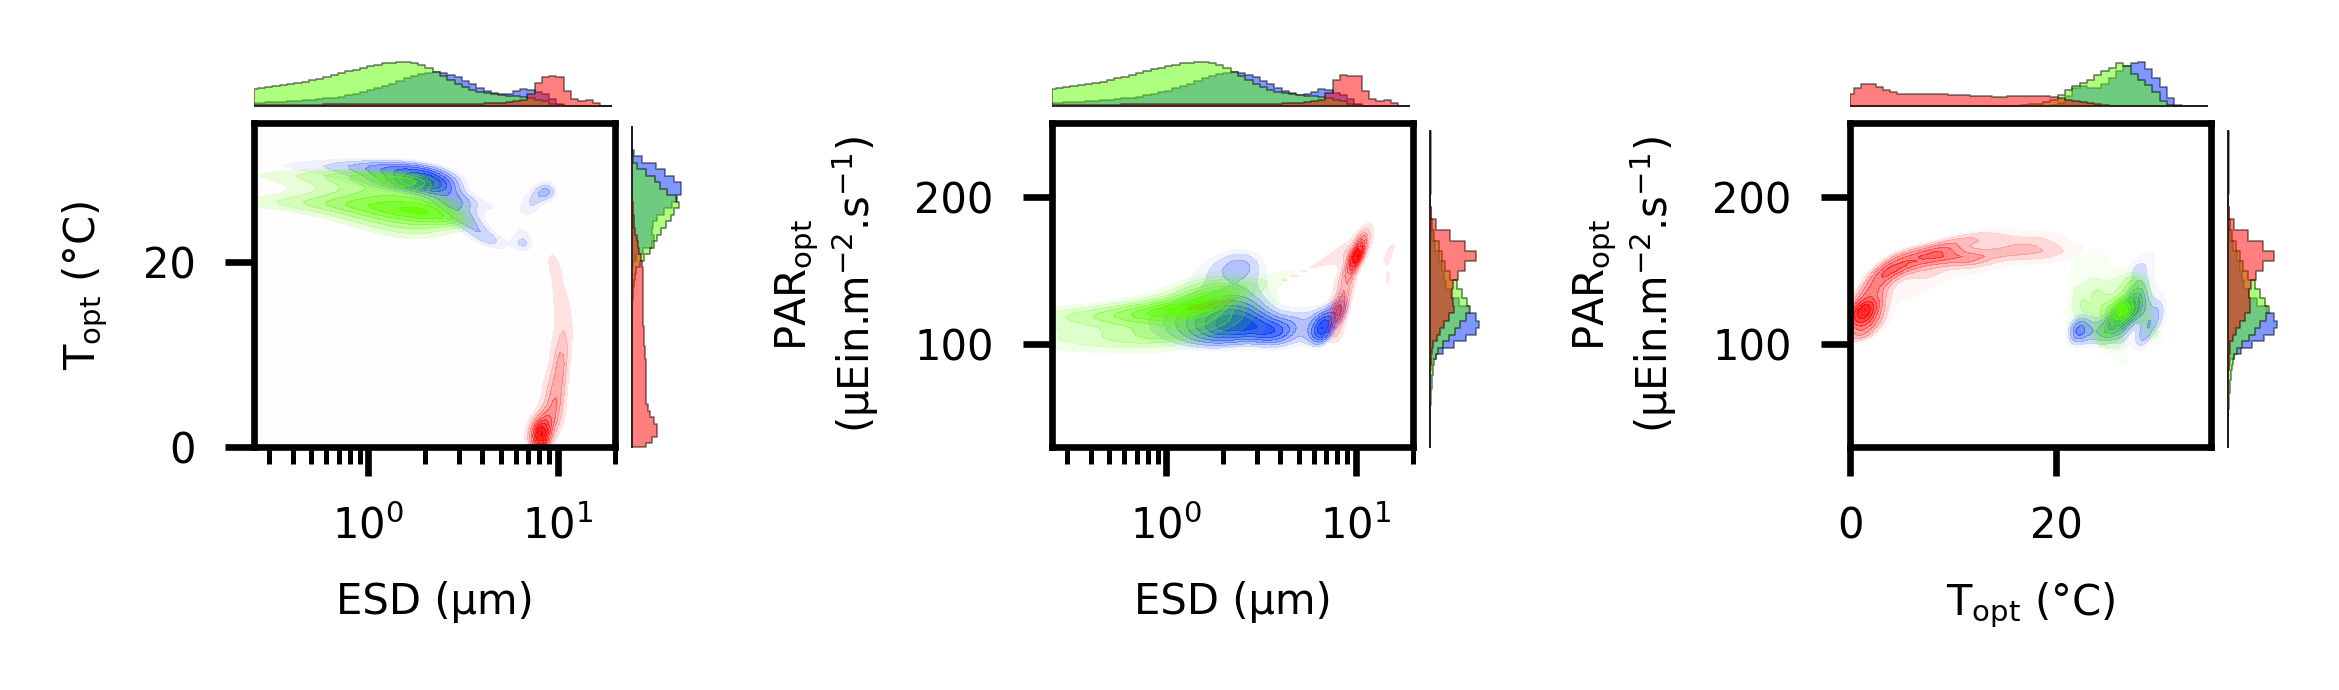

In [24]:
fig = plt.figure(figsize=(4,1.25))  # largeur augmentée pour 2 colonnes
cmap_eq      = matplotlib.colors.LinearSegmentedColormap.from_list("cmap_Eq", ["#0033FF00", "#0033FF"])
cmap_eq_deep = matplotlib.colors.LinearSegmentedColormap.from_list("cmap_Eq_Deep", ["#8E088A00", "#8E088A"])
cmap_eq_surf = matplotlib.colors.LinearSegmentedColormap.from_list("cmap_Eq_Deep", ["#08618E00", "#08618E"])
cmap_st      = matplotlib.colors.LinearSegmentedColormap.from_list("cmap_st", ["#5EFF0000", "#5EFF00"])
cmap_hl      = matplotlib.colors.LinearSegmentedColormap.from_list("cmap_hl", ["#FF000000", "#FF0000"])
lim_min        = 10**np.linspace(-4,-1)
lev = 10
por = 0.25

ax1 = fig.add_subplot(131)
KDE = KDE_ST_eq
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(10**np.linspace(np.log10(0.25),np.log10(20),100),np.linspace(0,35,100),KDE_ST_eq.T,lev, vmin=vmin,cmap=cmap_eq)
KDE = KDE_ST_st
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(10**np.linspace(np.log10(0.25),np.log10(20),100),np.linspace(0,35,100),KDE_ST_st.T,lev, vmin=vmin,cmap=cmap_st)
KDE = KDE_ST_hl
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(10**np.linspace(np.log10(0.25),np.log10(20),100),np.linspace(0,35,100),KDE_ST_hl.T,lev, vmin=vmin,cmap=cmap_hl)
ax1.set_xscale('log')
ax_top, ax_right = add_marginals(ax1, 10**np.linspace(np.log10(0.25),np.log10(20),100), np.linspace(0,35,100), KDE_ST_eq, color="#0033FF")
add_marginals(ax1, 10**np.linspace(np.log10(0.25),np.log10(20),100), np.linspace(0,35,100), KDE_ST_st, color="#5EFF00", ax_top=ax_top, ax_right=ax_right)
add_marginals(ax1, 10**np.linspace(np.log10(0.25),np.log10(20),100), np.linspace(0,35,100), KDE_ST_hl, color="#FF0000", ax_top=ax_top, ax_right=ax_right)
ax1.tick_params(labelsize=5)
ax1.set_xlabel('ESD (µm)',fontsize=5)
ax1.set_ylabel('T$\mathrm{_{opt}}$ (°C)',fontsize=5)

ax1 = fig.add_subplot(132)
KDE = KDE_SP_eq
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(10**np.linspace(np.log10(0.25),np.log10(20),100),10**np.linspace(np.log10(30),np.log10(250),100),KDE_SP_eq.T,lev, vmin=vmin,cmap=cmap_eq)
KDE = KDE_SP_st
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(10**np.linspace(np.log10(0.25),np.log10(20),100),10**np.linspace(np.log10(30),np.log10(250),100),KDE_SP_st.T,lev, vmin=vmin,cmap=cmap_st)
KDE = KDE_SP_hl
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(10**np.linspace(np.log10(0.25),np.log10(20),100),10**np.linspace(np.log10(30),np.log10(250),100),KDE_SP_hl.T,lev, vmin=vmin,cmap=cmap_hl)
ax1.set_xscale('log')
ax_top, ax_right = add_marginals(ax1, 10**np.linspace(np.log10(0.25),np.log10(20),100),10**np.linspace(np.log10(30),np.log10(250),100), KDE_SP_eq, color="#0033FF")
add_marginals(ax1, 10**np.linspace(np.log10(0.25),np.log10(20),100),10**np.linspace(np.log10(30),np.log10(250),100), KDE_SP_st, color="#5EFF00", ax_top=ax_top, ax_right=ax_right)
add_marginals(ax1, 10**np.linspace(np.log10(0.25),np.log10(20),100),10**np.linspace(np.log10(30),np.log10(250),100), KDE_SP_hl, color="#FF0000", ax_top=ax_top, ax_right=ax_right)
ax1.tick_params(labelsize=5)
ax1.set_xlabel('ESD (µm)',fontsize=5)
ax1.set_ylabel('PAR$_{\mathrm{opt}}$\n(µEin.m$^{-2}$.s$^{-1}$)',fontsize=5)

ax1 = fig.add_subplot(133)
KDE = KDE_TP_eq
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(np.linspace(0,35,100),10**np.linspace(np.log10(30),np.log10(250),100),KDE_TP_eq.T,lev, vmin=vmin,cmap=cmap_eq)
KDE = KDE_TP_st
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(np.linspace(0,35,100),10**np.linspace(np.log10(30),np.log10(250),100),KDE_TP_st.T,lev, vmin=vmin,cmap=cmap_st)
KDE = KDE_TP_hl
KDE_norm = KDE/np.sum(KDE)
int_KDE        = []
for i in lim_min:
    int_KDE += [np.sum(KDE_norm[KDE<i])]
vmin = lim_min[np.argmin(np.array(int_KDE)-por<0)]
ax1.contourf(np.linspace(0,35,100),10**np.linspace(np.log10(30),np.log10(250),100),KDE_TP_hl.T,lev, vmin=vmin,cmap=cmap_hl)
ax_top, ax_right = add_marginals(ax1, np.linspace(0,35,100),10**np.linspace(np.log10(30),np.log10(250),100), KDE_TP_eq, color="#0033FF")
add_marginals(ax1, np.linspace(0,35,100),10**np.linspace(np.log10(30),np.log10(250),100), KDE_TP_st, color="#5EFF00", ax_top=ax_top, ax_right=ax_right)
add_marginals(ax1, np.linspace(0,35,100),10**np.linspace(np.log10(30),np.log10(250),100), KDE_TP_hl, color="#FF0000", ax_top=ax_top, ax_right=ax_right)
ax1.tick_params(labelsize=5)
ax1.set_xlabel('T$\mathrm{_{opt}}$ (°C)',fontsize=5)
ax1.set_ylabel('PAR$_{\mathrm{opt}}$\n(µEin.m$^{-2}$.s$^{-1}$)',fontsize=5)

fig.tight_layout()
plt.show()

# Fitness loss

We look at the suboptimality (aka. maladaptation) within local communities. To do so we mesure fitness $\mu$, evaluated as per capita growth rate ($d^{-1}$). We also measure the fitness of individuals carrying the community averaged traits $\mu_{\bar{x}}$. We then evaluate the relative fitness losses $∆\mu = \frac{\mu_{DD}}{\mu}$ and $∆\mu_{\bar{x}} = \frac{\mu_{DD}}{\mu_{\bar{x}}}$ where $\mu_{DD}$ is the fitness of a theoretical optimally adapted individual ($d^{-1}$). Finally we integrate this fitness loss at the population scale by multiplying it by the total primary productivity $PP$ to obtain the ***potential*** biomass loss due to maladapatation: $∆PP_{Pot.} = (1-∆\mu)·PP$ ($\mathrm{mmol\,C \; m^{-2} \; d^{-1}}$).

In [25]:
def Size_Lopt(nl,aKn):
    n,l    = nl
    
    # model parameters
    bKn       = 0.27
    aKpar     = 20
    bKpar     = 0.1
    amu       = 1
    bmu       = 0.17
    
    # Empirical constants
    c1 = 1/353.33500281
    c2 = 2.54430772
    c3 = -0.9425125299113268
    c4 = 0.3489335497066373
    c5 = 17.19491494014629 
    
    size   = c1*((n*bmu/(aKn*(bKn-bmu)))**(1/bKn))*10**(c2/(1 + c5*l**c3*(n/aKn)**c4))
    Kpar   = aKpar*size**bKpar
    PARopt = Kpar + np.sqrt(Kpar**2 + 1.2*Kpar*l + l**2)
    return np.log10(size),PARopt
Size_opt,PAR_opt = Size_Lopt((nut_lim,PAR_mutALL),a_K_mat)
Topt_star = (T * (0.056*5. - 1.) - 0.056*(5.)**2.)/(0.056*5. - 1.)

In [34]:
Surf = np.ma.masked_array(Surf,mask=np.ma.getmask(FPP_mutALL[0,0,:,:]))

# µ_DD 
PCmax      = 1*(10**Size_opt)**0.17
PARoptmin  = 20*(10**Size_opt)**0.1
KN         = 0.17*(10**Size_opt)**0.27
KP         = 0.026*(10**Size_opt)**0.27
KF         = 8e-5*(10**Size_opt)**0.27
Gamma_nutN = (NH4_mutALL+NO2_mutALL+NO3_mutALL)/((NH4_mutALL+NO2_mutALL+NO3_mutALL)+KN)
Gamma_nutP = (P_mutALL)/((P_mutALL)+KP)
Gamma_nutF = (F_mutALL)/((F_mutALL)+KF)
Gamma_nut  = PCmax * np.ma.min(np.array([Gamma_nutN,Gamma_nutP,Gamma_nutF]),0)
Gamma_T    = np.exp(0.056*(Topt_star-20))*np.exp((T[:,:8,:,:]-Topt_star)/5)*(Topt_star+5-T[:,:8,:,:])/5
Gamma_T[Gamma_T<0]=0
alpha      = 3.2/PAR_opt
Gamma_L    = (1.0 - PARoptmin/PAR_opt)*(PAR_mutALL/(PAR_mutALL**2/(alpha*PAR_opt**2)+(1-2/(alpha*PAR_opt))*PAR_mutALL+1/alpha))
mort       = np.exp(0.069*(T[:,:8,:,:]-20))
F_DD       = Gamma_nut * Gamma_T * Gamma_L 
F_DD[F_DD < 0] = 0
F_DD = np.ma.masked_array(F_DD,mask=FPP_mutALL.mask)

# µ_[x_bar]
PCmax_mut     = 1*np.exp(Size_mutALL)**0.17
PARoptmin     = 20*np.exp(Size_mutALL)**0.1
KN            = 0.17*np.exp(Size_mutALL)**0.27
KP            = 0.026*np.exp(Size_mutALL)**0.27
KF            = 8e-5*np.exp(Size_mutALL)**0.27
Gamma_nutN    = (NH4_mutALL+NO2_mutALL+NO3_mutALL)/((NH4_mutALL+NO2_mutALL+NO3_mutALL)+KN)
Gamma_nutP    = (P_mutALL)/((P_mutALL)+KP)
Gamma_nutF    = (F_mutALL)/((F_mutALL)+KF)
Gamma_nut_mut = PCmax_mut * np.min(np.array([Gamma_nutN,Gamma_nutP,Gamma_nutF]),0)
Gamma_T_mut   = np.exp(0.056*(Topt_mutALL-20))*np.exp((T[:,:8,:,:]-Topt_mutALL)/5)*(Topt_mutALL+5-T[:,:8,:,:])/5
Gamma_T_mut[Gamma_T_mut < 0]=0
alpha         = 3.2/np.exp(Lopt_mutALL)
Gamma_L_mut   = (1.0 - PARoptmin/np.exp(Lopt_mutALL))*(PAR_mutALL/(PAR_mutALL**2/(alpha*np.exp(Lopt_mutALL)**2)+(1-2/(alpha*np.exp(Lopt_mutALL)))*PAR_mutALL+1/alpha))
mort          = np.exp(0.069*(T[:,:8,:,:]-20))
F             = Gamma_nut_mut * Gamma_T_mut * Gamma_L_mut 
F[F < 0] = 0
F = np.ma.masked_array(F,mask=FPP_mutALL.mask)

# µ
F_div = (FPP_mutALL/C_mutALL*60*60*24)
#F_div[F_div>F] = F[F_div>F]

DF = (F_DD/F)
DF_div = (F_DD/F_div)
DF_zt  = np.ma.sum(DF*C_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(C_mutALL*delZ[None,:,None,None],(0,1))
#DF_pop = (DF-1)*FPP_mutALL*60*60*24
#DF_div_pop = (DF_div-1)*FPP_mutALL*60*60*24
DF_pop = -(F_DD-F)*C_mutALL
DF_div_pop = -(F_DD-F_div)*C_mutALL
DF_pop_ratio = (F_DD/F-1)
DF_div_pop_ratio = (F_DD/F_div-1)
DF_div_pop_ratio[DF_div_pop_ratio<0] = 0
DF_pop_zt = np.ma.sum(DF_pop*delZ[None,:,None,None],(0,1))/12
DF_pop_zt_lat = np.ma.sum(DF_pop*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,3))/12/np.ma.sum(Surf,1)
DF_div_pop_zt = np.ma.sum(DF_div_pop*delZ[None,:,None,None],(0,1))/12
DF_div_pop_zt_lat = np.ma.sum(DF_div_pop*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,3))/12/np.ma.sum(Surf,1)
DF_div_pop_zt_tot = np.ma.sum(DF_div_pop*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))/12/np.ma.sum(Surf)
DF_div_pop_tot = np.ma.sum(DF_div_pop*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))*360/1e15/1e3*12/12
FPP_tot = np.ma.sum(FPP_mutALL*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))*60*60*24*360/1e15/1e3*12/12
FPP_DDTLS_tot = np.ma.sum(FPP_DDTLS*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))*60*60*24*360/1e15/1e3*12/12

In [35]:
DF_pop_zt_ratio     = np.ma.sum(DF_div_pop_ratio*FPP_mutALL*delZ[None,:,None,None],(0,1))/np.ma.sum(FPP_mutALL*delZ[None,:,None,None],(0,1))
DF_pop_tot_ratio    = np.ma.sum(DF_div_pop_ratio*FPP_mutALL*delZ[None,:,None,None]*Surf[None,None,:,:])/np.ma.sum(FPP_mutALL*delZ[None,:,None,None]*Surf[None,None,:,:])
DF_pop_tot_ratio_sd = np.sqrt(np.ma.sum((DF_pop_zt_ratio-DF_pop_tot_ratio)**2*FPP_mutALL_zt*Surf,(0,1))/np.ma.sum(FPP_mutALL_zt*Surf,(0,1)))
print(DF_pop_tot_ratio,DF_pop_tot_ratio_sd)

0.3208606016699633 0.126089316058611


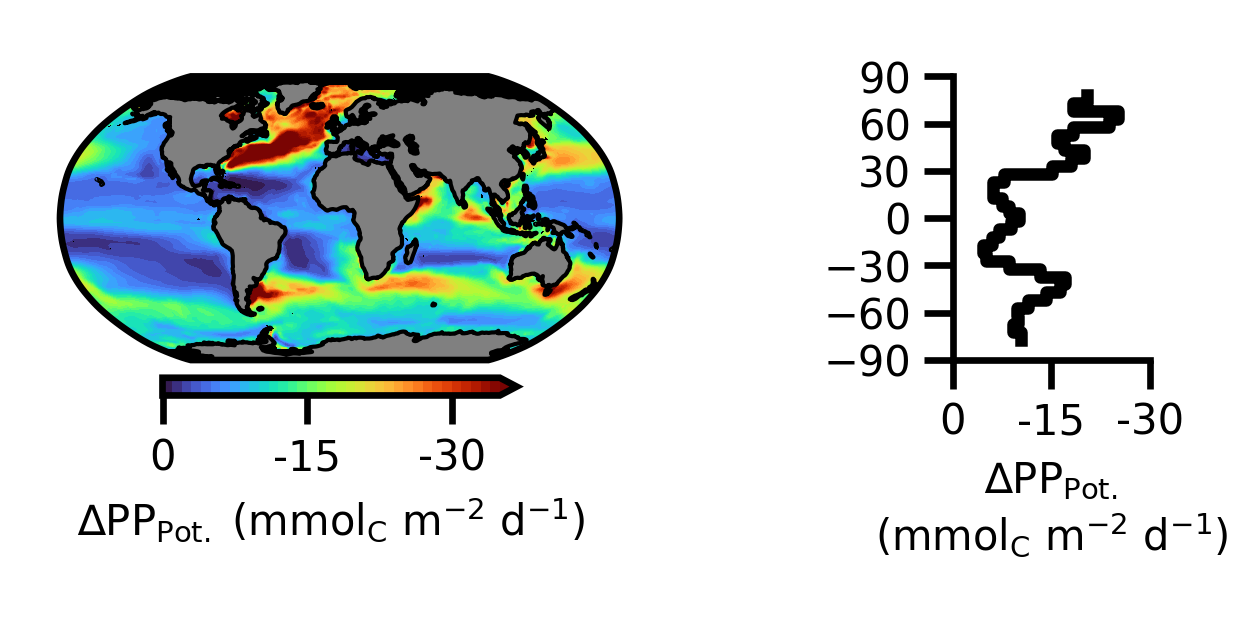

In [43]:
fig = plt.figure(figsize=(3,1.25))  # largeur augmentée pour 2 colonnes
gs = GridSpec(1, 3,width_ratios=[1,0.25,0.25])

ax_map = fig.add_subplot(gs[0,0],facecolor='black',projection=ccrs.Robinson(central_longitude=0.1))
p1 = ax_map.contourf(lon,lat,-DF_div_pop_zt,np.linspace(0,35,36),transform=ccrs.PlateCarree(),cmap='turbo',extend='max')
ax_map.add_feature(cfeature.LAND, facecolor='grey', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.45,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,15,30],minor=False)
c1.ax.set_xticklabels([0,-15,-30])
c1.ax.tick_params(labelsize=5)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('∆PP$_{\mathrm{Pot.}}$ (mmol$_\mathrm{C}$ m$^{-2}$ d$^{-1}$)',rotation=0,fontsize=5,labelpad=2)
ax_map.set_global()

ax_lat = fig.add_subplot(gs[0,1],facecolor='white')
ax_lat.step(-DF_div_pop_zt_lat[::5],lat[::5]+np.diff(lat[::5])[0]/2,c='black', where='post')
#ax_lat.step(DF_pop_zt_lat[::5],lat[::5]+np.diff(lat[::5])[0]/2,lw=1,c='black', where='post')
ax_lat.set_ylim(-90,90)
ax_lat.set_xlim(0,20)
ax_lat.set_yticks([-90,-60,-30,0,30,60,90])
ax_lat.set_xticks([0,15,30])
ax_lat.set_xticklabels([0,-15,-30])
ax_lat.set_xlabel('∆PP$_{\mathrm{Pot.}}$\n(mmol$_\mathrm{C}$ m$^{-2}$ d$^{-1}$)',rotation=0,fontsize=5,labelpad=2)
ax_lat.spines['top'].set_visible(False)
ax_lat.spines['right'].set_visible(False)
ax_lat.tick_params(labelsize=5,pad=1.5)
c1.ax.tick_params(labelsize=5)

fig.tight_layout()

pos_map = ax_map.get_position()
pos_lat = ax_lat.get_position()
ax_lat.set_position([pos_lat.x0,pos_map.y0,pos_lat.width,pos_map.height])

plt.show()

## Fitness loss decomposition

    - Environmental stress:

Calculation of

$∆\mu_{T} = \frac{\gamma_{T_{DD}}}{\gamma_T}$,

$∆\mu_{N} = \frac{\mu_{max_{DD}}\gamma_{N_{DD}}}{\mu_{max}\gamma_N}$, and

$∆\mu_{PAR} = \frac{\gamma_{PAR_{DD}}}{\gamma_{PAR}}$

So that $\mu_{DD} = \mu\left(∆\mu_T·∆\mu_N·∆\mu_{PAR}\right)$.

And $∆\mu = ∆\mu_T·∆\mu_N·∆\mu_{PAR}$

In [48]:
DF_T = Gamma_T/Gamma_T_mut
DF_N = (Gamma_nut)/(Gamma_nut_mut)
DF_L = Gamma_L/Gamma_L_mut
DF_L[DF_N < 1] = DF_L[DF_N < 1] * DF_N[DF_N < 1]
DF_N[DF_L < 1] = DF_L[DF_L < 1] * DF_N[DF_L < 1]
DF_N[DF_N < 1] = 1
DF_L[DF_L < 1] = 1

DF_T.mask = np.copy(DF.mask)
DF_N.mask = np.copy(DF.mask)
DF_L.mask = np.copy(DF.mask)

Calculation of $\sigma_{T}$, $\sigma_{N}$ and $\sigma_{PAR}$

In [49]:
s_T  = np.abs(np.log(DF_T))/(np.abs(np.log(DF_T))+np.abs(np.log(DF_N))+np.abs(np.log(DF_L)))
s_N  = np.abs(np.log(DF_N))/(np.abs(np.log(DF_T))+np.abs(np.log(DF_N))+np.abs(np.log(DF_L)))
s_L  = np.abs(np.log(DF_L))/(np.abs(np.log(DF_T))+np.abs(np.log(DF_N))+np.abs(np.log(DF_L)))

Integration at the population scale

In [47]:
DF_pop_L        = (F_DD-F)*s_L*C_mutALL
DF_pop_L_zt     = np.ma.sum(DF_pop_L*delZ[None,:,None,None],(0,1))/12
DF_pop_L_zt_lat = np.ma.sum(DF_pop_L*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,3))/12/np.ma.sum(Surf,1)
DF_pop_L_zt_tot = np.ma.sum(DF_pop_L*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))/12/np.ma.sum(Surf,(0,1))

DF_pop_N        = (F_DD-F)*s_N*C_mutALL
DF_pop_N_zt     = np.ma.sum(DF_pop_N*delZ[None,:,None,None],(0,1))/12
DF_pop_N_zt_lat = np.ma.sum(DF_pop_N*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,3))/12/np.ma.sum(Surf,1)
DF_pop_N_zt_tot = np.ma.sum(DF_pop_N*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))/12/np.ma.sum(Surf,(0,1))

DF_pop_T        = (F_DD-F)*s_T*C_mutALL
DF_pop_T_zt     = np.ma.sum(DF_pop_T*delZ[None,:,None,None],(0,1))/12
DF_pop_T_zt_lat = np.ma.sum(DF_pop_T*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,3))/12/np.ma.sum(Surf,1)
DF_pop_T_zt_tot = np.ma.sum(DF_pop_T*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))/12/np.ma.sum(Surf,(0,1))

    - Traits:

Calculation of $∆\mu_{T_{opt}}$, $∆\mu_{S}$ and $∆\mu_{PAR_{opt}}$ (see methods for expressions) so that $\mu_{DD} = \mu\left(∆\mu_T·∆\mu_N·∆\mu_{PAR}\right)$ and $∆\mu = ∆\mu_T·∆\mu_N·∆\mu_{PAR}$

In [50]:
#F_Topt:
DF_Topt = Gamma_T/Gamma_T_mut

#F_Lopt:
PARoptmin     = 20*(10**Size_opt)**0.1
alpha         = 3.2/np.exp(Lopt_mutALL)
Gamma_L_L_mut = (1.0 - PARoptmin/np.exp(Lopt_mutALL))*(PAR_mutALL/(PAR_mutALL**2/(alpha*np.exp(Lopt_mutALL)**2)+(1-2/(alpha*np.exp(Lopt_mutALL)))*PAR_mutALL+1/alpha))
DF_Lopt1       = Gamma_L/Gamma_L_L_mut 

#F_S:
PARoptmin     = 20*np.exp(Size_mutALL)**0.1
alpha         = 3.2/PAR_opt
Gamma_L_S_mut = (1.0 - PARoptmin/PAR_opt)*(PAR_mutALL/(PAR_mutALL**2/(alpha*PAR_opt**2)+(1-2/(alpha*PAR_opt))*PAR_mutALL+1/alpha))
DF_S1         = (Gamma_nut*Gamma_L)/(Gamma_nut_mut*Gamma_L_S_mut) 

#Eps_S:PAR
Eps_S_L       = DF/DF_Topt/DF_Lopt1/DF_S1

DF_Lopt       = DF_Lopt1*np.sqrt(Eps_S_L)
DF_S          = DF_S1*np.sqrt(Eps_S_L)


DF_Topt.mask  = np.copy(DF.mask)
DF_S.mask     = np.copy(DF.mask)
DF_Lopt.mask  = np.copy(DF.mask)

/var/folders/fm/8kc1yt4n3mncnjr5dr0_558m0000gp/T/ipykernel_33177/4141852576.py:19: RuntimeWarning: invalid value encountered in sqrt
  DF_Lopt       = DF_Lopt1*np.sqrt(Eps_S_L)
/var/folders/fm/8kc1yt4n3mncnjr5dr0_558m0000gp/T/ipykernel_33177/4141852576.py:20: RuntimeWarning: invalid value encountered in sqrt
  DF_S          = DF_S1*np.sqrt(Eps_S_L)


Calculation of $\sigma_{T_{opt}}$, $\sigma_{S}$ and $\sigma_{PAR_{opt}}$

In [52]:
s_Topt = np.abs(np.log(DF_Topt))/(np.abs(np.log(DF_Topt))+np.abs(np.log(DF_S))+np.abs(np.log(DF_Lopt)))
s_S    = np.abs(np.log(DF_S))/(np.abs(np.log(DF_Topt))+np.abs(np.log(DF_S))+np.abs(np.log(DF_Lopt)))
s_Lopt = np.abs(np.log(DF_Lopt))/(np.abs(np.log(DF_Topt))+np.abs(np.log(DF_S))+np.abs(np.log(DF_Lopt)))

/var/folders/fm/8kc1yt4n3mncnjr5dr0_558m0000gp/T/ipykernel_33177/2327686627.py:1: RuntimeWarning: invalid value encountered in log
  s_Topt = np.abs(np.log(DF_Topt))/(np.abs(np.log(DF_Topt))+np.abs(np.log(DF_S))+np.abs(np.log(DF_Lopt)))
/var/folders/fm/8kc1yt4n3mncnjr5dr0_558m0000gp/T/ipykernel_33177/2327686627.py:2: RuntimeWarning: invalid value encountered in log
  s_S    = np.abs(np.log(DF_S))/(np.abs(np.log(DF_Topt))+np.abs(np.log(DF_S))+np.abs(np.log(DF_Lopt)))
/var/folders/fm/8kc1yt4n3mncnjr5dr0_558m0000gp/T/ipykernel_33177/2327686627.py:3: RuntimeWarning: invalid value encountered in log
  s_Lopt = np.abs(np.log(DF_Lopt))/(np.abs(np.log(DF_Topt))+np.abs(np.log(DF_S))+np.abs(np.log(DF_Lopt)))


Integration at the population scale

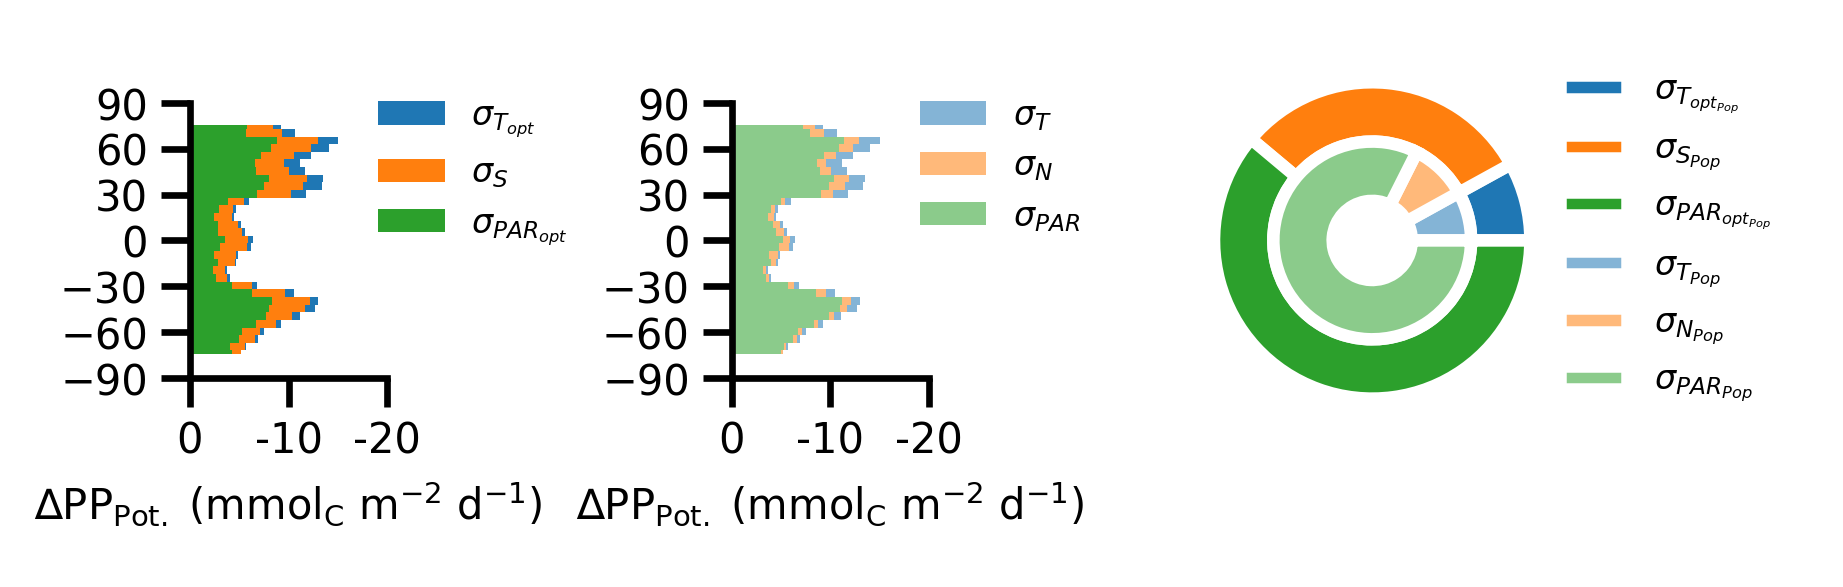

In [56]:
DF_pop_Lopt        = (F_DD-F)*s_Lopt*C_mutALL
DF_pop_Lopt_zt     = np.ma.sum(DF_pop_Lopt*delZ[None,:,None,None],(0,1))/12
DF_pop_Lopt_zt_lat = np.ma.sum(DF_pop_Lopt*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,3))/12/np.ma.sum(Surf,1)
DF_pop_Lopt_zt_tot = np.ma.sum(DF_pop_Lopt*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))/12/np.ma.sum(Surf,(0,1))

DF_pop_S           = (F_DD-F)*s_S*C_mutALL
DF_pop_S_zt        = np.ma.sum(DF_pop_S*delZ[None,:,None,None],(0,1))/12
DF_pop_S_zt_lat    = np.ma.sum(DF_pop_S*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,3))/12/np.ma.sum(Surf,1)
DF_pop_S_zt_tot    = np.ma.sum(DF_pop_S*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))/12/np.ma.sum(Surf,(0,1))

DF_pop_Topt        = (F_DD-F)*s_Topt*C_mutALL
DF_pop_Topt_zt     = np.ma.sum(DF_pop_Topt*delZ[None,:,None,None],(0,1))/12
DF_pop_Topt_zt_lat = np.ma.sum(DF_pop_Topt*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,3))/12/np.ma.sum(Surf,1)
DF_pop_Topt_zt_tot = np.ma.sum(DF_pop_Topt*delZ[None,:,None,None]*Surf[None,None,:,:],(0,1,2,3))/12/np.ma.sum(Surf,(0,1))

fig = plt.figure(figsize=(3.3,1.25))  # largeur augmentée pour 2 colonnes
gs = GridSpec(1, 3,width_ratios=[1,1,1])

ax1 = fig.add_subplot(gs[0,0],facecolor='none')
ax1.fill_betweenx(lat[::5],(DF_pop_Topt_zt_lat)[::5]+(DF_pop_S_zt_lat)[::5]+(DF_pop_Lopt_zt_lat)[::5],(DF_pop_Topt_zt_lat)[::5]+(DF_pop_S_zt_lat)[::5],step='mid',label='$\sigma_{T_{opt}}$')
ax1.fill_betweenx(lat[::5],(DF_pop_Lopt_zt_lat)[::5]+(DF_pop_S_zt_lat)[::5],(DF_pop_Lopt_zt_lat)[::5],step='mid',label='$\sigma_{S}$')
ax1.fill_betweenx(lat[::5],(DF_pop_Lopt_zt_lat)[::5],step='mid',label='$\sigma_{PAR_{opt}}$')
ax1.set_ylim(-90,90)
ax1.set_xlim(0,20)
ax1.set_yticks([-90,-60,-30,0,30,60,90])
ax1.set_xticks([0,10,20])
ax1.set_xticklabels([0,-10,-20])
ax1.set_xlabel('∆PP$_{\mathrm{Pot.}}$ (mmol$_\mathrm{C}$ m$^{-2}$ d$^{-1}$)',fontsize=5,labelpad=2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(labelsize=5,pad=1.5)
c1.ax.tick_params(labelsize=5)
plt.legend(fontsize=4,frameon=False,bbox_to_anchor=(.8, 0, 0.5, 1.125))

ax1 = fig.add_subplot(gs[0,1],facecolor='none')
ax1.fill_betweenx(lat[::5],(DF_pop_T_zt_lat)[::5]+(DF_pop_N_zt_lat)[::5]+(DF_pop_L_zt_lat)[::5],(DF_pop_T_zt_lat)[::5]+(DF_pop_N_zt_lat)[::5],step='mid',label='$\sigma{_T}$',facecolor=pastel_col[0])
ax1.fill_betweenx(lat[::5],(DF_pop_L_zt_lat)[::5]+(DF_pop_N_zt_lat)[::5],(DF_pop_L_zt_lat)[::5],step='mid',label='$\sigma{_N}$',facecolor=pastel_col[1])
ax1.fill_betweenx(lat[::5],(DF_pop_L_zt_lat)[::5],step='mid',label='$\sigma{_{PAR}}$',facecolor=pastel_col[2])
ax1.set_ylim(-90,90)
ax1.set_xlim(0,20)
ax1.set_yticks([-90,-60,-30,0,30,60,90])
ax1.set_xticks([0,10,20])
ax1.set_xticklabels([0,-10,-20])
ax1.set_xlabel('∆PP$_{\mathrm{Pot.}}$ (mmol$_\mathrm{C}$ m$^{-2}$ d$^{-1}$)',fontsize=5,labelpad=2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(labelsize=5,pad=1.5)
c1.ax.tick_params(labelsize=5)
plt.legend(fontsize=4,frameon=False,bbox_to_anchor=(.8, 0, 0.5, 1.125))

ax1 = fig.add_subplot(gs[0,2],facecolor='none')

val0 = [DF_pop_Topt_zt_tot,DF_pop_S_zt_tot,DF_pop_Lopt_zt_tot]
val1 = [DF_pop_T_zt_tot,DF_pop_N_zt_tot,DF_pop_L_zt_tot]

col1 = pastel_col

lab0 = ['$\sigma_{T_{opt_{Pop}}}$','$\sigma_{S_{Pop}}$','$\sigma_{PAR_{opt_{Pop}}}$']
lab1 = ['$\sigma_{T_{Pop}}$','$\sigma_{N_{Pop}}$','$\sigma_{PAR_{Pop}}$']

wedges0,  texts0  = ax1.pie(val0, radius=2, wedgeprops=dict(width=0.75,edgecolor='w',linewidth=1.5))
wedges1,  texts1  = ax1.pie(val1, radius=1.25, wedgeprops=dict(width=0.75,edgecolor='w',linewidth=1.5),colors=col1)
plt.legend(wedges0+wedges1,lab0+lab1,bbox_to_anchor=(1.3, 0, 0.5, 1.5),frameon=False,fontsize=4)

fig.tight_layout()
plt.show()

    - Vertical, seasonal and constant maladaptation

In [168]:
# Biomass weighted fitness loss centered around 0
Floss        = DF-1
Floss_zt     = np.ma.sum(Floss*delZ[None,:,None,None]*C_mutALL,(0,1))/np.ma.sum(delZ[None,:,None,None]*C_mutALL,(0,1))
Floss_t      = np.ma.sum(Floss*delZ[None,:,None,None]*C_mutALL,(0))/np.ma.sum(delZ[None,:,None,None]*C_mutALL,(0))
Floss_z      = np.ma.sum(Floss*delZ[None,:,None,None]*C_mutALL,(1))/np.ma.sum(delZ[None,:,None,None]*C_mutALL,(1))

Stot         = np.ma.sum((Floss-Floss_zt)**2*delZ[None,:,None,None]*C_mutALL,(0,1))/np.ma.sum(delZ[None,:,None,None]*C_mutALL,(0,1))
St           = np.ma.sum((Floss_t-Floss_zt)**2*np.ma.sum(delZ[None,:,None,None]*C_mutALL,0),0)/np.ma.sum(delZ[None,:,None,None]*C_mutALL,(0,1))
Sz           = np.ma.sum((Floss_z-Floss_zt)**2*np.ma.sum(delZ[None,:,None,None]*C_mutALL,1),0)/np.ma.sum(delZ[None,:,None,None]*C_mutALL,(0,1))

In [169]:
# Direction of i - i*
Mal_T = Topt_mutALL-Topt_star
Mal_S = Size_mutALL-np.log(10**Size_opt)
Mal_L = Lopt_mutALL-np.log(PAR_opt)

In [170]:
# Directional fitness loss
Floss_L = (Floss)*s_Lopt
Floss_S = (Floss)*s_S
Floss_T = (Floss)*s_Topt

Floss_L_dir = (Floss_L)*np.sign(Mal_L)
Floss_S_dir = (Floss_S)*np.sign(Mal_S)
Floss_T_dir = (Floss_T)*np.sign(Mal_T)

w  = delZ[None,:,None,None]*FPP_mutALL
Floss_T_dir_zt = np.ma.sum(Floss_T_dir*w,(0,1))/np.ma.sum(w,(0,1))
Floss_S_dir_zt = np.ma.sum(Floss_S_dir*w,(0,1))/np.ma.sum(w,(0,1))
Floss_L_dir_zt = np.ma.sum(Floss_L_dir*w,(0,1))/np.ma.sum(w,(0,1))

In [204]:
#meth = 'quadratic'
meth = 'shapley'

## - $\mathrm{PAR_{opt}}$

In [205]:
V  = Floss_L_dir
w  = delZ[None,:,None,None]*FPP_mutALL
w_zt = np.ma.sum(w,(0,1))
Lzt = np.ma.sum(np.ma.abs(V)*w,(0,1))/w_zt

mV  = np.ma.sum(V*w,(0,1))/np.ma.sum(w,(0,1))                   # Directional mean
mV2 = np.ma.sum((V**2)*w,(0,1))/np.ma.sum(w,(0,1))              # mV**2

mz  = np.ma.sum(V*w,(0))/np.ma.sum(w,(0)) - mV                  # Contribution of z to the mean
mt  = np.ma.sum(V*w,(1))/np.ma.sum(w,(1)) - mV                  # Contribution of t to the mean
mzt = V - mz[None,:,:,:] - mt[:,None,:,:] - mV[None,None,:,:]   # Interaction of z and t

In [206]:
if meth == 'quadratic':
    
    # Calculates contributions
    SS_tot = np.ma.sum(((V-mV)**2)*w,(0,1))/np.ma.sum(w,(0,1))                     # Total variance
    SS_z   = np.ma.sum(((mz[None,:,:,:])**2)*w,(0,1))/np.ma.sum(w,(0,1))           # Vertical variance
    SS_t   = np.ma.sum(((mt[:,None,:,:])**2)*w,(0,1))/np.ma.sum(w,(0,1))           # Temporal variance
    SS_zt  = np.ma.sum(((mzt)**2)*w,(0,1))/np.ma.sum(w,(0,1))                      # Interaction term
    cov_zt = np.ma.sum(w*mz[None,:,:,:]*mt[:,None,:,:],(0,1))/np.ma.sum(w,(0,1))   # | 
    cov_zi = np.ma.sum(w*mz[None,:,:,:]*mzt,(0,1))/np.ma.sum(w,(0,1))              # | Covariance terms
    cov_ti = np.ma.sum(w*mt[:,None,:,:]*mzt,(0,1))/np.ma.sum(w,(0,1))              # |
    
    Fr_z   = (SS_z+cov_zt+cov_zi)/SS_tot
    Fr_t   = (SS_t+cov_zt+cov_ti)/SS_tot
    Fr_zt  = (SS_zt+cov_zi+cov_ti)/SS_tot
    
    Fr_z   += Fr_zt/2
    Fr_t   += Fr_zt/2
    
    Fr_z[Fr_z < 0] = 0 
    Fr_t[Fr_t < 0] = 0 
    Fr_zt[Fr_zt < 0] = 0

    # Integrates at population scale
    DF_moy_L        = mV**2/mV2
    DF_var_L        = SS_tot/mV2
    DF_var_z_L      = SS_tot/mV2*Fr_z
    DF_var_t_L      = SS_tot/mV2*Fr_t
    
    DF_moy_L_tot    = np.ma.sum(DF_moy_L*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_L_tot    = np.ma.sum(DF_var_L*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_z_L_tot  = np.ma.sum(DF_var_z_L*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_t_L_tot  = np.ma.sum(DF_var_t_L*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    
    DF_moy_L_lat    = np.ma.sum(DF_moy_L*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_L_lat    = np.ma.sum(DF_var_L*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_z_L_lat  = np.ma.sum(DF_var_z_L*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_t_L_lat  = np.ma.sum(DF_var_t_L*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    
elif meth == 'shapley':    

    # Calculates contributions
    effects = {'c': mV[None,None,:,:], 'z': mz[None,:,:,:], 't': mt[:,None,:,:]}
    def v(S):
        F = V*0
        for p in S:
            F = F + effects[p]
        if 'z' in S and 't' in S:
            F = F + mzt                 # l'interaction n'existe que si z et t sont présents
        return np.ma.sum(np.ma.abs(F)*w,(0,1))/w_zt
    
    players = ['c','z','t']; n = len(players)
    phi = {p: 0 for p in players}
    for p in players:
        others = [q for q in players if q != p]
        for k in range(n):
            for S in itertools.combinations(others, k):
                wt = math.factorial(k)*math.factorial(n-k-1)/math.factorial(n)
                phi[p] = phi[p] + wt*(v(S+(p,)) - v(S))

    # Integrates at population scale
    DF_moy_L      = phi['c']/Lzt
    DF_var_L      = (Lzt-phi['c'])/Lzt
    DF_var_z_L    = phi['z']/Lzt
    DF_var_t_L    = phi['t']/Lzt  

    DF_moy_L_tot    = np.ma.sum(DF_moy_L*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_L_tot    = np.ma.sum(DF_var_L*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_z_L_tot  = np.ma.sum(DF_var_z_L*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_t_L_tot  = np.ma.sum(DF_var_t_L*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    
    DF_moy_L_lat    = np.ma.sum(DF_moy_L*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_L_lat    = np.ma.sum(DF_var_L*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_z_L_lat  = np.ma.sum(DF_var_z_L*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_t_L_lat  = np.ma.sum(DF_var_t_L*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)

else:
    print('undefined method')

## - $\mathrm{T_{opt}}$

In [207]:
V  = Floss_T_dir
w  = delZ[None,:,None,None]*FPP_mutALL
w_zt = np.ma.sum(w,(0,1))
Lzt = np.ma.sum(np.ma.abs(V)*w,(0,1))/w_zt

mV  = np.ma.sum(V*w,(0,1))/np.ma.sum(w,(0,1))                   # Directional mean
mV2 = np.ma.sum((V**2)*w,(0,1))/np.ma.sum(w,(0,1))              # mV**2

mz  = np.ma.sum(V*w,(0))/np.ma.sum(w,(0)) - mV                  # Contribution of z to the mean
mt  = np.ma.sum(V*w,(1))/np.ma.sum(w,(1)) - mV                  # Contribution of t to the mean
mzt = V - mz[None,:,:,:] - mt[:,None,:,:] - mV[None,None,:,:]   # Interaction of z and t

In [208]:
if meth == 'quadratic':
    
    # Calculates contributions
    SS_tot = np.ma.sum(((V-mV)**2)*w,(0,1))/np.ma.sum(w,(0,1))                     # Total variance
    SS_z   = np.ma.sum(((mz[None,:,:,:])**2)*w,(0,1))/np.ma.sum(w,(0,1))           # Vertical variance
    SS_t   = np.ma.sum(((mt[:,None,:,:])**2)*w,(0,1))/np.ma.sum(w,(0,1))           # Temporal variance
    SS_zt  = np.ma.sum(((mzt)**2)*w,(0,1))/np.ma.sum(w,(0,1))                      # Interaction term
    cov_zt = np.ma.sum(w*mz[None,:,:,:]*mt[:,None,:,:],(0,1))/np.ma.sum(w,(0,1))   # | 
    cov_zi = np.ma.sum(w*mz[None,:,:,:]*mzt,(0,1))/np.ma.sum(w,(0,1))              # | Covariance terms
    cov_ti = np.ma.sum(w*mt[:,None,:,:]*mzt,(0,1))/np.ma.sum(w,(0,1))              # |
    
    Fr_z   = (SS_z+cov_zt+cov_zi)/SS_tot
    Fr_t   = (SS_t+cov_zt+cov_ti)/SS_tot
    Fr_zt  = (SS_zt+cov_zi+cov_ti)/SS_tot
    
    Fr_z   += Fr_zt/2
    Fr_t   += Fr_zt/2
    
    Fr_z[Fr_z < 0] = 0 
    Fr_t[Fr_t < 0] = 0 
    Fr_zt[Fr_zt < 0] = 0

    # Integrates at population scale
    DF_moy_T        = mV**2/mV2
    DF_var_T        = SS_tot/mV2
    DF_var_z_T      = SS_tot/mV2*Fr_z
    DF_var_t_T      = SS_tot/mV2*Fr_t
    
    DF_moy_T_tot    = np.ma.sum(DF_moy_T*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_T_tot    = np.ma.sum(DF_var_T*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_z_T_tot  = np.ma.sum(DF_var_z_T*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_t_T_tot  = np.ma.sum(DF_var_t_T*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    
    DF_moy_T_Tat    = np.ma.sum(DF_moy_T*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_T_Tat    = np.ma.sum(DF_var_T*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_z_T_Tat  = np.ma.sum(DF_var_z_T*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_t_T_Tat  = np.ma.sum(DF_var_t_T*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    
elif meth == 'shapley':    

    # Calculates contributions
    effects = {'c': mV[None,None,:,:], 'z': mz[None,:,:,:], 't': mt[:,None,:,:]}
    def v(S):
        F = V*0
        for p in S:
            F = F + effects[p]
        if 'z' in S and 't' in S:
            F = F + mzt                 # l'interaction n'existe que si z et t sont présents
        return np.ma.sum(np.ma.abs(F)*w,(0,1))/w_zt
    
    players = ['c','z','t']; n = len(players)
    phi = {p: 0 for p in players}
    for p in players:
        others = [q for q in players if q != p]
        for k in range(n):
            for S in itertools.combinations(others, k):
                wt = math.factorial(k)*math.factorial(n-k-1)/math.factorial(n)
                phi[p] = phi[p] + wt*(v(S+(p,)) - v(S))

    # Integrates at population scale
    DF_moy_T      = phi['c']/Lzt
    DF_var_T      = (Lzt-phi['c'])/Lzt
    DF_var_z_T    = phi['z']/Lzt
    DF_var_t_T    = phi['t']/Lzt  

    DF_moy_T_tot    = np.ma.sum(DF_moy_T*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_T_tot    = np.ma.sum(DF_var_T*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_z_T_tot  = np.ma.sum(DF_var_z_T*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_t_T_tot  = np.ma.sum(DF_var_t_T*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    
    DF_moy_T_lat    = np.ma.sum(DF_moy_T*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_T_lat    = np.ma.sum(DF_var_T*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_z_T_lat  = np.ma.sum(DF_var_z_T*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_t_T_lat  = np.ma.sum(DF_var_t_T*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)

else:
    print('undefined method')

## - Size

In [209]:
V  = Floss_S_dir
w  = delZ[None,:,None,None]*FPP_mutALL
w_zt = np.ma.sum(w,(0,1))
Lzt = np.ma.sum(np.ma.abs(V)*w,(0,1))/w_zt

mV  = np.ma.sum(V*w,(0,1))/np.ma.sum(w,(0,1))                   # Directional mean
mV2 = np.ma.sum((V**2)*w,(0,1))/np.ma.sum(w,(0,1))              # mV**2

mz  = np.ma.sum(V*w,(0))/np.ma.sum(w,(0)) - mV                  # Contribution of z to the mean
mt  = np.ma.sum(V*w,(1))/np.ma.sum(w,(1)) - mV                  # Contribution of t to the mean
mzt = V - mz[None,:,:,:] - mt[:,None,:,:] - mV[None,None,:,:]   # Interaction of z and t

In [210]:
if meth == 'quadratic':
    
    # Calculates contributions
    SS_Sot = np.ma.sum(((V-mV)**2)*w,(0,1))/np.ma.sum(w,(0,1))                     # Total variance
    SS_z   = np.ma.sum(((mz[None,:,:,:])**2)*w,(0,1))/np.ma.sum(w,(0,1))           # Vertical variance
    SS_t   = np.ma.sum(((mt[:,None,:,:])**2)*w,(0,1))/np.ma.sum(w,(0,1))           # Temporal variance
    SS_zt  = np.ma.sum(((mzt)**2)*w,(0,1))/np.ma.sum(w,(0,1))                      # Interaction term
    cov_zt = np.ma.sum(w*mz[None,:,:,:]*mt[:,None,:,:],(0,1))/np.ma.sum(w,(0,1))   # | 
    cov_zi = np.ma.sum(w*mz[None,:,:,:]*mzt,(0,1))/np.ma.sum(w,(0,1))              # | Covariance terms
    cov_Si = np.ma.sum(w*mt[:,None,:,:]*mzt,(0,1))/np.ma.sum(w,(0,1))              # |
    
    Fr_z   = (SS_z+cov_zt+cov_zi)/SS_Sot
    Fr_t   = (SS_S+cov_zt+cov_Si)/SS_Sot
    Fr_zt  = (SS_zt+cov_zi+cov_Si)/SS_Sot
    
    Fr_z   += Fr_zt/2
    Fr_t   += Fr_zt/2
    
    Fr_z[Fr_z < 0] = 0 
    Fr_t[Fr_t < 0] = 0 
    Fr_zt[Fr_zt < 0] = 0

    # Integrates at population scale
    DF_moy_S        = mV**2/mV2
    DF_var_S        = SS_Sot/mV2
    DF_var_z_S      = SS_Sot/mV2*Fr_z
    DF_var_t_S      = SS_Sot/mV2*Fr_t
    
    DF_moy_S_tot    = np.ma.sum(DF_moy_S*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_S_tot    = np.ma.sum(DF_var_S*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_z_S_tot  = np.ma.sum(DF_var_z_S*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_t_S_tot  = np.ma.sum(DF_var_t_S*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    
    DF_moy_S_lat    = np.ma.sum(DF_moy_S*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_S_lat    = np.ma.sum(DF_var_S*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_z_S_lat  = np.ma.sum(DF_var_z_S*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_t_S_lat  = np.ma.sum(DF_var_t_S*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)


elif meth == 'shapley':    

    # Calculates contributions
    effects = {'c': mV[None,None,:,:], 'z': mz[None,:,:,:], 't': mt[:,None,:,:]}
    def v(S):
        F = V*0
        for p in S:
            F = F + effects[p]
        if 'z' in S and 't' in S:
            F = F + mzt                 # l'interaction n'existe que si z et t sont présents
        return np.ma.sum(np.ma.abs(F)*w,(0,1))/w_zt
    
    players = ['c','z','t']; n = len(players)
    phi = {p: 0 for p in players}
    for p in players:
        others = [q for q in players if q != p]
        for k in range(n):
            for S in itertools.combinations(others, k):
                wt = math.factorial(k)*math.factorial(n-k-1)/math.factorial(n)
                phi[p] = phi[p] + wt*(v(S+(p,)) - v(S))

    # Integrates at population scale
    DF_moy_S      = phi['c']/Lzt
    DF_var_S      = (Lzt-phi['c'])/Lzt
    DF_var_z_S    = phi['z']/Lzt
    DF_var_t_S    = phi['t']/Lzt  

    DF_moy_S_tot    = np.ma.sum(DF_moy_S*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_S_tot    = np.ma.sum(DF_var_S*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_z_S_tot  = np.ma.sum(DF_var_z_S*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    DF_var_t_S_tot  = np.ma.sum(DF_var_t_S*np.ma.sum(w,(0,1))*Surf)/np.ma.sum(np.ma.sum(w,(0,1))*Surf)
    
    DF_moy_S_lat    = np.ma.sum(DF_moy_S*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_S_lat    = np.ma.sum(DF_var_S*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_z_S_lat  = np.ma.sum(DF_var_z_S*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)
    DF_var_t_S_lat  = np.ma.sum(DF_var_t_S*np.ma.sum(w,(0,1))*Surf,1)/np.ma.sum(np.ma.sum(w,(0,1))*Surf,1)

else:
    print('undefined method')

## - Figures

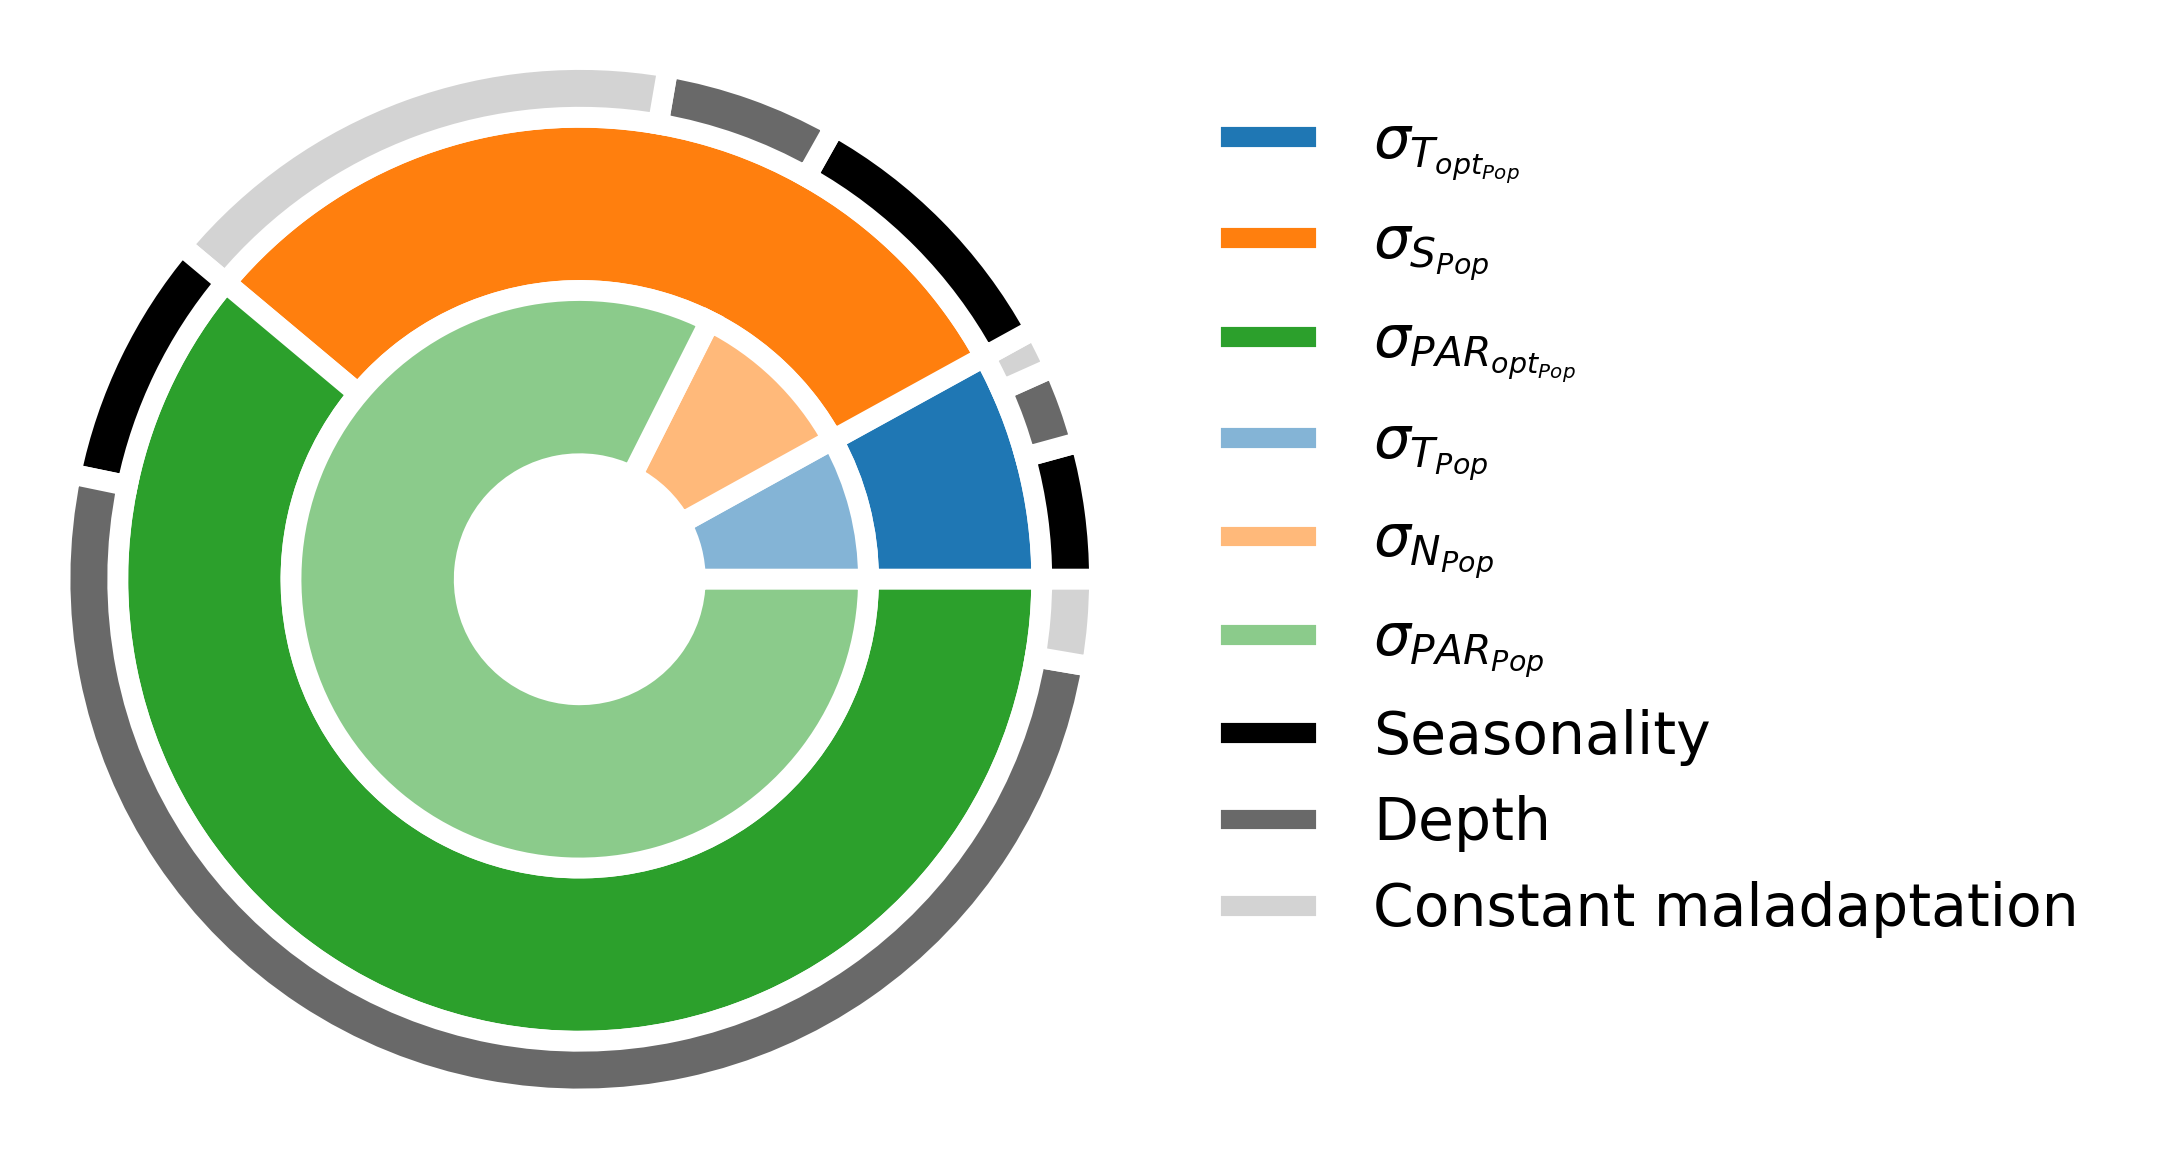

In [211]:
fig = plt.figure(figsize=(3,1.25))  # largeur augmentée pour 2 colonnes

ax1 = fig.add_subplot(111,facecolor='none')

val0 = [DF_pop_Topt_zt_tot,DF_pop_S_zt_tot,DF_pop_Lopt_zt_tot]
val1 = [DF_pop_T_zt_tot,DF_pop_N_zt_tot,DF_pop_L_zt_tot]
val2 = (np.array([DF_var_t_T_tot,DF_var_z_T_tot,DF_moy_T_tot])*DF_pop_Topt_zt_tot).tolist()+(np.array([DF_var_t_S_tot,DF_var_z_S_tot,DF_moy_S_tot])*DF_pop_S_zt_tot).tolist()+(np.array([DF_var_t_L_tot,DF_var_z_L_tot,DF_moy_L_tot])*DF_pop_Lopt_zt_tot).tolist()

col0 = base_col
col1 = pastel_col
col2 = ['black','dimgrey','lightgrey']*3

lab0 = ['$\sigma_{T_{opt_{Pop}}}$','$\sigma_{S_{Pop}}$','$\sigma_{PAR_{opt_{Pop}}}$']
lab1 = ['$\sigma_{T_{Pop}}$','$\sigma_{N_{Pop}}$','$\sigma_{PAR_{Pop}}$']
lab2 = ['Seasonality','Depth','Constant maladaptation']

wedges0,  texts0  = ax1.pie(val0, radius=2, wedgeprops=dict(width=0.75,edgecolor='w',linewidth=2.5))
wedges1,  texts1  = ax1.pie(val1, radius=1.25, wedgeprops=dict(width=0.75,edgecolor='w',linewidth=2.5),colors=col1)
wedges2,  texts2  = ax1.pie(val2, radius=2.25, wedgeprops=dict(width=0.25,edgecolor='w',linewidth=2.5),colors=col2)
plt.legend(wedges0+wedges1+wedges2,lab0+lab1+lab2,bbox_to_anchor=(1.5, 0, 0.5, 1.4),frameon=False,fontsize=7)

plt.show()

In [212]:
def recenter(ys, target, scale=1.0):
    """Recentre une liste de positions y autour de `target`,
    en compressant l'étalement d'un facteur `scale` (1.0 = pas de compression)."""
    return [target + scale*(y - 0.5) for y in ys]

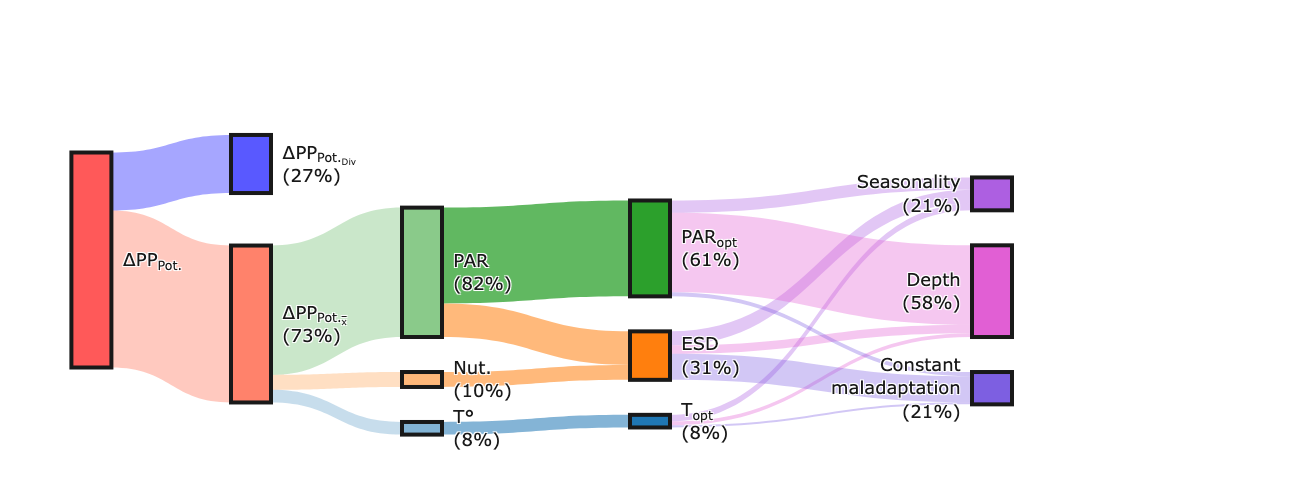

In [213]:
col2 = ['#AD5FE1','#E15FD4','#7D5FE1']

vec = [np.array((val1[0], val1[1], val1[2]))[i] for i in [2,1,0]]/np.sum(val1)
y1  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(2)]
y1  = [y1[i] for i in [2,1,0]]
vec = [np.array((val0[0], val0[1], val0[2]))[i] for i in [2,1,0]]/np.sum(val0)
y2  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(2)]
y2  = [y2[i] for i in [2,1,0]]
vec = [np.array([np.sum(val2[i::4]/np.sum(val2)) for i in np.arange(4)])[i] for i in [0,1,2]]
y3  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(3)]
y3  = [y3[i] for i in [0,1,2]]

y1c = recenter(y1, target=0.6, scale=0.7)
y2c = recenter(y2, target=0.6, scale=0.7)
y3c = recenter(y3, target=0.6, scale=0.7)

# --- NOUVEAU : valeurs / apparence des deux nodes ajoutés ---
val_root   = [np.sum(val0), -DF_div_pop_zt_tot-np.sum(val0)]      # <- valeur du lien "nouveau racine -> node0" et "nouveau racine -> node aligné"
contrib = np.array([val1/np.sum(val1),val0/np.sum(val1),np.array([np.sum(val2[i::3])/np.sum(val1) for i in range(3)])]).ravel()
contrib_root = -np.array(val_root)/DF_div_pop_zt_tot
label_root = " ∆PP<sub>Pot.</sub> "      # <- à adapter
label_sib  = " ∆PP<sub>Pot.<sub>Div</sub></sub> <br> ("+str(int(round(contrib_root[1]*100,0)))+"%) "  # <- à adapter
color_root = pastel('grey', 0.2, 1)   # <- à adapter
color_sib  = pastel('grey', 0.45, 1)  # <- à adapter
y_root     = 0.5    # position verticale du node tout à gauche
y_sib      = 0.2   # position verticale du node "frère" du node0 (à ajuster selon tes valeurs)
# --------------------------------------------------------------

fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node = dict(
      pad = 35,
      thickness = 40,
      line = dict(color = pastel('black',0.1,1), width = 4),
      label = [" ∆PP<sub>Pot.<sub><span style='text-decoration: overline'>x</span></sub></sub> <br> ("+str(int(round(contrib_root[0]*100,0)))+"%) "," T° <br> ("+str(int(round(contrib[0]*100,0)))+"%) ", " Nut. <br> ("+str(int(round(contrib[1]*100,0)))+"%) ", " PAR <br> ("+str(int(round(contrib[2]*100,0)))+"%) ", " T<sub>opt</sub> <br> ("+str(int(round(contrib[3]*100,0)))+"%) ", " ESD <br> ("+str(int(round(contrib[4]*100,0)))+"%) ", " PAR<sub>opt</sub> <br> ("+str(int(round(contrib[5]*100,0)))+"%) ", "Seasonality <br>("+str(int(round(contrib[6]*100,0)))+"%) ","Depth <br>("+str(int(round(contrib[7]*100,0)))+"%) ","Constant <br>maladaptation <br>("+str(int(round(contrib[8]*100,0)))+"%) ",label_root,label_sib],
      color = [pastel('tomato',0.2,1)]+[pastel(base_col[i], 0.45) for i in range(len(base_col))]+base_col+col2+[pastel('red',0.,alpha=0.65),pastel('blue',0.,alpha=0.65)],
      x = [0.15,0.3,0.3,0.3,0.5,0.5,0.5,0.8,0.8,0.8,0.01,0.15],
      y = [0.7]+y1c+y2c+y3c+[y_root, y_sib]
      ),
    link = dict(
      source = [10,10,0, 0, 0, 1, 2, 3, 3, 4, 4, 4, 5, 5, 5, 6, 6, 6],
      target = [ 0,11,1, 2, 3, 4, 5, 5, 6, 7, 8, 9, 7, 8, 9, 7, 8, 9],
      value  = val_root+[val1[0], val1[1], val1[2], val1[0], val1[1], val0[1]-val1[1], val0[2]]+val2,
      color  = [pastel('tomato',0.,0.35), pastel('blue',0.,alpha=0.35)]+[pastel(base_col[0], 0., alpha=0.25),pastel(base_col[1], 0., alpha=0.25),pastel(base_col[2], 0., alpha=0.25),
                pastel(base_col[0], 0., alpha=0.55),pastel(base_col[1], 0., alpha=0.55),pastel(base_col[1], 0., alpha=0.55),pastel(base_col[2], 0., alpha=0.75)]
               +[pastel(col2[0], 0.,alpha=0.35),pastel(col2[1], 0.,alpha=0.35),pastel(col2[2], 0.,alpha=0.35)]*3
               ,
      line = dict(color = pastel('black',0,0.), width = 0.25),
  ))])


fig.update_layout(font=dict(color=pastel('black',0.1,1)), font_size=18,width=1100,height=500)
fig.show()

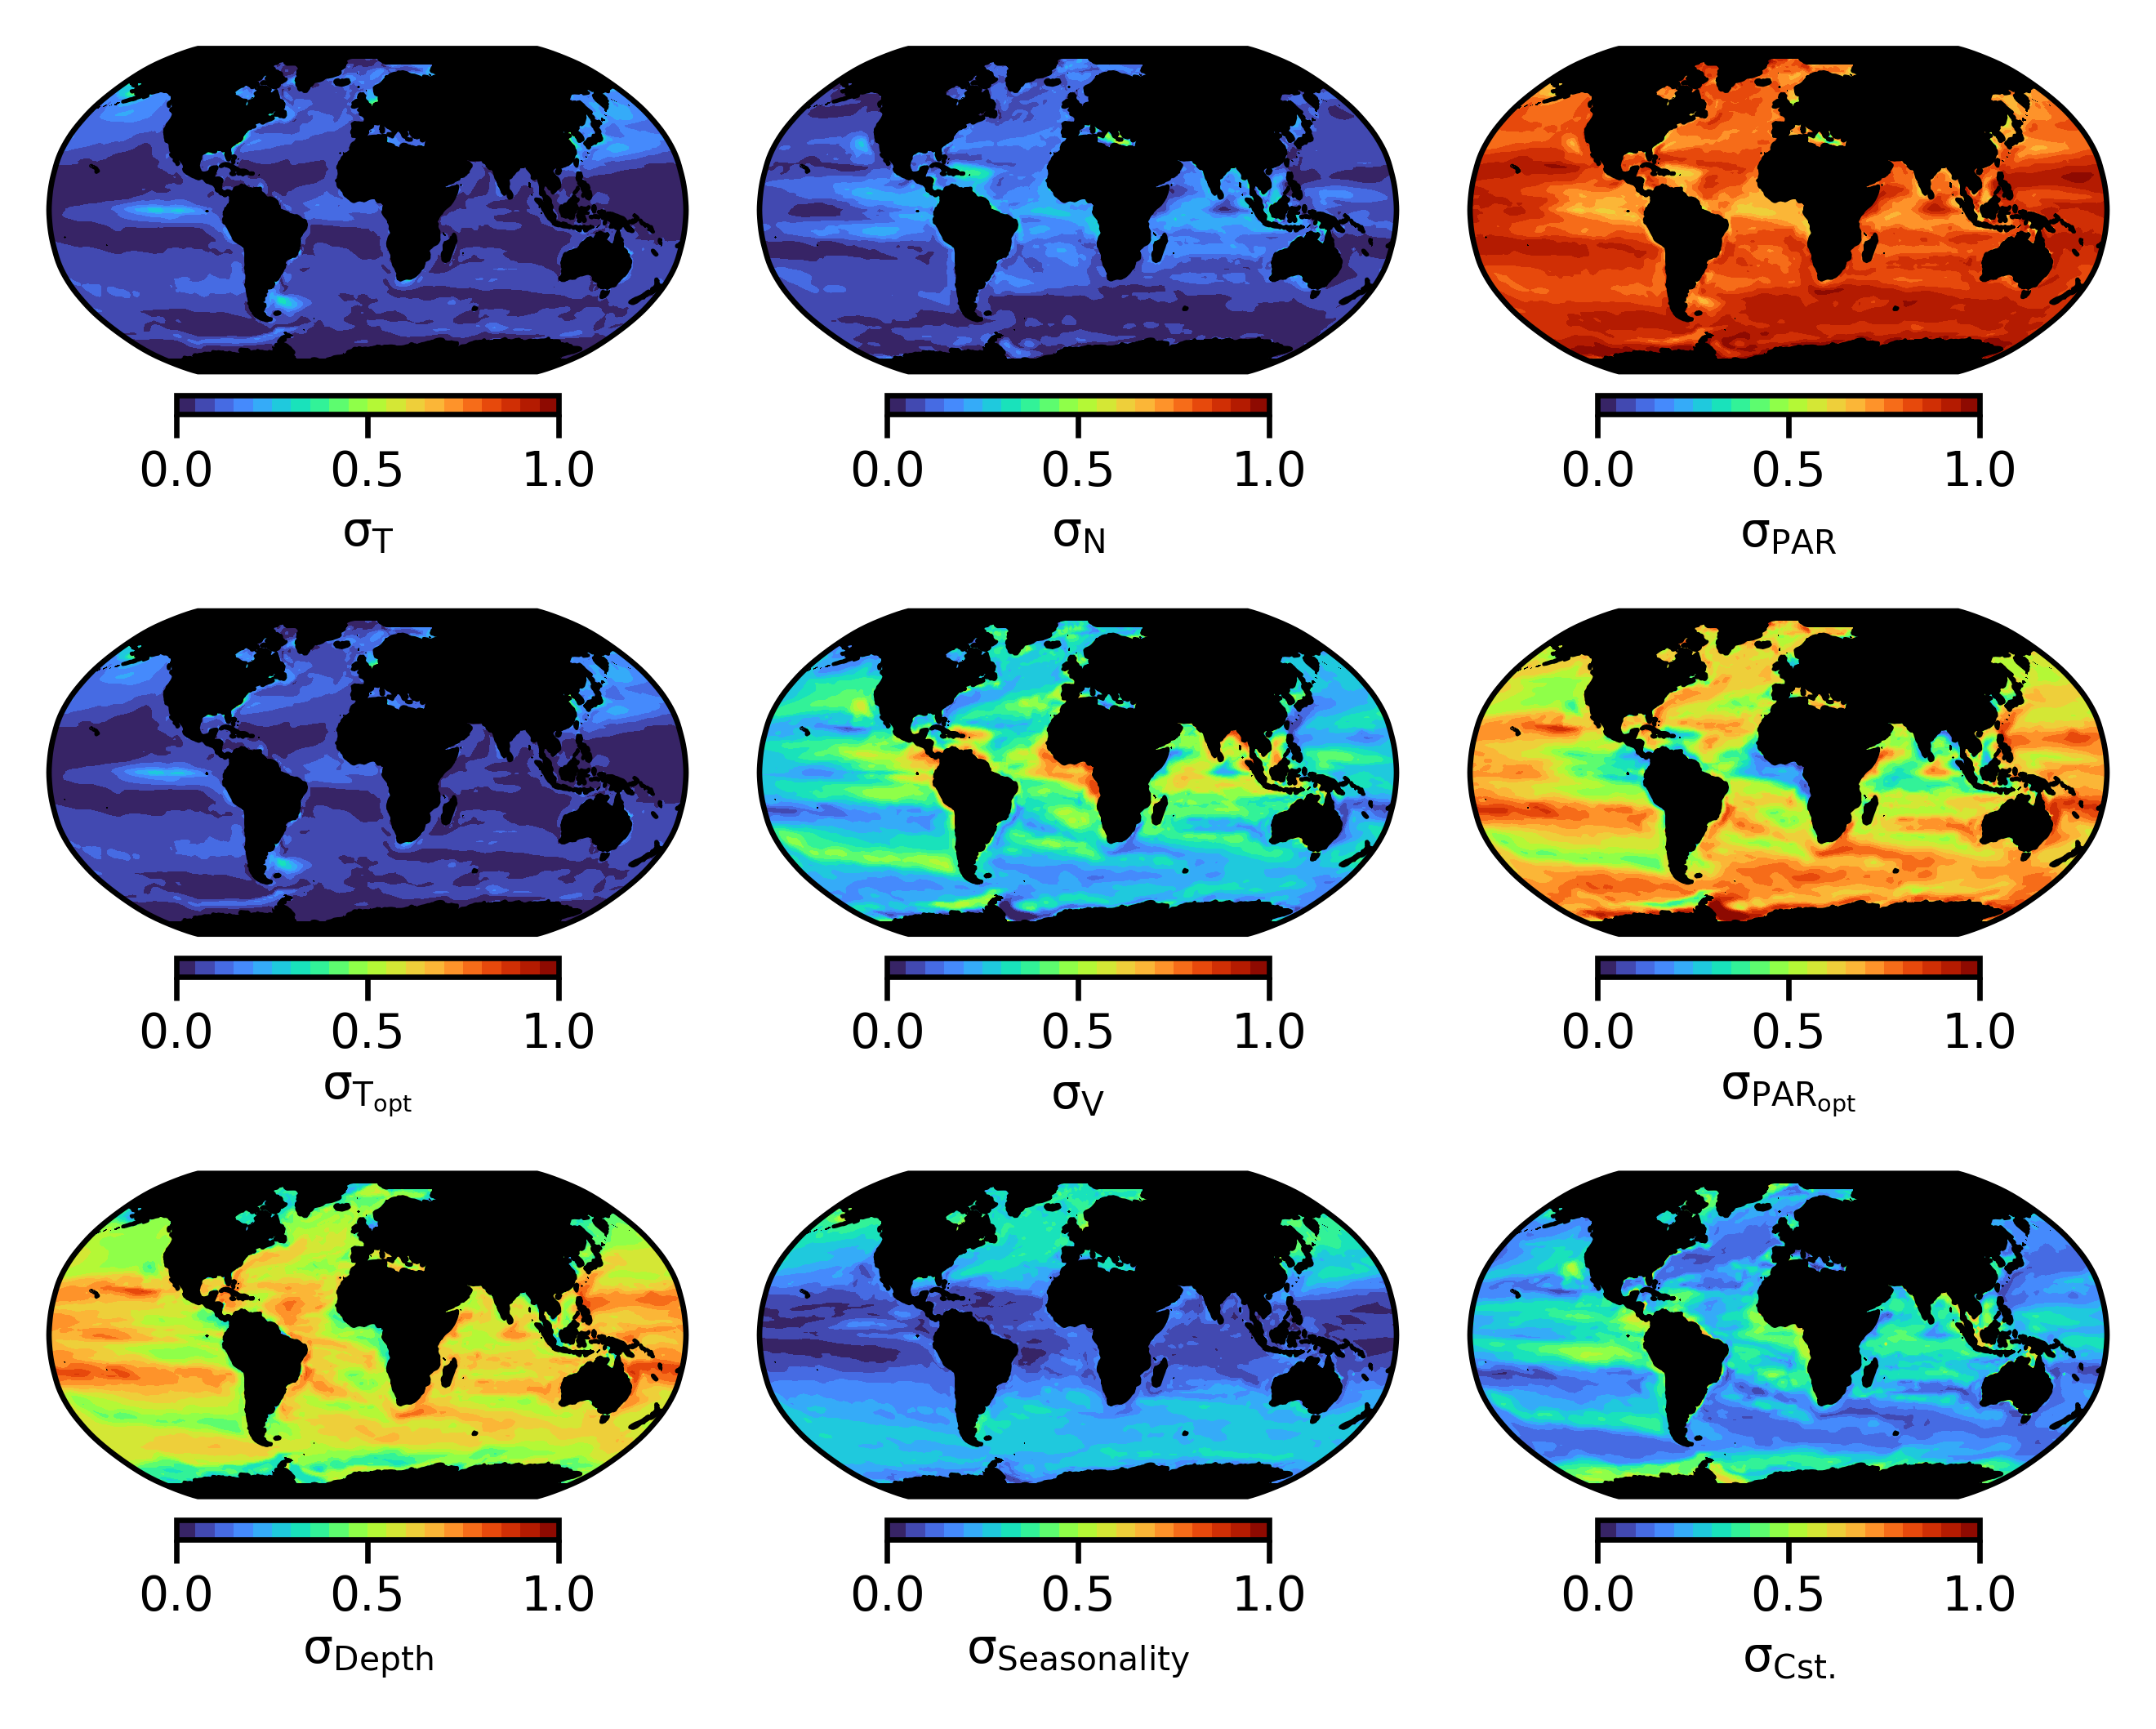

In [214]:
fig = plt.figure(figsize=(4.5,3.75))  # largeur augmentée pour 2 colonnes

ax1 = fig.add_subplot(331,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-DF_pop_T_zt/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel(r'$\mathrm{\sigma_T}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(332,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-DF_pop_N_zt/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('$\mathrm{\sigma_N}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(333,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-DF_pop_L_zt/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('$\mathrm{\sigma_{PAR}}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(334,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-DF_pop_Topt_zt/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('$\mathrm{\sigma_{T_{opt}}}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(335,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-DF_pop_S_zt/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('$\mathrm{\sigma_{V}}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(336,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-DF_pop_Lopt_zt/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('$\mathrm{\sigma_{PAR_{opt}}}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(337,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-(DF_var_z_L*DF_pop_Lopt_zt+DF_var_z_T*DF_pop_Topt_zt+DF_var_z_S*DF_pop_S_zt)/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('$\mathrm{\sigma_{Depth}}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(338,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-(DF_var_t_L*DF_pop_Lopt_zt+DF_var_t_T*DF_pop_Topt_zt+DF_var_t_S*DF_pop_S_zt)/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('$\mathrm{\sigma_{Seasonality}}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

ax1 = fig.add_subplot(339,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
p1 = ax1.contourf(lon,lat,-(DF_moy_L*DF_pop_Lopt_zt+DF_moy_T*DF_pop_Topt_zt+DF_moy_S*DF_pop_S_zt)/DF_pop_zt,np.linspace(0,1,21),transform=ccrs.PlateCarree(),cmap='turbo')
ax1.add_feature(cfeature.LAND, facecolor='black', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(p1,shrink=0.60,orientation='horizontal',pad=0.05)
c1.ax.set_xticks([0,0.5,1],minor=False)
c1.ax.set_xticks([0,0.5,1],minor=True)
c1.ax.tick_params(labelsize=7)
c1.ax.tick_params(pad=1.5)
c1.ax.set_xlabel('$\mathrm{\sigma_{Cst.}}$',rotation=0,fontsize=7,labelpad=2)
ax1.set_global()

fig.tight_layout()
plt.show()

## - Regional analysis

In [216]:
# North Atlantic
la,lo  = 160-42,305

SST_NA  = T[:,:,la,lo]
Topt_NA = Topt_mutALL[:,:,la,lo]

SST_NA_z  = np.ma.sum(SST_NA*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)
Topt_NA_z = np.ma.sum(Topt_NA*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)

Size_opt_NA_z = np.ma.sum(np.log(10**(Size_opt[:,:,la,lo]))*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)
Size_NA_z     = np.ma.sum(Size_mutALL[:,:,la,lo]*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)
ESD_opt_NA_z  = (3/4*1/np.pi*np.exp(Size_opt_NA_z))**(1/3)*2
ESD_NA_z      = (3/4*1/np.pi*np.exp(Size_NA_z))**(1/3)*2

Lopt_star_NA_z = np.ma.sum(PAR_opt[:,:,la,lo]*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)
Lopt_NA_z      = np.ma.sum(Lopt_mutALL[:,:,la,lo]*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)

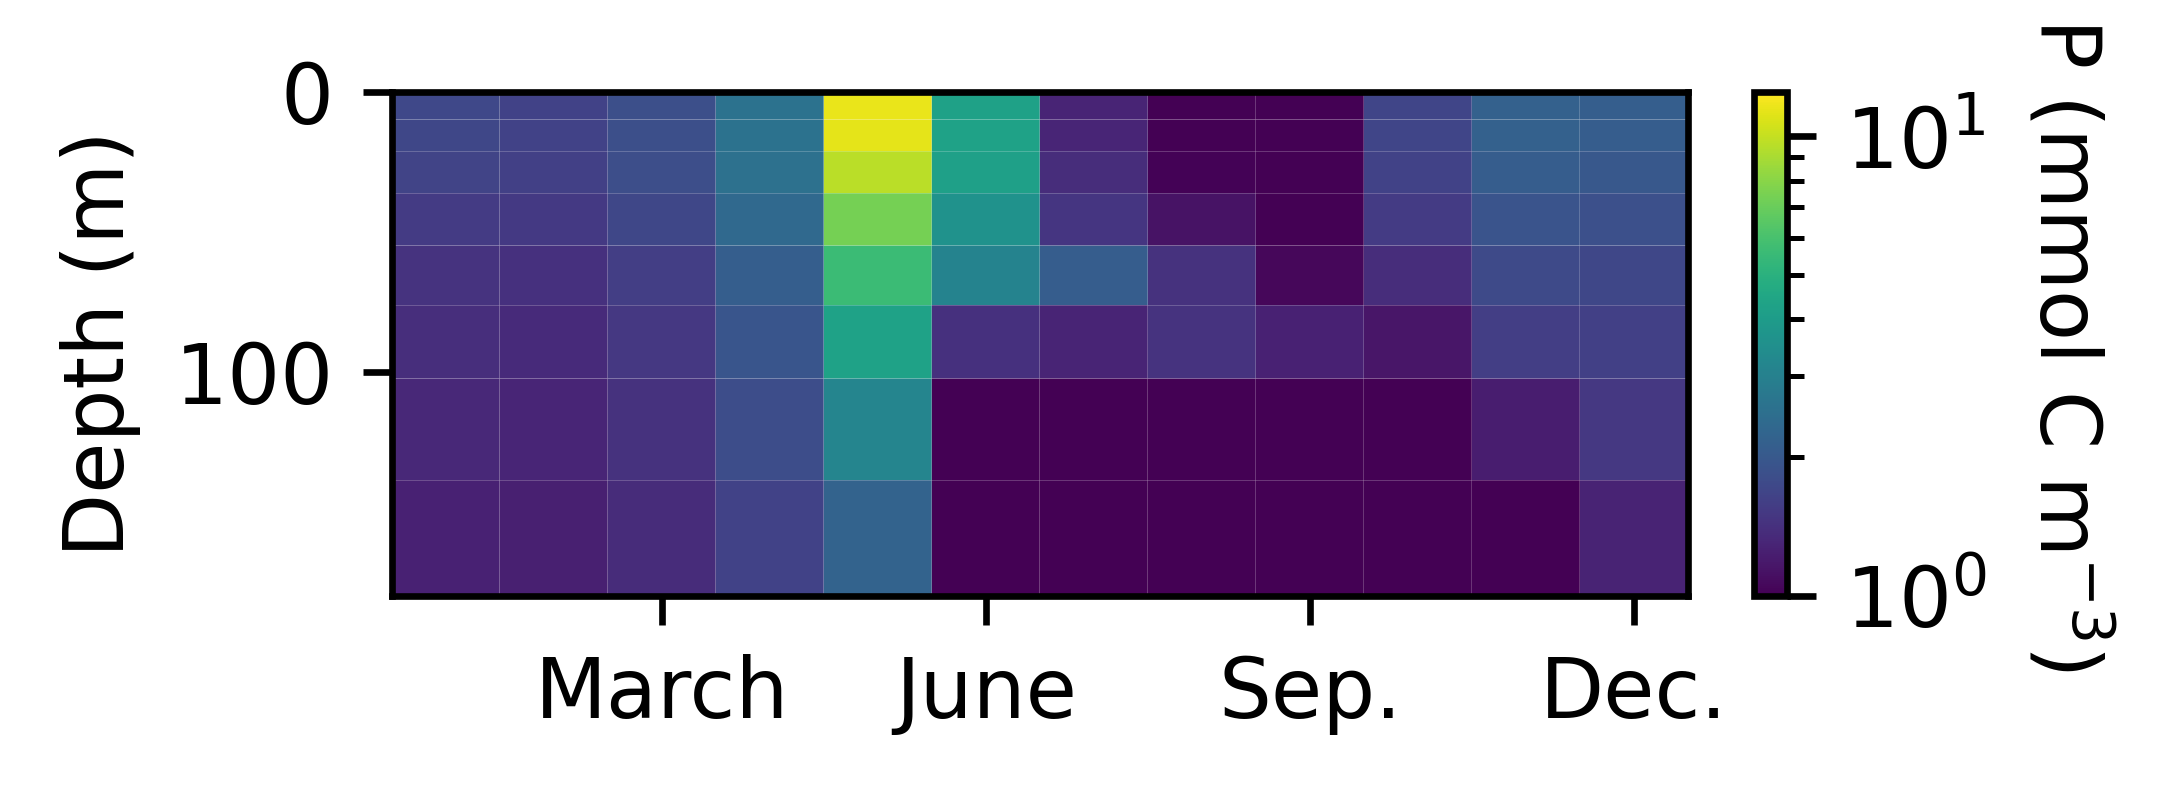

In [217]:
fig = plt.figure(figsize=(3,2))

gs = GridSpec(2, 2,width_ratios=[1, 0.025],height_ratios=[2, 3])

ax2 = fig.add_subplot(gs[1,0])
pc = plt.pcolor(np.arange(12),middle,C_mutALL[:,:,la,lo].T,norm=mpl.colors.LogNorm(vmin=1,vmax=12.5),edgecolor='white',lw=0.01)
ax2.set_ylim(180,0)
ax2.set_ylabel('Depth (m)')
ax2.set_xticks([11,2,5,8])
ax2.set_xticklabels(['Dec.','March','June','Sep.'])
axcb = fig.add_subplot(gs[1,1])
cb = fig.colorbar(pc,axcb)
cb.ax.set_ylabel('P (mmol C m$^{-3}$)',rotation=-90,labelpad=15)

fig.subplots_adjust(wspace=0.1)
#fig.tight_layout()

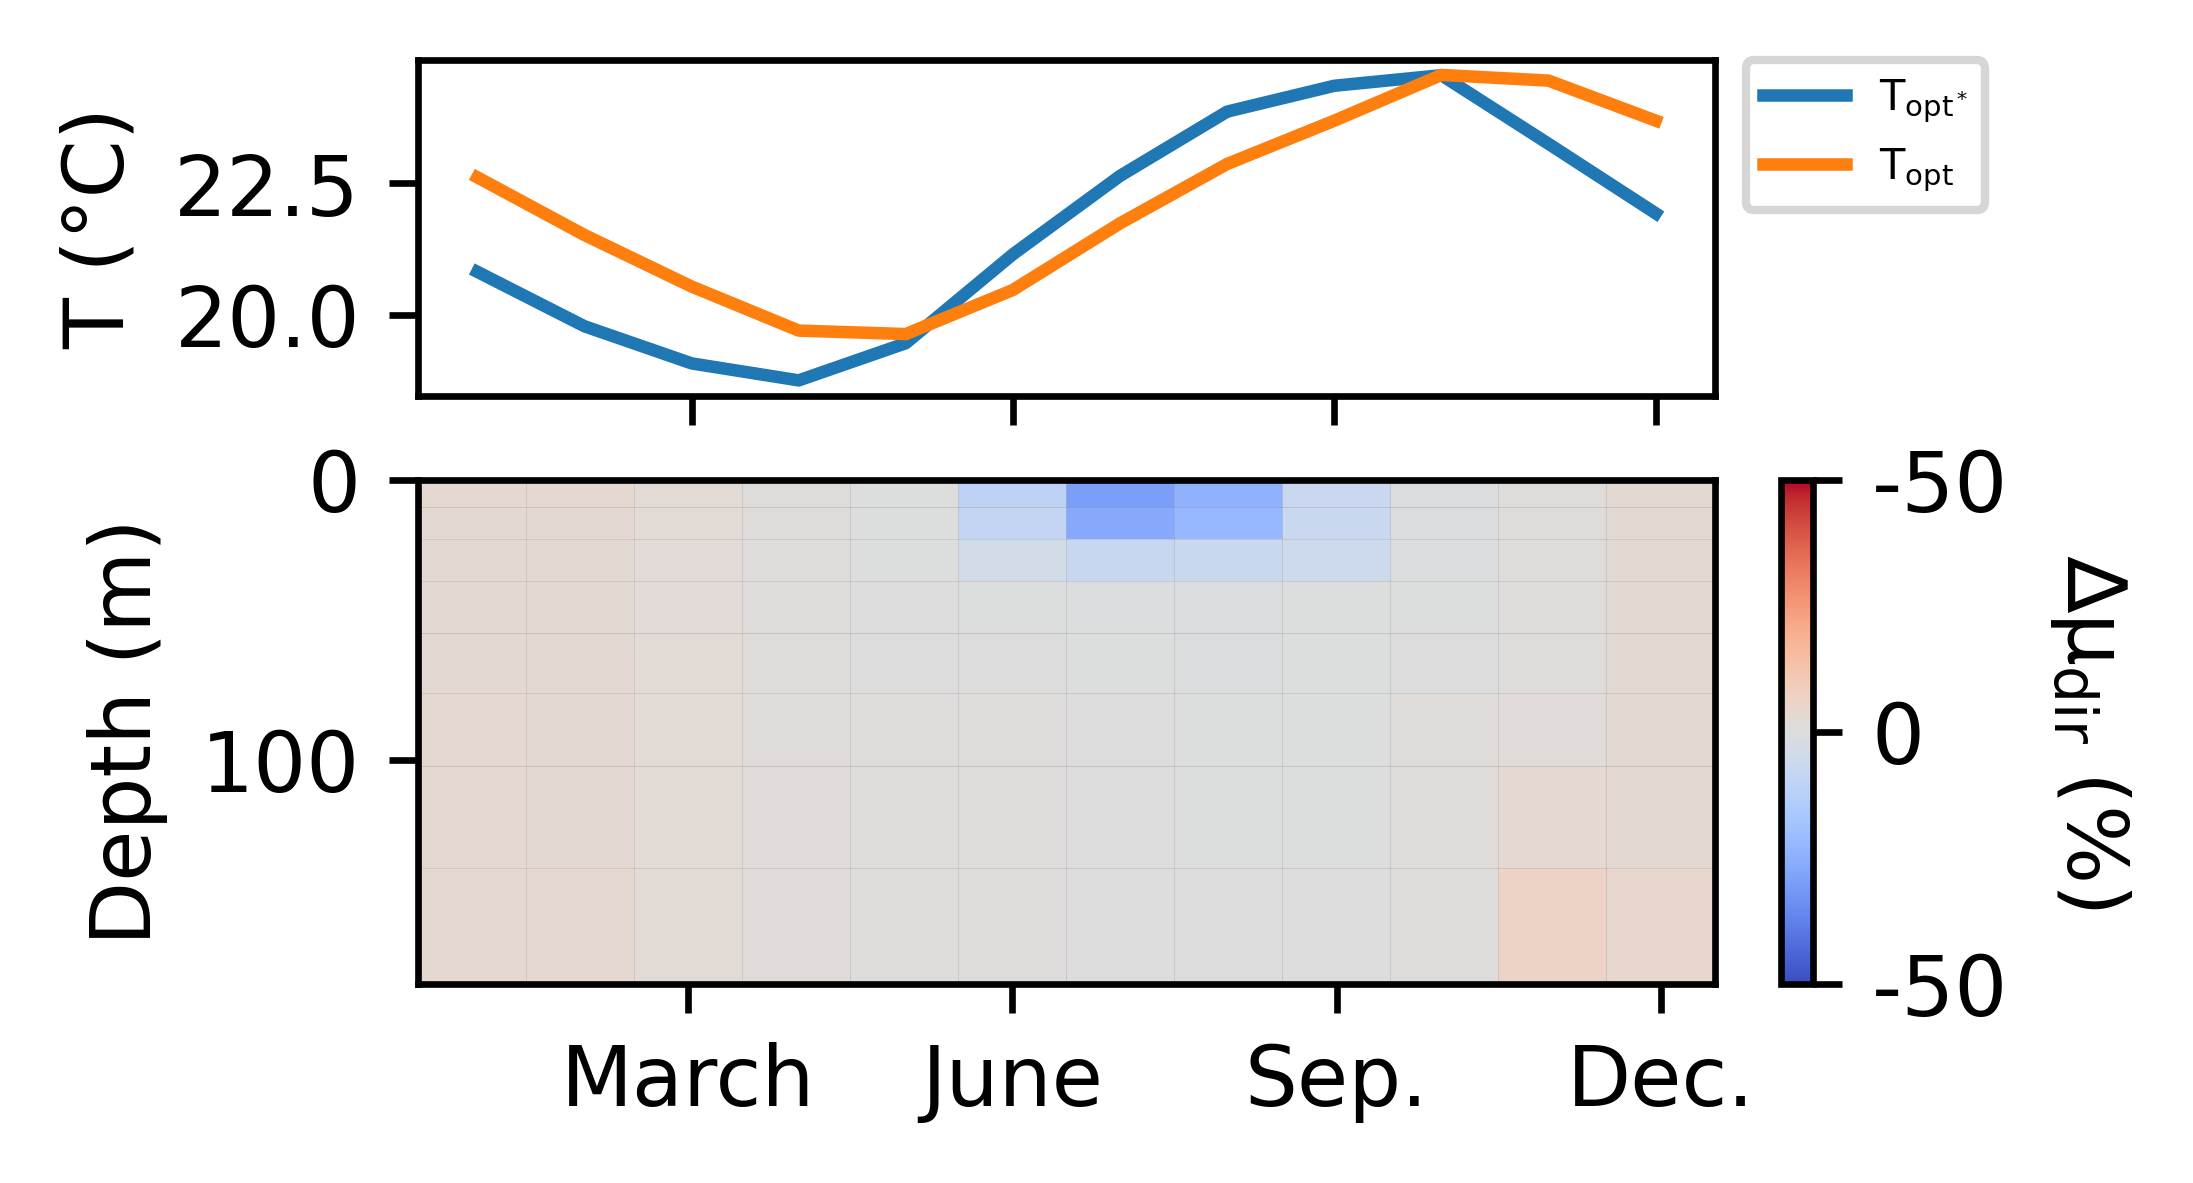

In [218]:
fig = plt.figure(figsize=(3,2))

gs = GridSpec(2, 2,width_ratios=[1, 0.025],height_ratios=[2, 3])

ax1 = fig.add_subplot(gs[0,0])
ax1.plot(SST_NA_z-(0.056*(5.)**2.)/(0.056*5. - 1.),label='T$_{\mathrm{opt}^*}$')
ax1.plot(Topt_NA_z,label='T$_{\mathrm{opt}}$')
ax1.set_xticks([11,2,5,8])
ax1.set_xticklabels([])
ax1.set_ylabel('T (°C)')
plt.legend(fontsize=5,bbox_to_anchor=(1.225, 0, 0, 1.06))

ax2 = fig.add_subplot(gs[1,0])
pc = ax2.pcolor(np.arange(12),middle,Floss_T_dir[:,:,la,lo].T,vmin=-0.5,vmax=0.5,cmap='coolwarm',edgecolor='black',lw=0.01)
ax2.set_ylim(180,0)
ax2.set_ylabel('Depth (m)')
ax2.set_xticks([11,2,5,8])
ax2.set_xticklabels(['Dec.','March','June','Sep.'])
axcb = fig.add_subplot(gs[1,1])
cb = fig.colorbar(pc,axcb)
axcb.set_yticks([-0.5,0,0.5])
axcb.set_yticklabels([-50,0,-50])
axcb.set_ylabel('∆µ$_{\mathrm{dir}}$ (%)',rotation=-90,labelpad=15)

fig.subplots_adjust(wspace=0.1)
#fig.tight_layout()

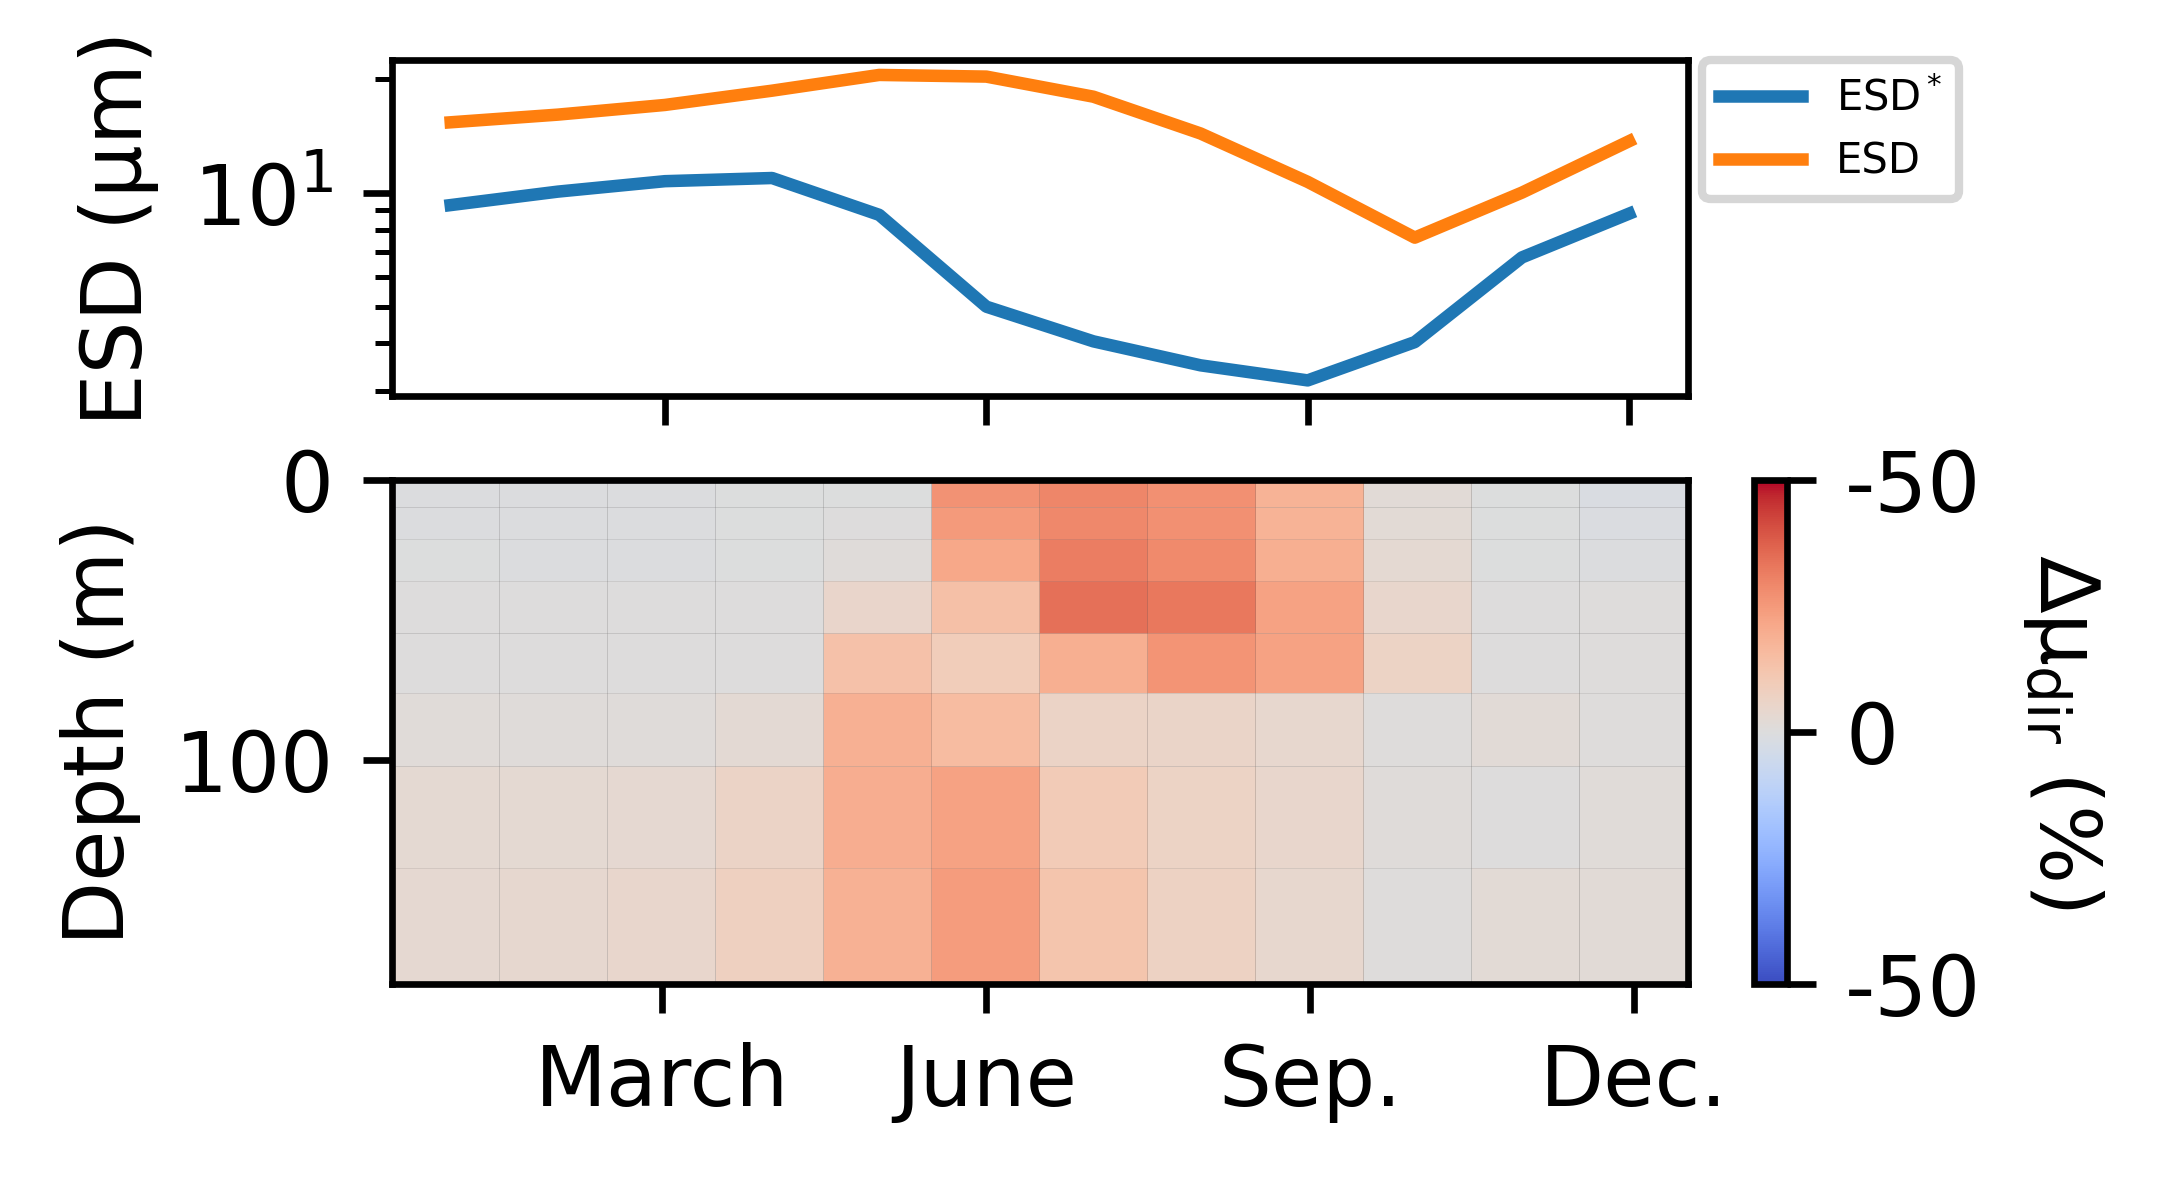

In [219]:
fig = plt.figure(figsize=(3,2))

gs = GridSpec(2, 2,width_ratios=[1, 0.025],height_ratios=[2, 3])

ax1 = fig.add_subplot(gs[0,0])
ax1.plot(ESD_opt_NA_z,label='ESD$^*$')
ax1.plot(ESD_NA_z,label='ESD')
ax1.set_yscale('log')
ax1.set_yticks([10])
ax1.set_yticklabels([],minor=True)
ax1.set_xticks([11,2,5,8])
ax1.set_xticklabels([])
ax1.set_ylabel('ESD (µm)')
plt.legend(fontsize=5,bbox_to_anchor=(1.225, 0, 0, 1.06))

ax2 = fig.add_subplot(gs[1,0])
pc = ax2.pcolor(np.arange(12),middle,Floss_S_dir[:,:,la,lo].T,vmin=-0.5,vmax=0.5,cmap='coolwarm',edgecolor='black',lw=0.01)
ax2.set_ylim(180,0)
ax2.set_ylabel('Depth (m)')
ax2.set_xticks([11,2,5,8])
ax2.set_xticklabels(['Dec.','March','June','Sep.'])
axcb = fig.add_subplot(gs[1,1])
cb = fig.colorbar(pc,axcb)
axcb.set_yticks([-0.5,0,0.5])
axcb.set_yticklabels([-50,0,-50])
axcb.set_ylabel('∆µ$_{\mathrm{dir}}$ (%)',rotation=-90,labelpad=15)

fig.subplots_adjust(wspace=0.1)
#fig.tight_layout()

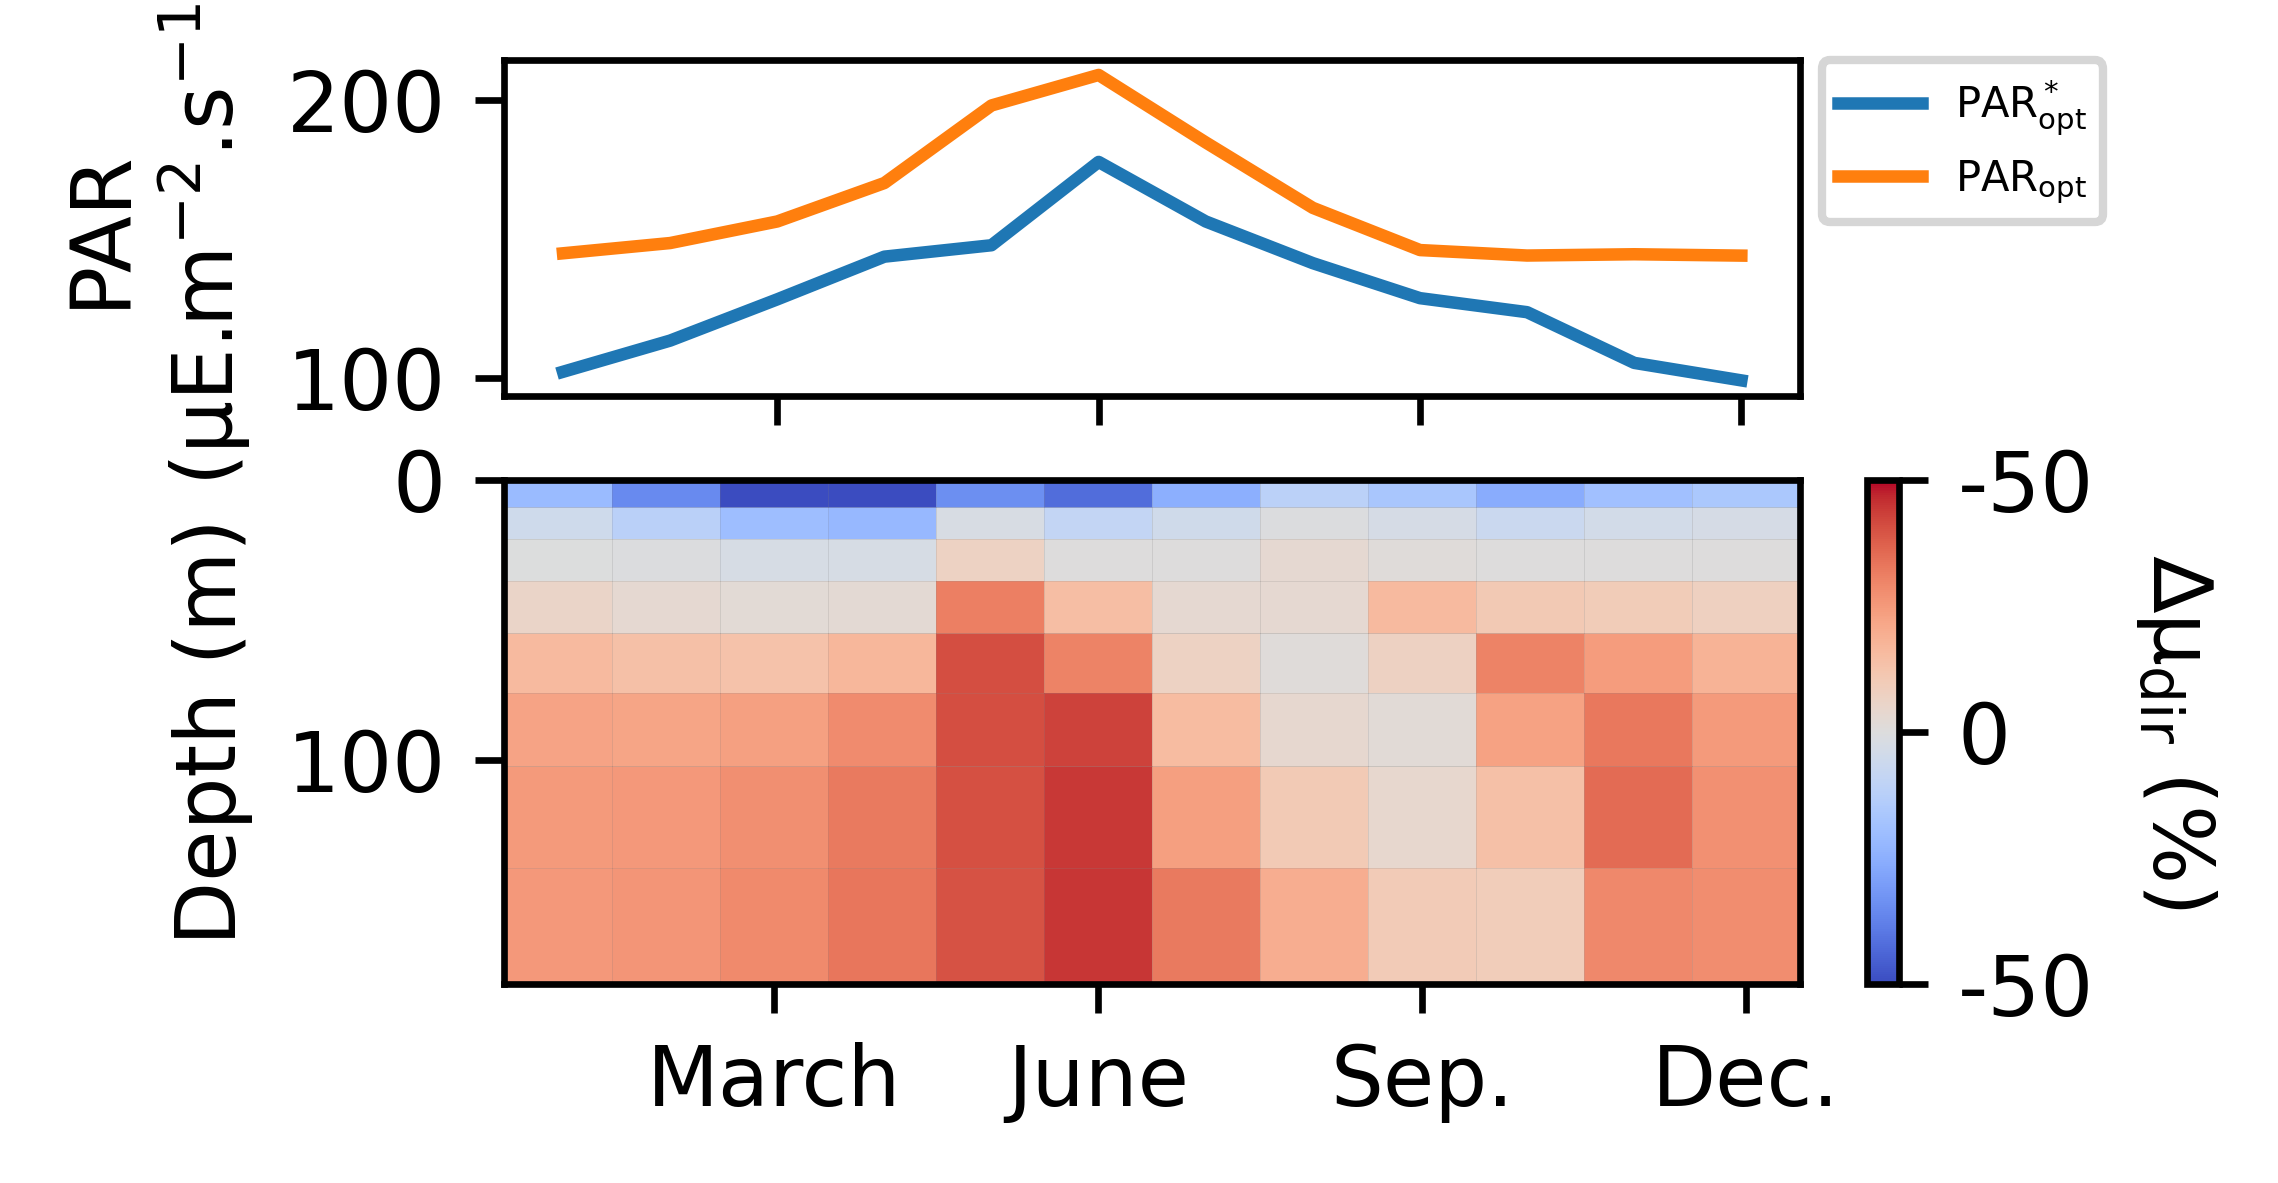

In [220]:
fig = plt.figure(figsize=(3,2))

gs = GridSpec(2, 2,width_ratios=[1, 0.025],height_ratios=[2, 3])

ax1 = fig.add_subplot(gs[0,0])
ax1.plot(Lopt_star_NA_z,label='PAR$_{\mathrm{opt}}^*$')
ax1.plot(np.exp(Lopt_NA_z),label='PAR$_{\mathrm{opt}}$')
#ax1.set_yscale('log')
#ax1.set_yticks([10])
#ax1.set_yticklabels([],minor=True)
ax1.set_xticks([11,2,5,8])
ax1.set_xticklabels([])
ax1.set_ylabel('PAR\n(µE.m$^{-2}$.s$^{-1}$)')
plt.legend(fontsize=5,bbox_to_anchor=(1.25, 0, 0, 1.06))

ax2 = fig.add_subplot(gs[1,0])
pc = ax2.pcolor(np.arange(12),middle,Floss_L_dir[:,:,la,lo].T,vmin=-0.5,vmax=0.5,cmap='coolwarm',edgecolor='black',lw=0.01)
ax2.set_ylim(180,0)
ax2.set_ylabel('Depth (m)')
ax2.set_xticks([11,2,5,8])
ax2.set_xticklabels(['Dec.','March','June','Sep.'])
axcb = fig.add_subplot(gs[1,1])
cb = fig.colorbar(pc,axcb)
axcb.set_yticks([-0.5,0,0.5])
axcb.set_yticklabels([-50,0,-50])
axcb.set_ylabel('∆µ$_{\mathrm{dir}}$ (%)',rotation=-90,labelpad=15)

fig.subplots_adjust(wspace=0.1)
plt.savefig('temp.png',bbox_inches='tight',pad_inches=0.2)
#fig.tight_layout()

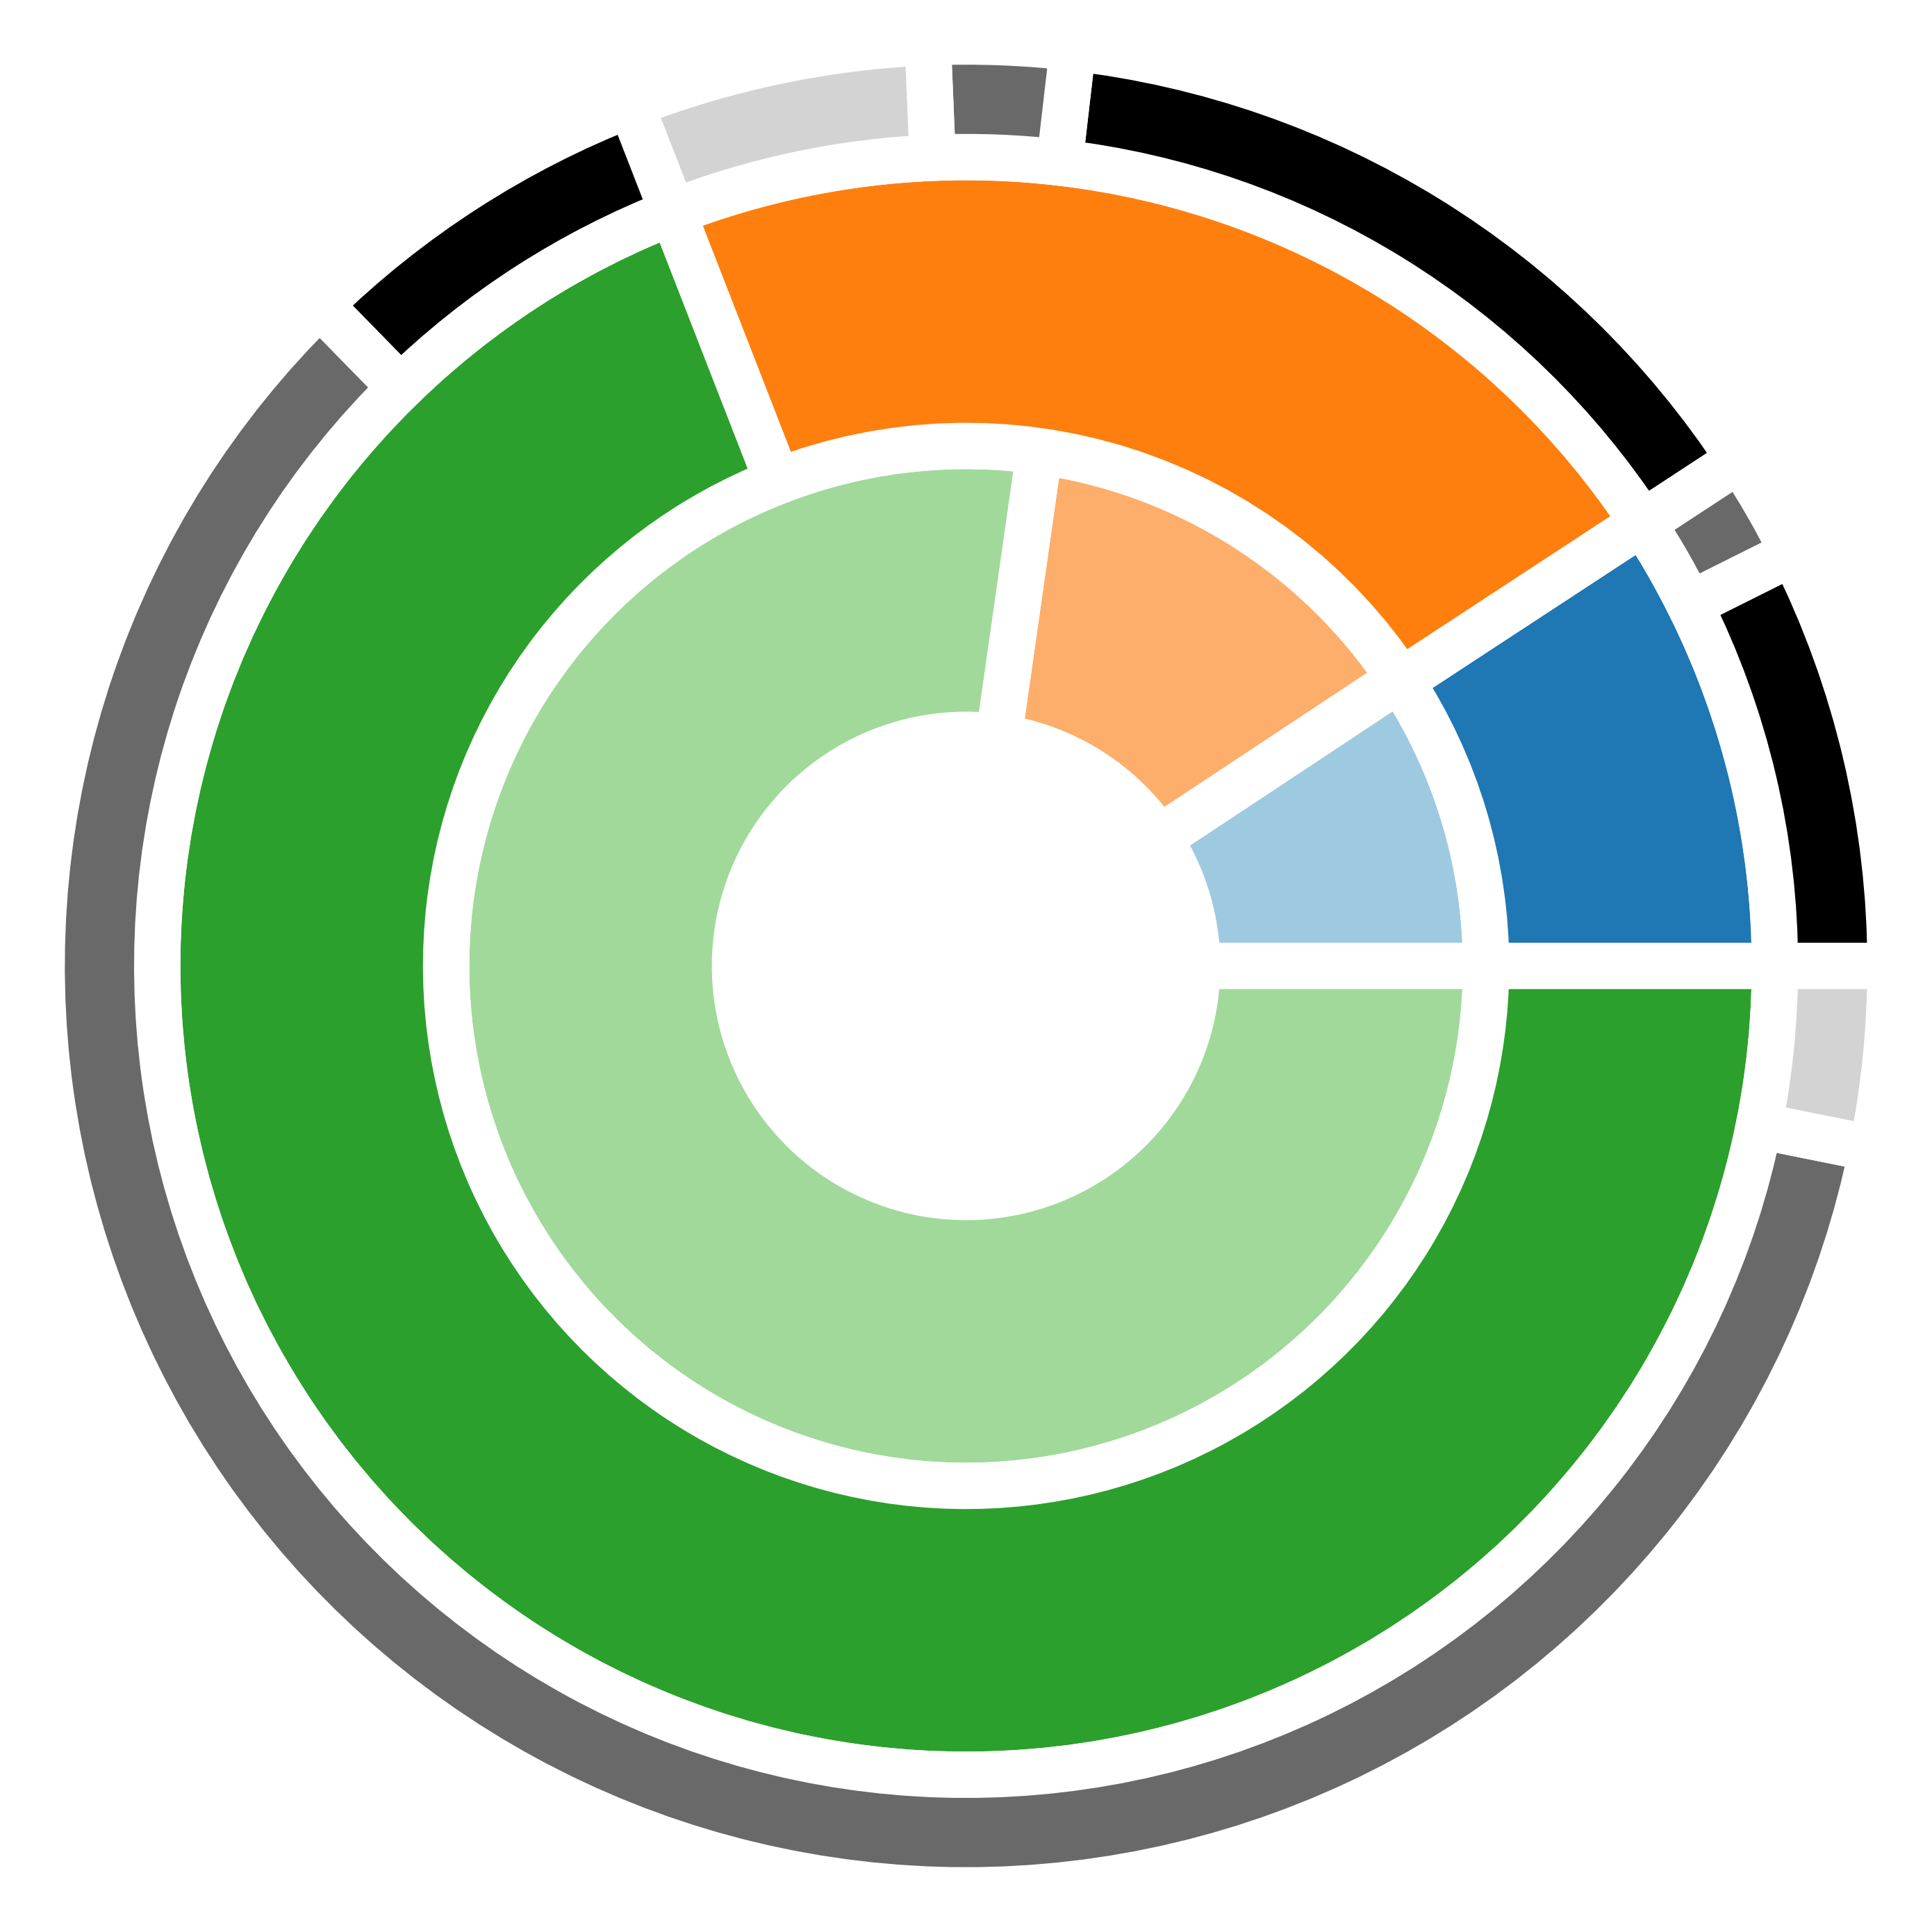

In [221]:
fig = plt.figure(facecolor='None')

val1 = [DF_pop_T_zt[la,lo],DF_pop_N_zt[la,lo],DF_pop_L_zt[la,lo]]
val0 = [DF_pop_Topt_zt[la,lo],DF_pop_S_zt[la,lo],DF_pop_Lopt_zt[la,lo]]
val2 = (np.array([DF_var_t_T[la,lo],DF_var_z_T[la,lo],DF_moy_T[la,lo]])*DF_pop_Topt_zt[la,lo]).tolist()+(np.array([DF_var_t_S[la,lo],DF_var_z_S[la,lo],DF_moy_S[la,lo]])*DF_pop_S_zt[la,lo]).tolist()+(np.array([DF_var_t_L[la,lo],DF_var_z_L[la,lo],DF_moy_L[la,lo]])*DF_pop_Lopt_zt[la,lo]).tolist()

inner_col = [tab20c[i] for i in [2,6,10]]
col2 = ['black','dimgrey','lightgrey']*3
wedges,  texts  = plt.pie(val1, radius=0.9, wedgeprops=dict(width=0.5,edgecolor='w',linewidth=8),colors=inner_col)
wedges2, texts2 = plt.pie(val0, radius=1.4, wedgeprops=dict(width=0.5,edgecolor='w',linewidth=8))
wedges3, texts3 = plt.pie(val2, radius=1.6, wedgeprops=dict(width=0.2,edgecolor='w',linewidth=8),colors=col2)
#wedges2, texts2 = plt.pie(val2, radius=1.4, wedgeprops=dict(width=0.5,edgecolor='w',linewidth=10),colors=outer_col)

#plt.legend(wedges2,outer_lab,bbox_to_anchor=(1.25, 0, 0.5, 1.05),frameon=False,fontsize=16.5)
#plt.legend(wedges ,inner_lab,bbox_to_anchor=(1.25, 0, 0.5, 0.55),frameon=False,fontsize=16.5)
fig.tight_layout()
plt.show()

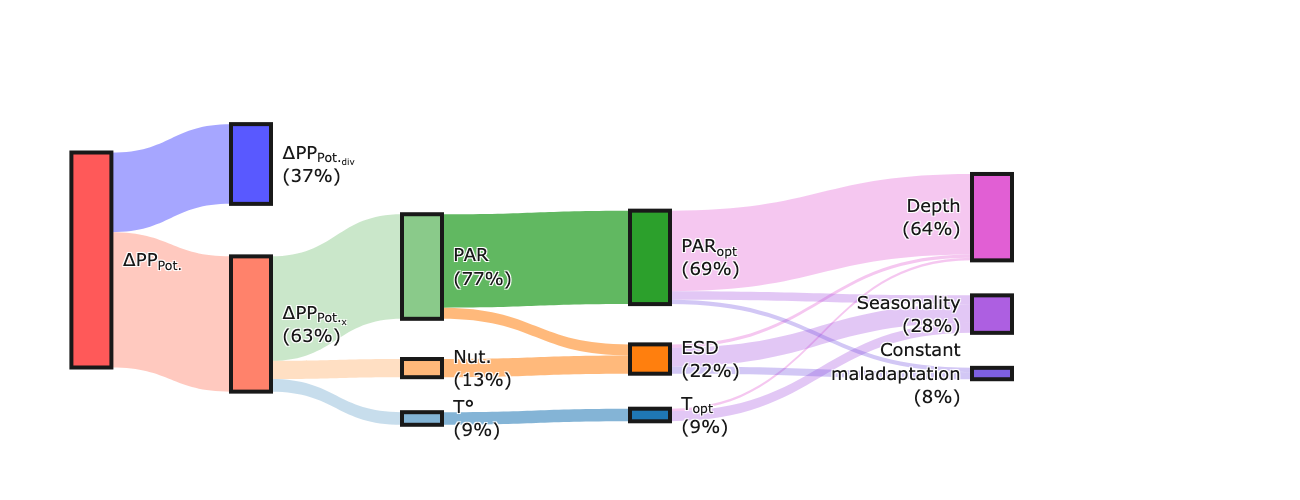

In [223]:
col2 = ['#AD5FE1','#E15FD4','#7D5FE1']

vec = [np.array((val1[0], val1[1], val1[2]))[i] for i in [2,1,0]]/np.sum(val1)
y1  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(2)]
y1  = [y1[i] for i in [2,1,0]]
vec = [np.array((val0[0], val0[1], val0[2]))[i] for i in [2,1,0]]/np.sum(val0)
y2  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(2)]
y2  = [y2[i] for i in [2,1,0]]
vec = [np.array([np.sum(val2[i::4]/np.sum(val2)) for i in np.arange(4)])[i] for i in [0,1,2]]
y3  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(3)]
y3  = [y3[i] for i in [0,1,2]]

y1c = recenter(y1, target=0.6, scale=0.7)
y2c = recenter(y2, target=0.6, scale=0.7)
y3c = recenter(y3, target=0.6, scale=0.7)

contrib = np.array([val1/np.sum(val1),val0/np.sum(val1),np.array([np.sum(val2[i::3])/np.sum(val1) for i in range(3)])]).ravel()

# --- NOUVEAU : valeurs / apparence des deux nodes ajoutés ---
val_root   = [np.sum(val0), -DF_div_pop_zt[la,lo]-np.sum(val0)]      # <- valeur du lien "nouveau racine -> node0" et "nouveau racine -> node aligné"
contrib_root = -np.array(val_root)/DF_div_pop_zt[la,lo]
label_root = " ∆PP<sub>Pot.</sub> "      # <- à adapter
label_sib  = " ∆PP<sub>Pot.<sub>div</sub></sub> <br> ("+str(int(round(contrib_root[1]*100,0)))+"%) "  # <- à adapter
color_root = pastel('grey', 0.2, 1)   # <- à adapter
color_sib  = pastel('grey', 0.45, 1)  # <- à adapter
y_root     = 0.5    # position verticale du node tout à gauche
y_sib      = 0.2   # position verticale du node "frère" du node0 (à ajuster selon tes valeurs)
# --------------------------------------------------------------

fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node = dict(
      pad = 35,
      thickness = 40,
      line = dict(color = pastel('black',0.1,1), width = 4),
      label = [" ∆PP<sub>Pot.<sub>x</sub></sub> <br> ("+str(int(round(contrib_root[0]*100,0)))+"%) "," T° <br> ("+str(int(round(contrib[0]*100,0)))+"%) ", " Nut. <br> ("+str(int(round(contrib[1]*100,0)))+"%) ", " PAR <br> ("+str(int(round(contrib[2]*100,0)))+"%) ", " T<sub>opt</sub> <br> ("+str(int(round(contrib[3]*100,0)))+"%) ", " ESD <br> ("+str(int(round(contrib[4]*100,0)))+"%) ", " PAR<sub>opt</sub> <br> ("+str(int(round(contrib[5]*100,0)))+"%) ", "Seasonality <br>("+str(int(round(contrib[6]*100,0)))+"%) ","Depth <br>("+str(int(round(contrib[7]*100,0)))+"%) ","Constant <br>maladaptation <br>("+str(int(round(contrib[8]*100,0)))+"%) ",label_root,label_sib],
      color = [pastel('tomato',0.2,1)]+[pastel(base_col[i], 0.45) for i in range(len(base_col))]+base_col+col2+[pastel('red',0.,alpha=0.65),pastel('blue',0.,alpha=0.65)],
      x = [0.15,0.3,0.3,0.3,0.5,0.5,0.5,0.8,0.8,0.8,0.01,0.15],
      y = [0.7]+y1c+y2c+y3c+[y_root, y_sib]
      ),
    link = dict(
      source = [10,10,0, 0, 0, 1, 2, 3, 3, 4, 4, 4, 5, 5, 5, 6, 6, 6],
      target = [ 0,11,1, 2, 3, 4, 5, 5, 6, 7, 8, 9, 7, 8, 9, 7, 8, 9],
      value  = val_root+[val1[0], val1[1], val1[2], val1[0], val1[1], val0[1]-val1[1], val0[2]]+val2,
      color  = [pastel('tomato',0.,0.35), pastel('blue',0.,alpha=0.35)]+[pastel(base_col[0], 0., alpha=0.25),pastel(base_col[1], 0., alpha=0.25),pastel(base_col[2], 0., alpha=0.25),
                pastel(base_col[0], 0., alpha=0.55),pastel(base_col[1], 0., alpha=0.55),pastel(base_col[1], 0., alpha=0.55),pastel(base_col[2], 0., alpha=0.75)]
               +[pastel(col2[0], 0.,alpha=0.35),pastel(col2[1], 0.,alpha=0.35),pastel(col2[2], 0.,alpha=0.35)]*3
               ,
      line = dict(color = pastel('black',0,0.), width = 0.25),
  ))])


fig.update_layout(font=dict(color=pastel('black',0.1,1)), font_size=18,width=1100,height=500)
fig.show()
fig.write_image("fig1.png",scale=6)

In [224]:
# Equatorial Atlantic
la,lo  = 160-80,350

SST_NA  = T[:,:,la,lo]
Topt_NA = Topt_mutALL[:,:,la,lo]

SST_NA_z  = np.ma.sum(SST_NA*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)
Topt_NA_z = np.ma.sum(Topt_NA*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)

Size_opt_NA_z = np.ma.sum(np.log(10**(Size_opt[:,:,la,lo]))*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)
Size_NA_z     = np.ma.sum(Size_mutALL[:,:,la,lo]*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)
ESD_opt_NA_z  = (3/4*1/np.pi*np.exp(Size_opt_NA_z))**(1/3)*2
ESD_NA_z      = (3/4*1/np.pi*np.exp(Size_NA_z))**(1/3)*2

Lopt_star_NA_z = np.ma.sum(PAR_opt[:,:,la,lo]*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)
Lopt_NA_z      = np.ma.sum(Lopt_mutALL[:,:,la,lo]*delZ[None,:]*C_mutALL[:,:,la,lo],1)/np.ma.sum(delZ[None,:]*C_mutALL[:,:,la,lo],1)

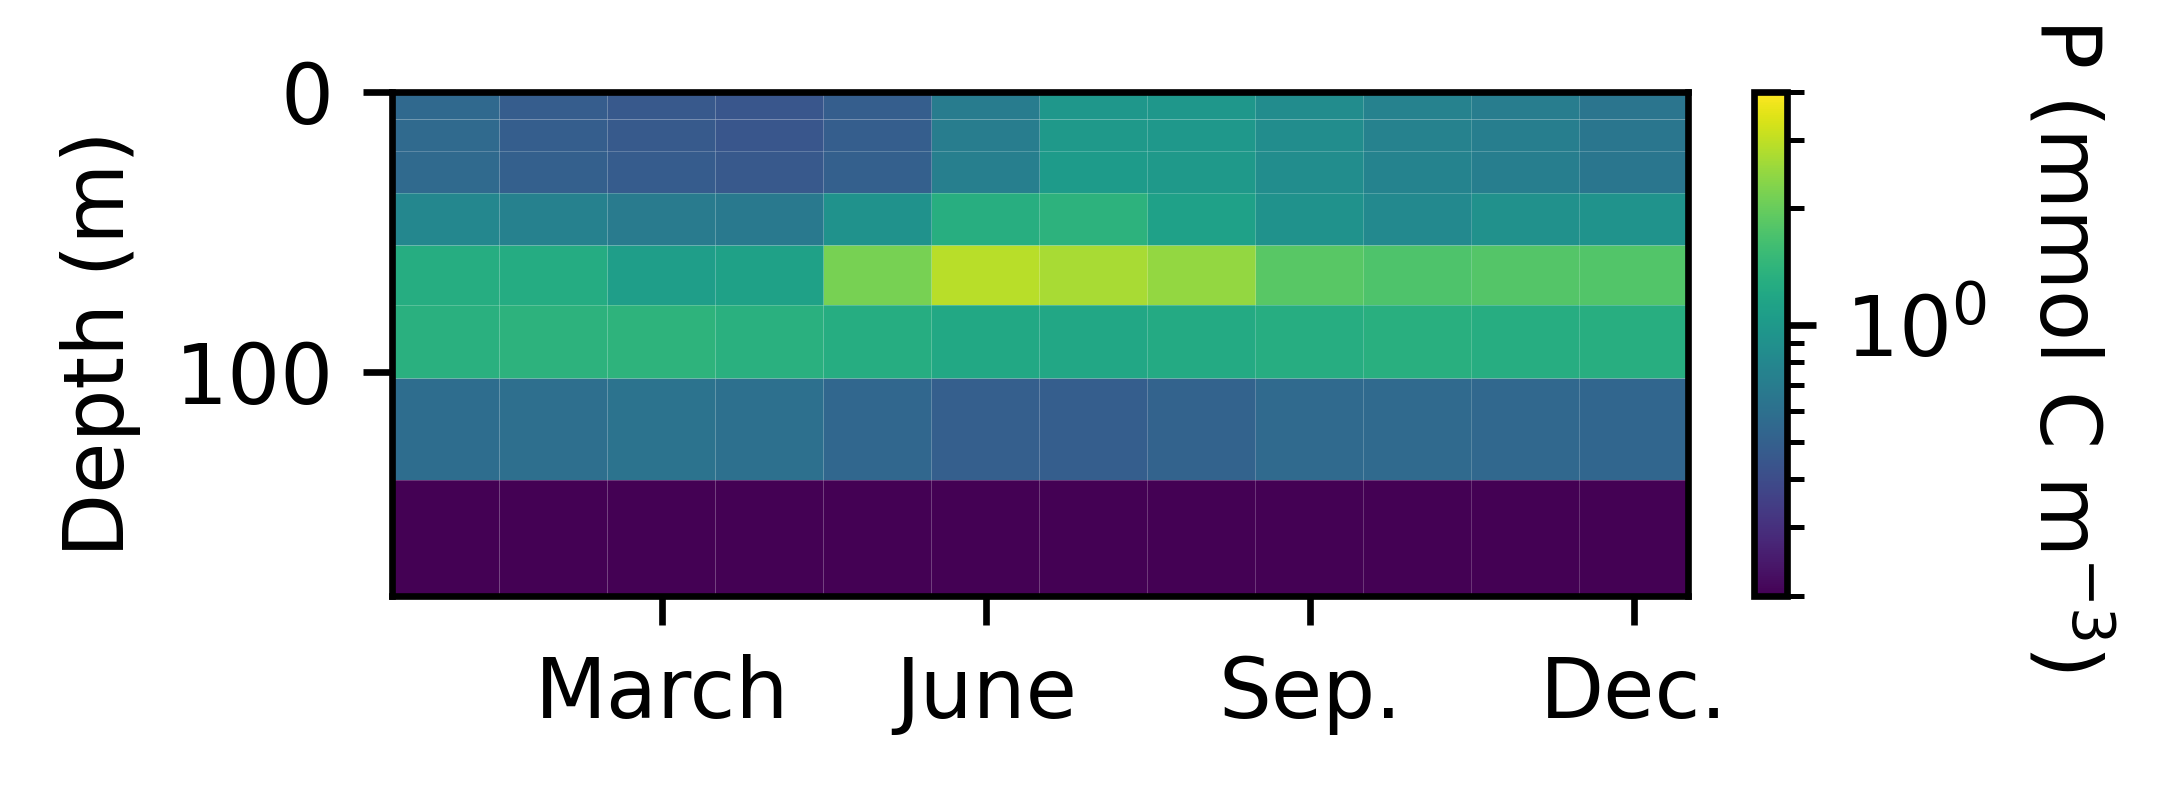

In [225]:
fig = plt.figure(figsize=(3,2))

gs = GridSpec(2, 2,width_ratios=[1, 0.025],height_ratios=[2, 3])

ax2 = fig.add_subplot(gs[1,0])
pc = plt.pcolor(np.arange(12),middle,C_mutALL[:,:,la,lo].T,norm=mpl.colors.LogNorm(vmin=0.2,vmax=4),edgecolor='white',lw=0.01)
ax2.set_ylim(180,0)
ax2.set_ylabel('Depth (m)')
ax2.set_xticks([11,2,5,8])
ax2.set_xticklabels(['Dec.','March','June','Sep.'])
axcb = fig.add_subplot(gs[1,1])
cb = fig.colorbar(pc,axcb)
cb.ax.set_ylabel('P (mmol C m$^{-3}$)',rotation=-90,labelpad=15)
cb.ax.set_yticklabels([],minor=True)

fig.subplots_adjust(wspace=0.1)
#fig.tight_layout()

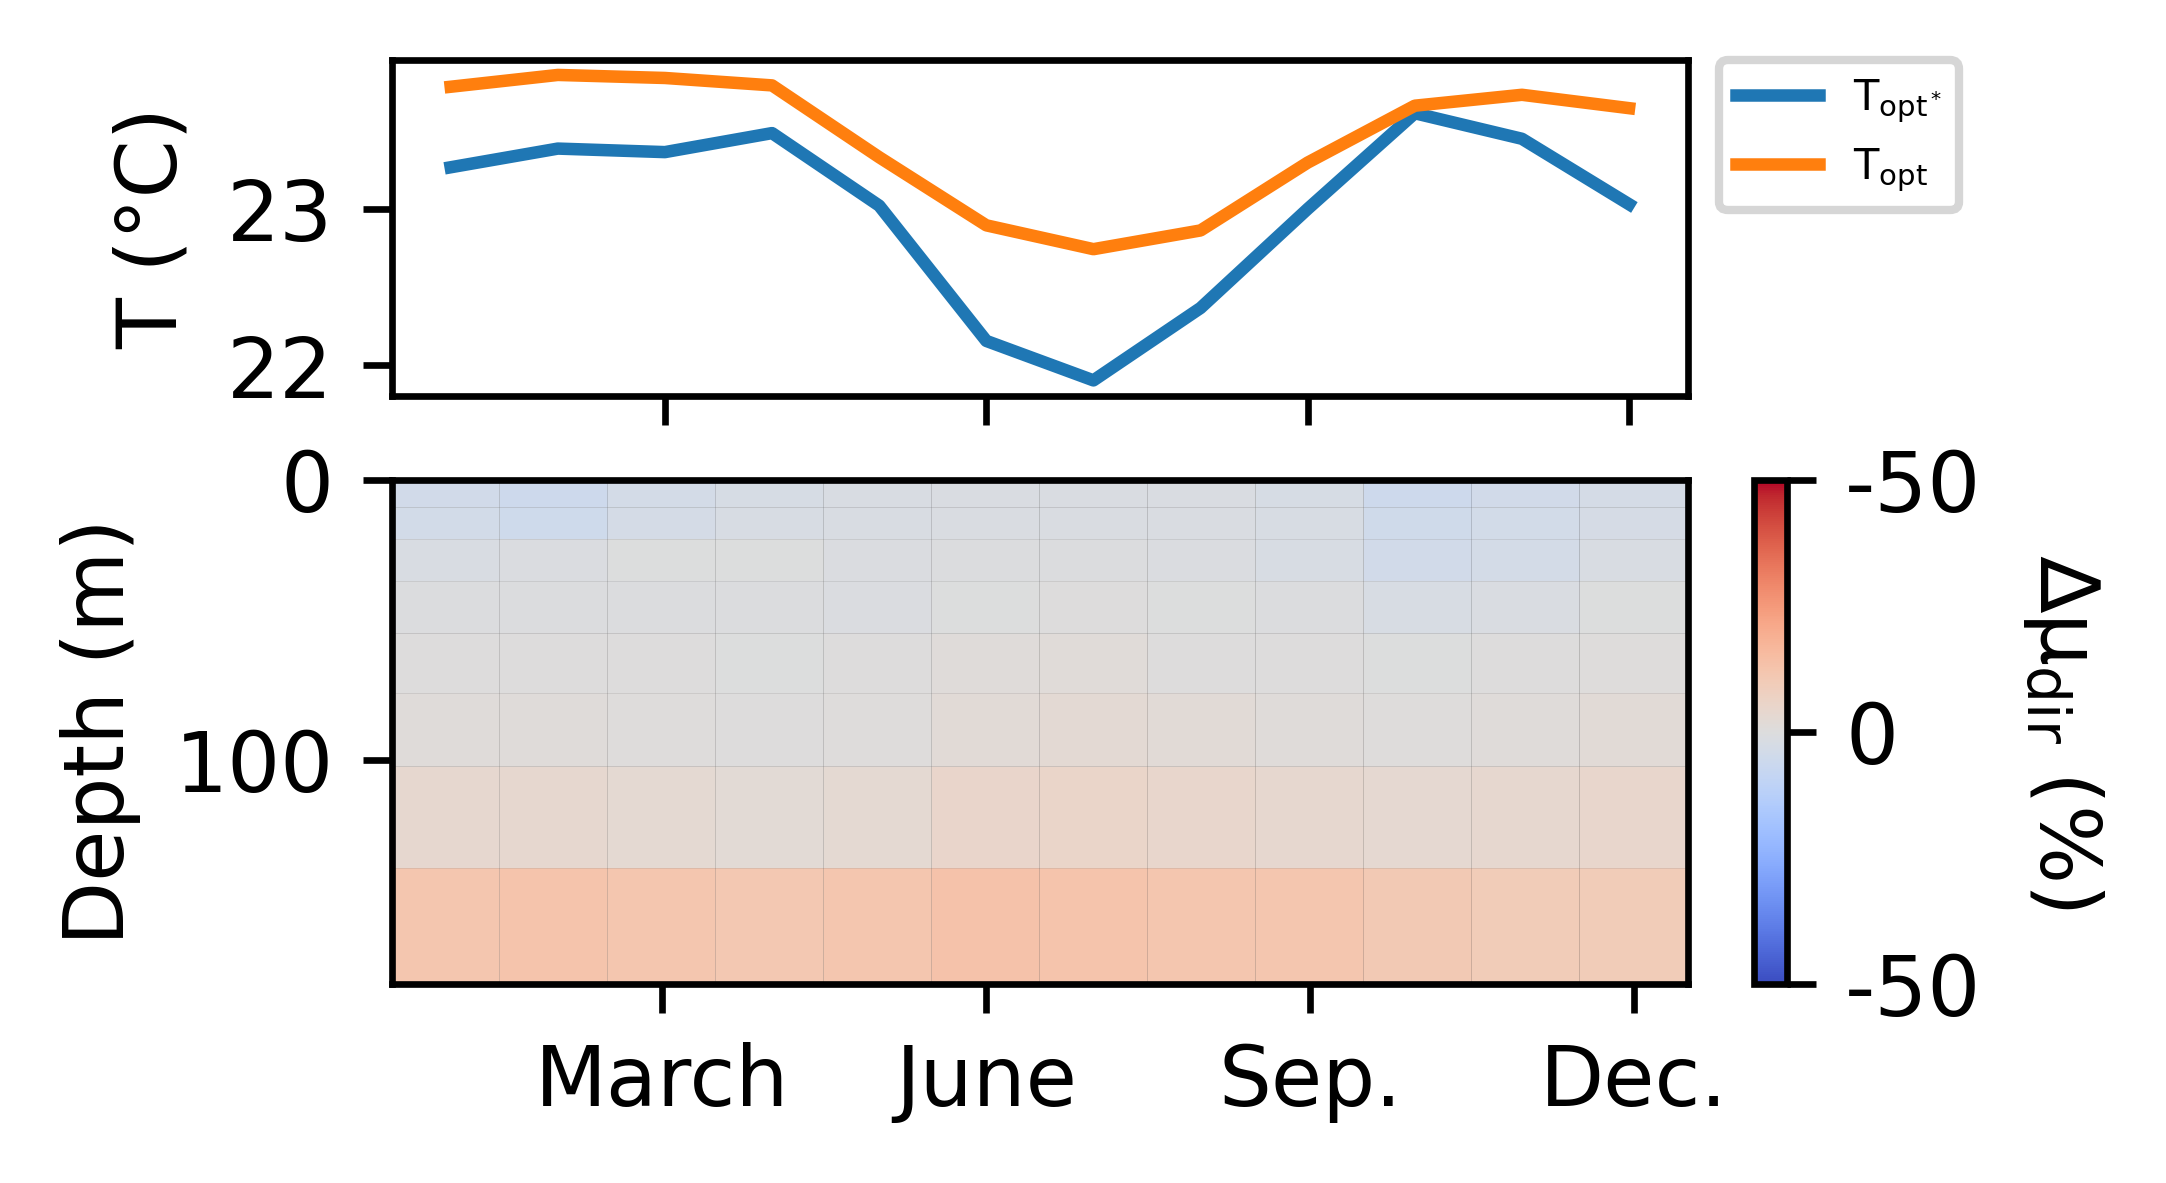

In [226]:
fig = plt.figure(figsize=(3,2))

gs = GridSpec(2, 2,width_ratios=[1, 0.025],height_ratios=[2, 3])

ax1 = fig.add_subplot(gs[0,0])
ax1.plot(SST_NA_z-(0.056*(5.)**2.)/(0.056*5. - 1.),label='T$_{\mathrm{opt}^*}$')
ax1.plot(Topt_NA_z,label='T$_{\mathrm{opt}}$')
ax1.set_xticks([11,2,5,8])
ax1.set_xticklabels([])
ax1.set_ylabel('T (°C)')
plt.legend(fontsize=5,bbox_to_anchor=(1.225, 0, 0, 1.06))

ax2 = fig.add_subplot(gs[1,0])
pc = ax2.pcolor(np.arange(12),middle,Floss_T_dir[:,:,la,lo].T,vmin=-0.5,vmax=0.5,cmap='coolwarm',edgecolor='black',lw=0.01)
ax2.set_ylim(180,0)
ax2.set_ylabel('Depth (m)')
ax2.set_xticks([11,2,5,8])
ax2.set_xticklabels(['Dec.','March','June','Sep.'])
axcb = fig.add_subplot(gs[1,1])
cb = fig.colorbar(pc,axcb)
axcb.set_yticks([-0.5,0,0.5])
axcb.set_yticklabels([-50,0,-50])
axcb.set_ylabel('∆µ$_{\mathrm{dir}}$ (%)',rotation=-90,labelpad=15)

fig.subplots_adjust(wspace=0.1)
#fig.tight_layout()

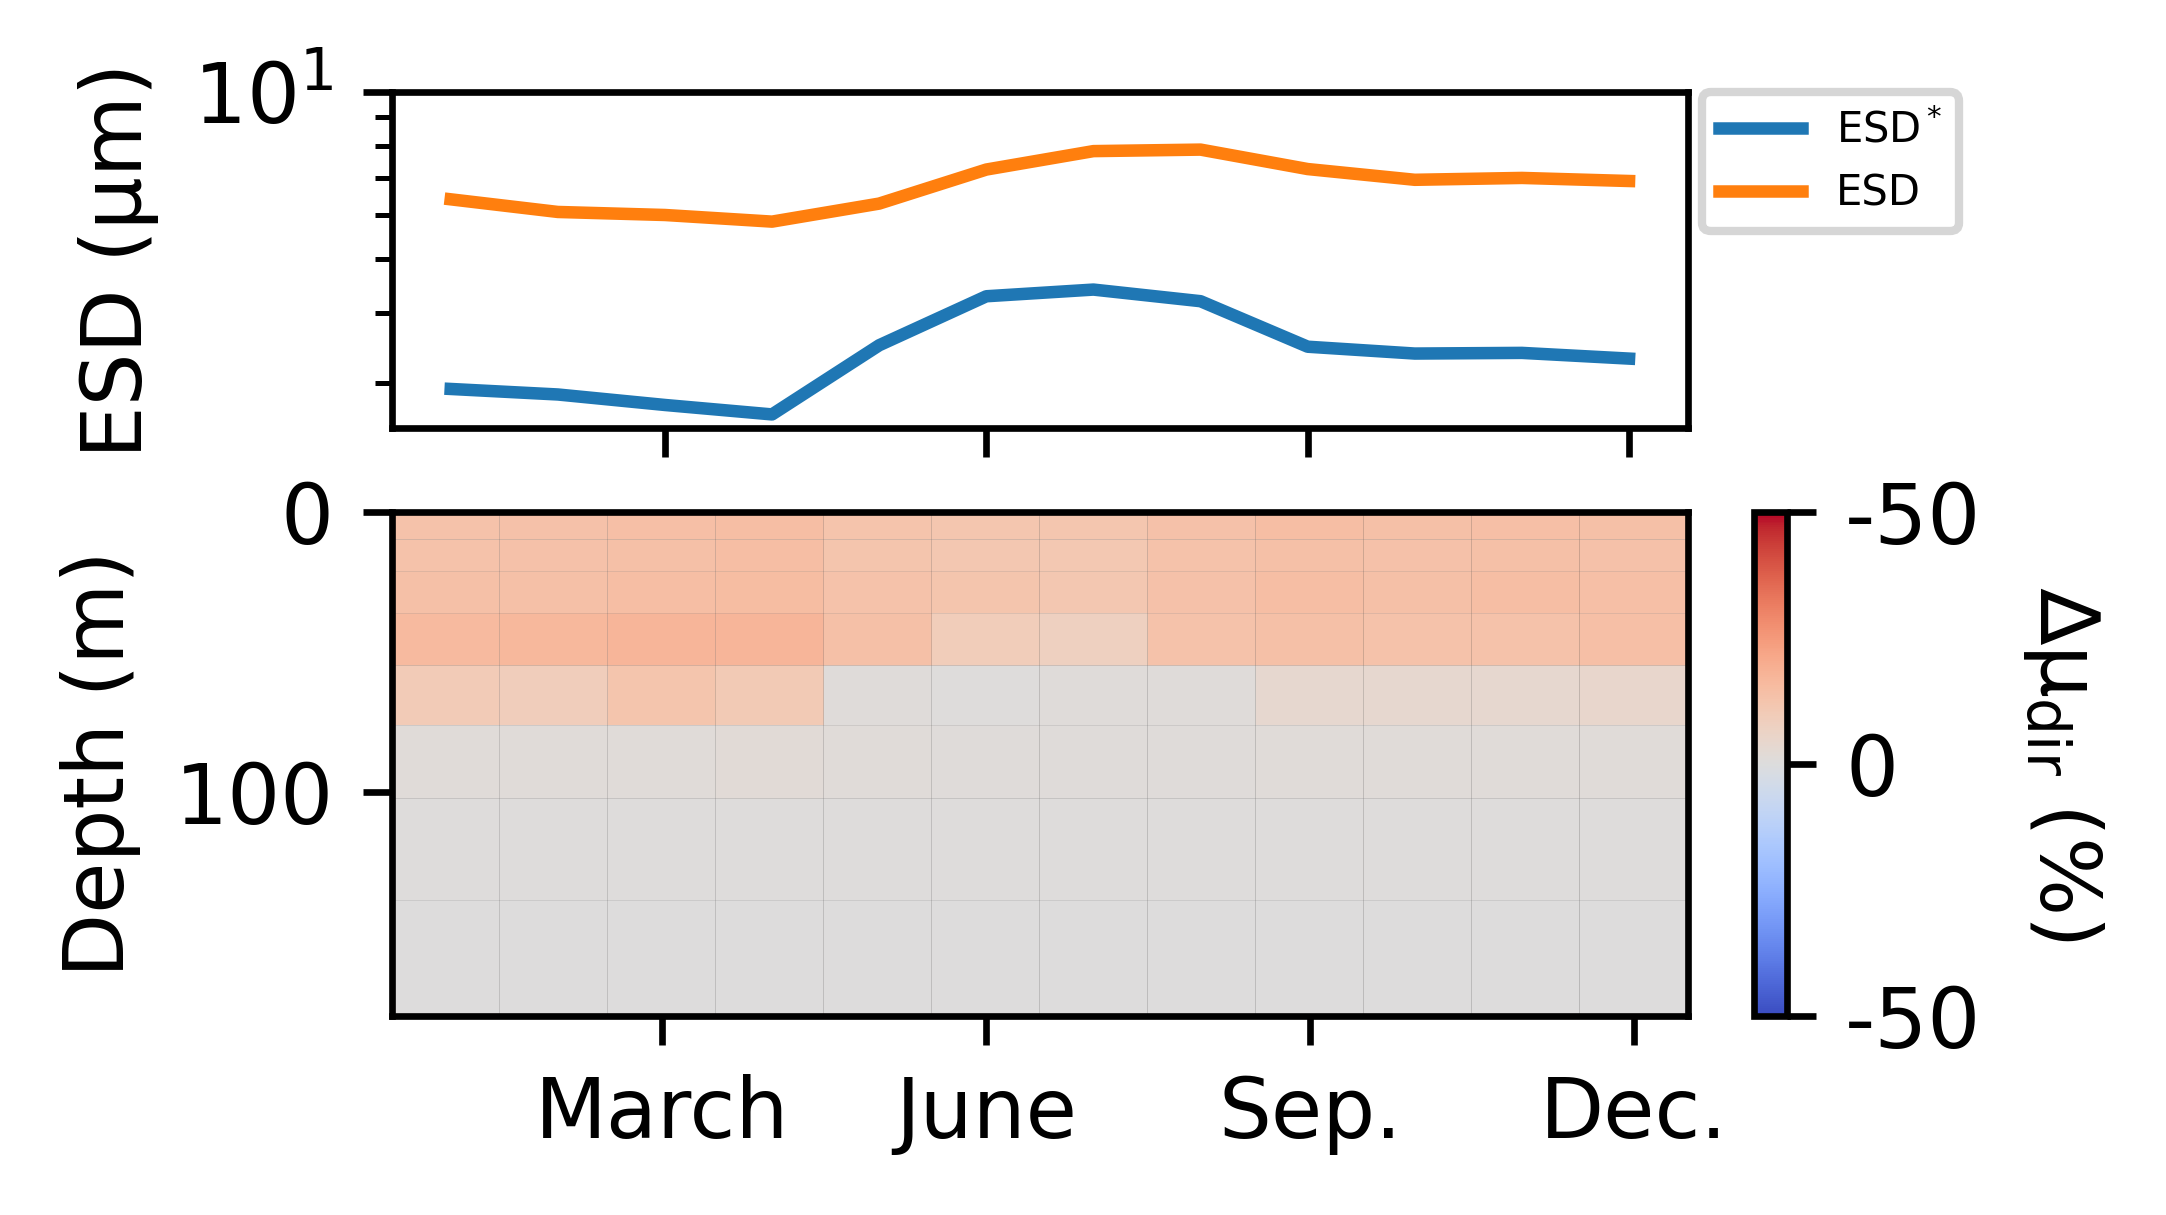

In [227]:
fig = plt.figure(figsize=(3,2))

gs = GridSpec(2, 2,width_ratios=[1, 0.025],height_ratios=[2, 3])

ax1 = fig.add_subplot(gs[0,0])
ax1.plot(ESD_opt_NA_z,label='ESD$^*$')
ax1.plot(ESD_NA_z,label='ESD')
ax1.set_yscale('log')
ax1.set_yticks([10])
ax1.set_yticklabels([],minor=True)
ax1.set_xticks([11,2,5,8])
ax1.set_xticklabels([])
ax1.set_ylabel('ESD (µm)')
plt.legend(fontsize=5,bbox_to_anchor=(1.225, 0, 0, 1.06))

ax2 = fig.add_subplot(gs[1,0])
pc = ax2.pcolor(np.arange(12),middle,Floss_S_dir[:,:,la,lo].T,vmin=-0.5,vmax=0.5,cmap='coolwarm',edgecolor='black',lw=0.01)
ax2.set_ylim(180,0)
ax2.set_ylabel('Depth (m)')
ax2.set_xticks([11,2,5,8])
ax2.set_xticklabels(['Dec.','March','June','Sep.'])
axcb = fig.add_subplot(gs[1,1])
cb = fig.colorbar(pc,axcb)
axcb.set_yticks([-0.5,0,0.5])
axcb.set_yticklabels([-50,0,-50])
axcb.set_ylabel('∆µ$_{\mathrm{dir}}$ (%)',rotation=-90,labelpad=15)

fig.subplots_adjust(wspace=0.1)
#fig.tight_layout()

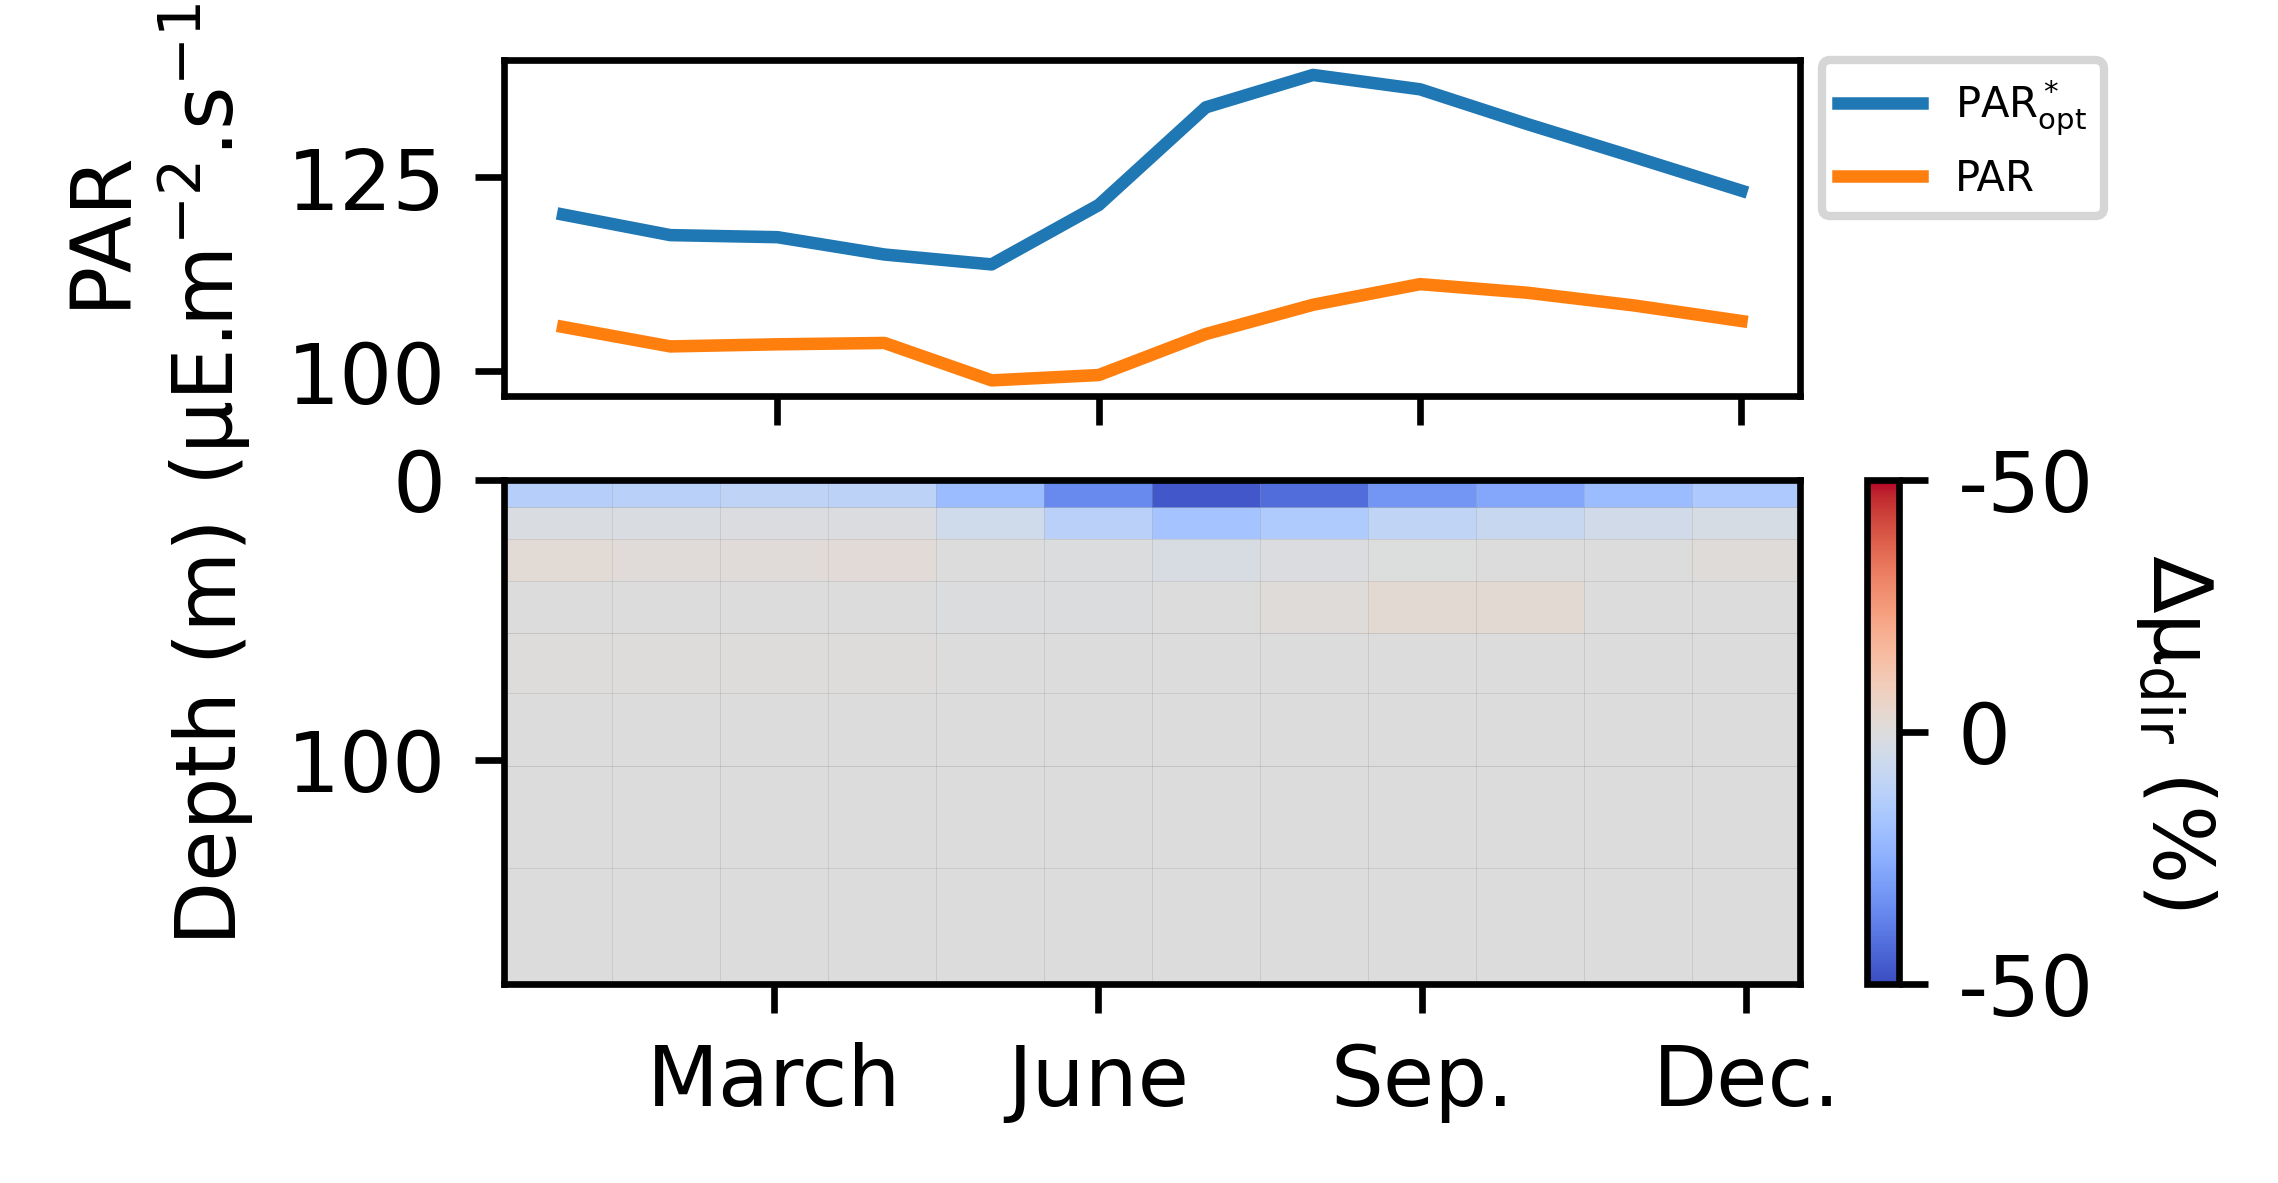

In [228]:
fig = plt.figure(figsize=(3,2))

gs = GridSpec(2, 2,width_ratios=[1, 0.025],height_ratios=[2, 3])

ax1 = fig.add_subplot(gs[0,0])
ax1.plot(Lopt_star_NA_z,label='PAR$_{\mathrm{opt}}^*$')
ax1.plot(np.exp(Lopt_NA_z),label='PAR')
#ax1.set_yscale('log')
#ax1.set_yticks([10])
#ax1.set_yticklabels([],minor=True)
ax1.set_xticks([11,2,5,8])
ax1.set_xticklabels([])
ax1.set_ylabel('PAR\n(µE.m$^{-2}$.s$^{-1}$)')
plt.legend(fontsize=5,bbox_to_anchor=(1.25, 0, 0, 1.06))

ax2 = fig.add_subplot(gs[1,0])
pc = ax2.pcolor(np.arange(12),middle,Floss_L_dir[:,:,la,lo].T,vmin=-0.5,vmax=0.5,cmap='coolwarm',edgecolor='black',lw=0.01)
ax2.set_ylim(180,0)
ax2.set_ylabel('Depth (m)')
ax2.set_xticks([11,2,5,8])
ax2.set_xticklabels(['Dec.','March','June','Sep.'])
axcb = fig.add_subplot(gs[1,1])
cb = fig.colorbar(pc,axcb)
axcb.set_yticks([-0.5,0,0.5])
axcb.set_yticklabels([-50,0,-50])
axcb.set_ylabel('∆µ$_{\mathrm{dir}}$ (%)',rotation=-90,labelpad=15)

fig.subplots_adjust(wspace=0.1)
plt.savefig('temp.png',bbox_inches='tight',pad_inches=0.2)
#fig.tight_layout()

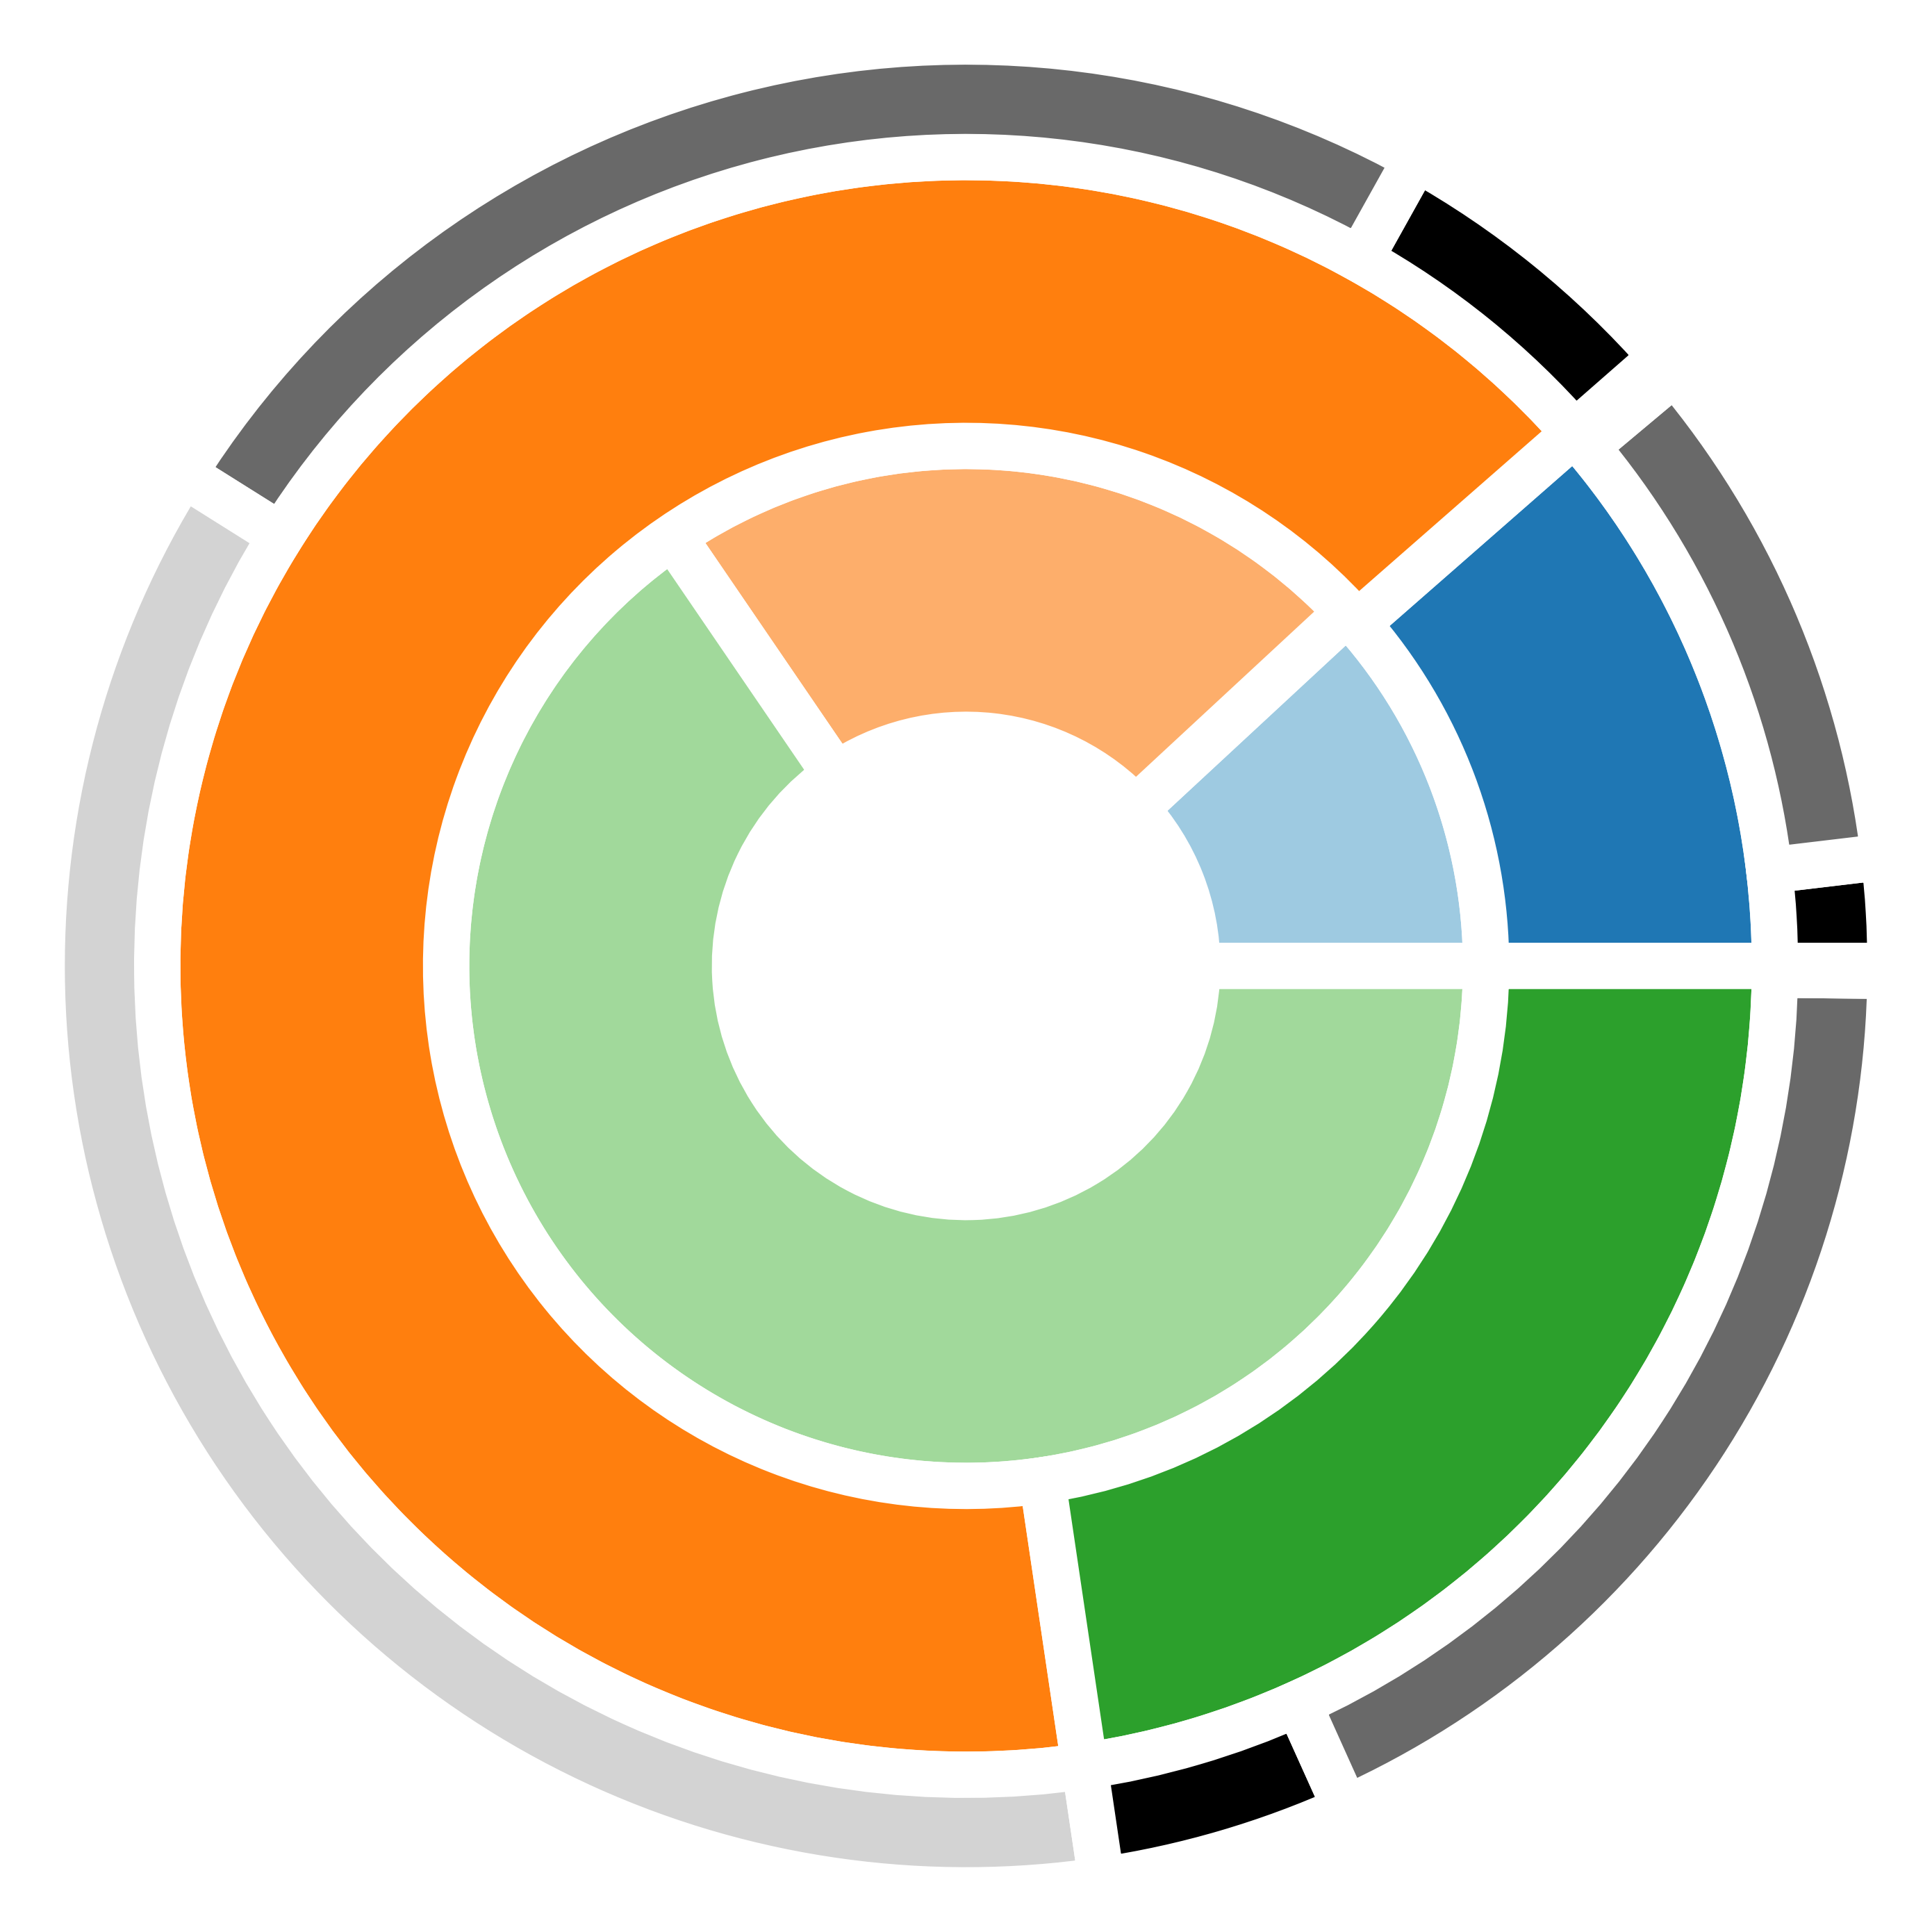

In [229]:
fig = plt.figure(facecolor='None')

val1 = [DF_pop_T_zt[la,lo],DF_pop_N_zt[la,lo],DF_pop_L_zt[la,lo]]
val0 = [DF_pop_Topt_zt[la,lo],DF_pop_S_zt[la,lo],DF_pop_Lopt_zt[la,lo]]
val2 = (np.array([DF_var_t_T[la,lo],DF_var_z_T[la,lo],DF_moy_T[la,lo]])*DF_pop_Topt_zt[la,lo]).tolist()+(np.array([DF_var_t_S[la,lo],DF_var_z_S[la,lo],DF_moy_S[la,lo]])*DF_pop_S_zt[la,lo]).tolist()+(np.array([DF_var_t_L[la,lo],DF_var_z_L[la,lo],DF_moy_L[la,lo]])*DF_pop_Lopt_zt[la,lo]).tolist()

inner_col = [tab20c[i] for i in [2,6,10]]
col2 = ['black','dimgrey','lightgrey']*3
wedges,  texts  = plt.pie(val1, radius=0.9, wedgeprops=dict(width=0.5,edgecolor='w',linewidth=8),colors=inner_col)
wedges2, texts2 = plt.pie(val0, radius=1.4, wedgeprops=dict(width=0.5,edgecolor='w',linewidth=8))
wedges3, texts3 = plt.pie(val2, radius=1.6, wedgeprops=dict(width=0.2,edgecolor='w',linewidth=8),colors=col2)
#wedges2, texts2 = plt.pie(val2, radius=1.4, wedgeprops=dict(width=0.5,edgecolor='w',linewidth=10),colors=outer_col)

#plt.legend(wedges2,outer_lab,bbox_to_anchor=(1.25, 0, 0.5, 1.05),frameon=False,fontsize=16.5)
#plt.legend(wedges ,inner_lab,bbox_to_anchor=(1.25, 0, 0.5, 0.55),frameon=False,fontsize=16.5)
fig.tight_layout()
plt.show()

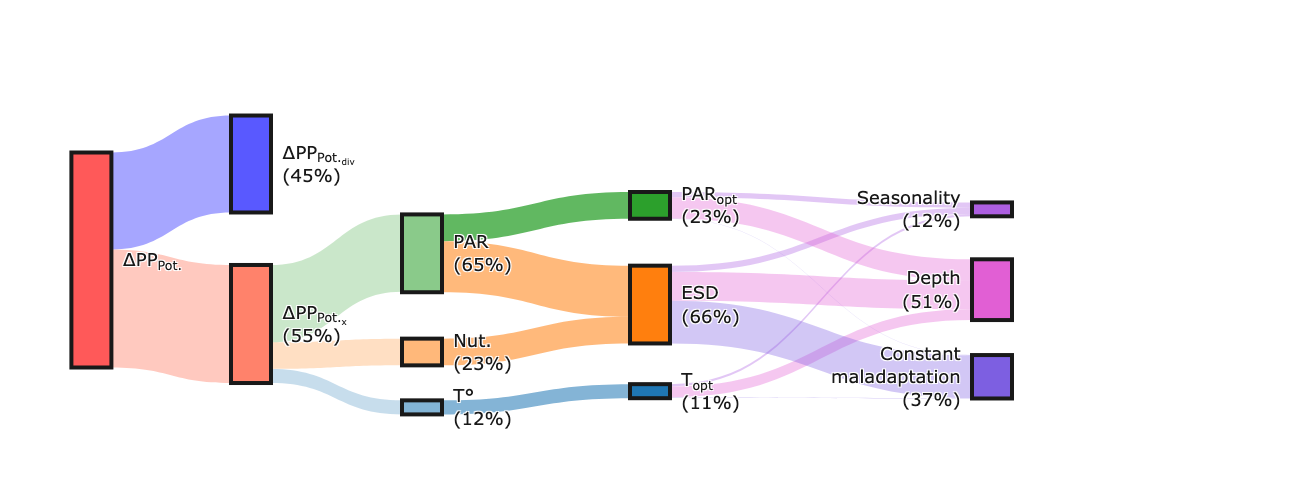

In [230]:
col2 = ['#AD5FE1','#E15FD4','#7D5FE1']

vec = [np.array((val1[0], val1[1], val1[2]))[i] for i in [2,1,0]]/np.sum(val1)
y1  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(2)]
y1  = [y1[i] for i in [2,1,0]]
vec = [np.array((val0[0], val0[1], val0[2]))[i] for i in [2,1,0]]/np.sum(val0)
y2  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(2)]
y2  = [y2[i] for i in [2,1,0]]
vec = [np.array([np.sum(val2[i::4]/np.sum(val2)) for i in np.arange(4)])[i] for i in [0,1,2]]
y3  = [vec[0]/2]+[(np.sum(vec[:i+1])+np.sum(vec[:i+2]))/2 for i in np.arange(3)]
y3  = [y3[i] for i in [0,1,2]]

y1c = recenter(y1, target=0.6, scale=0.7)
y2c = recenter(y2, target=0.6, scale=0.7)
y3c = recenter(y3, target=0.6, scale=0.7)

contrib = np.array([val1/np.sum(val1),val0/np.sum(val1),np.array([np.sum(val2[i::3])/np.sum(val1) for i in range(3)])]).ravel()

# --- NOUVEAU : valeurs / apparence des deux nodes ajoutés ---
val_root   = [np.sum(val0), -DF_div_pop_zt[la,lo]-np.sum(val0)]      # <- valeur du lien "nouveau racine -> node0" et "nouveau racine -> node aligné"
contrib_root = -np.array(val_root)/DF_div_pop_zt[la,lo]
label_root = " ∆PP<sub>Pot.</sub> "      # <- à adapter
label_sib  = " ∆PP<sub>Pot.<sub>div</sub></sub> <br> ("+str(int(round(contrib_root[1]*100,0)))+"%) "  # <- à adapter
color_root = pastel('grey', 0.2, 1)   # <- à adapter
color_sib  = pastel('grey', 0.45, 1)  # <- à adapter
y_root     = 0.5    # position verticale du node tout à gauche
y_sib      = 0.2   # position verticale du node "frère" du node0 (à ajuster selon tes valeurs)
# --------------------------------------------------------------

fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node = dict(
      pad = 35,
      thickness = 40,
      line = dict(color = pastel('black',0.1,1), width = 4),
      label = [" ∆PP<sub>Pot.<sub>x</sub></sub> <br> ("+str(int(round(contrib_root[0]*100,0)))+"%) "," T° <br> ("+str(int(round(contrib[0]*100,0)))+"%) ", " Nut. <br> ("+str(int(round(contrib[1]*100,0)))+"%) ", " PAR <br> ("+str(int(round(contrib[2]*100,0)))+"%) ", " T<sub>opt</sub> <br> ("+str(int(round(contrib[3]*100,0)))+"%) ", " ESD <br> ("+str(int(round(contrib[4]*100,0)))+"%) ", " PAR<sub>opt</sub> <br> ("+str(int(round(contrib[5]*100,0)))+"%) ", "Seasonality <br>("+str(int(round(contrib[6]*100,0)))+"%) ","Depth <br>("+str(int(round(contrib[7]*100,0)))+"%) ","Constant <br>maladaptation <br>("+str(int(round(contrib[8]*100,0)))+"%) ",label_root,label_sib],
      color = [pastel('tomato',0.2,1)]+[pastel(base_col[i], 0.45) for i in range(len(base_col))]+base_col+col2+[pastel('red',0.,alpha=0.65),pastel('blue',0.,alpha=0.65)],
      x = [0.15,0.3,0.3,0.3,0.5,0.5,0.5,0.8,0.8,0.8,0.01,0.15],
      y = [0.7]+y1c+y2c+y3c+[y_root, y_sib]
      ),
    link = dict(
      source = [10,10,0, 0, 0, 1, 2, 3, 3, 4, 4, 4, 5, 5, 5, 6, 6, 6],
      target = [ 0,11,1, 2, 3, 4, 5, 5, 6, 7, 8, 9, 7, 8, 9, 7, 8, 9],
      value  = val_root+[val1[0], val1[1], val1[2], val1[0], val1[1], val0[1]-val1[1], val0[2]]+val2,
      color  = [pastel('tomato',0.,0.35), pastel('blue',0.,alpha=0.35)]+[pastel(base_col[0], 0., alpha=0.25),pastel(base_col[1], 0., alpha=0.25),pastel(base_col[2], 0., alpha=0.25),
                pastel(base_col[0], 0., alpha=0.55),pastel(base_col[1], 0., alpha=0.55),pastel(base_col[1], 0., alpha=0.55),pastel(base_col[2], 0., alpha=0.75)]
               +[pastel(col2[0], 0.,alpha=0.35),pastel(col2[1], 0.,alpha=0.35),pastel(col2[2], 0.,alpha=0.35)]*3
               ,
      line = dict(color = pastel('black',0,0.), width = 0.25),
  ))])


fig.update_layout(font=dict(color=pastel('black',0.1,1)), font_size=18,width=1100,height=500)
fig.show()
fig.write_image("fig1.png",scale=6)

# PP comparisons

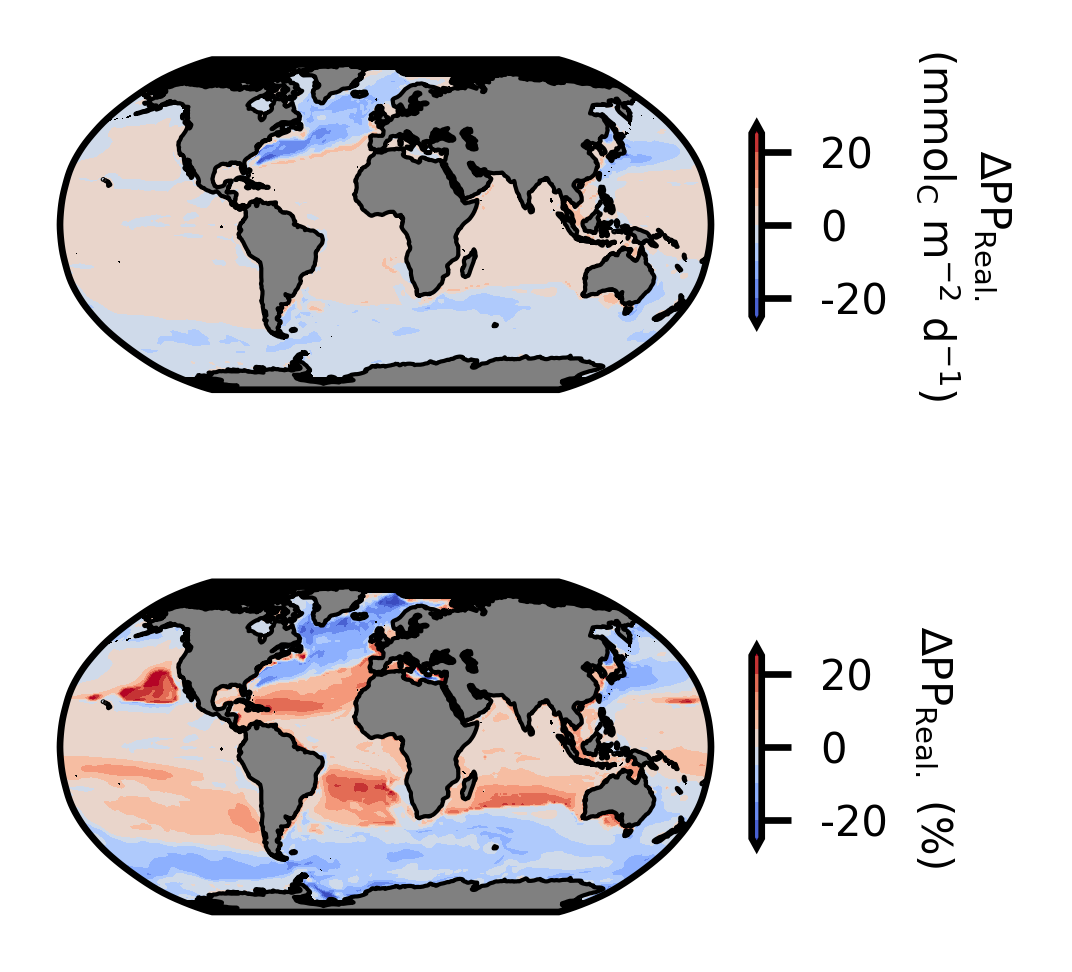

In [231]:
fig = plt.figure(figsize=((1.75,2)))

ax1 = fig.add_subplot(211,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
cf = ax1.contourf(lon,lat_reel[:-1],(FPP_mutALL_zt-FPP_DDTLS_zt)*60*60*24,np.linspace(-25,25,11),cmap='coolwarm',extend='both',transform=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='grey', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(cf,shrink=0.5,orientation='vertical',pad=0.05)
c1.ax.set_yticks([-20,0,20])
c1.ax.set_yticklabels([-20,0,20],fontsize=5)
c1.ax.set_ylabel('∆PP$_{\mathrm{Real.}}$\n(mmol$_\mathrm{C}$ m$^{-2}$ d$^{-1}$)',rotation=-90,fontsize=5,labelpad=15)
ax1.set_global()

ax1 = fig.add_subplot(212,facecolor='black',projection=ccrs.Robinson(central_longitude=0))
cf = ax1.contourf(lon,lat_reel[:-1],(FPP_mutALL_zt-FPP_DDTLS_zt)/FPP_DDTLS_zt*100,np.linspace(-25,25,11),cmap='coolwarm',extend='both',transform=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='grey', edgecolor='black', linewidth=0.5, zorder=2)
c1 = fig.colorbar(cf,shrink=0.5,orientation='vertical',pad=0.05)
c1.ax.set_yticks([-20,0,20])
c1.ax.set_yticklabels([-20,0,20],fontsize=5)
c1.ax.set_ylabel('∆PP$_{\mathrm{Real.}}$ (%)',rotation=-90,fontsize=5,labelpad=8)
ax1.set_global()

fig.subplots_adjust(hspace=0.3,wspace=0)